# TRI2I TIR → RGB — Colab Pipeline

This notebook restores the TRI2I dataset from an uploaded ZIP, verifies the dataset, creates the 800/100/100 small test set, prepares the pix2pix aligned data, trains a 2-epoch pipeline test, verifies the checkpoint, and runs inference.

**Do not start full 148,829-pair training until the small inference pipeline is verified.**

In [ ]:
!nvidia-smi

/bin/bash: line 1: nvidia-smi: command not found


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
CUDA available: True
CUDA version: 13.0
GPU: Tesla T4


In [ ]:
!pip uninstall -y torch torchvision torchaudio

Found existing installation: torch 2.11.0+cu130
Uninstalling torch-2.11.0+cu130:
  Successfully uninstalled torch-2.11.0+cu130
Found existing installation: torchvision 0.26.0+cu130
Uninstalling torchvision-0.26.0+cu130:
  Successfully uninstalled torchvision-0.26.0+cu130
Found existing installation: torchaudio 2.11.0+cu130
Uninstalling torchaudio-2.11.0+cu130:
  Successfully uninstalled torchaudio-2.11.0+cu130


In [ ]:
!pip install torch torchvision torchaudio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 7.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 16.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 49.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 54.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 7.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 53.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.5/59.5 MB 14.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.9/2

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA:", torch.version.cuda)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA available: True
CUDA: 13.0
GPU: Tesla T4


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("❌ GPU is NOT attached")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
CUDA version: 13.0


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError(
        "GPU is not available. Please enable GPU in Runtime → Change runtime type."
    )

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         108G   21G   88G  20% /


Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/dataset_1-6-2024.zip"

print("File exists:", os.path.exists(zip_path))
print("File size:", round(os.path.getsize(zip_path) / (1024**3), 2), "GB")

with zipfile.ZipFile(zip_path, "r") as z:
    bad_file = z.testzip()

    if bad_file is None:
        print("ZIP INTEGRITY: OK")
    else:
        print("CORRUPTED FILE:", bad_file)

File exists: True
File size: 5.44 GB
ZIP INTEGRITY: OK


In [ ]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/dataset_1-6-2024.zip"

print("ZIP exists:", os.path.exists(zip_path))
print("ZIP size:", round(os.path.getsize(zip_path) / (1024**3), 2), "GB")

with zipfile.ZipFile(zip_path, "r") as z:
    # Check integrity
    bad_file = z.testzip()

    if bad_file is None:
        print("ZIP integrity: OK")
    else:
        print("ZIP integrity: CORRUPTED")
        print("Problem file:", bad_file)

    # Show first 30 paths inside the ZIP
    print("\nFirst files/directories inside ZIP:")
    for name in z.namelist()[:30]:
        print(name)

ZIP exists: True
ZIP size: 5.44 GB
ZIP integrity: OK

First files/directories inside ZIP:
dataset_1-6-2024/class1/
dataset_1-6-2024/class1/10000.jpg
dataset_1-6-2024/class1/100000.jpg
dataset_1-6-2024/class1/100001.jpg
dataset_1-6-2024/class1/100002.jpg
dataset_1-6-2024/class1/100003.jpg
dataset_1-6-2024/class1/100004.jpg
dataset_1-6-2024/class1/100005.jpg
dataset_1-6-2024/class1/100006.jpg
dataset_1-6-2024/class1/100007.jpg
dataset_1-6-2024/class1/100008.jpg
dataset_1-6-2024/class1/100009.jpg
dataset_1-6-2024/class1/10001.jpg
dataset_1-6-2024/class1/100010.jpg
dataset_1-6-2024/class1/100011.jpg
dataset_1-6-2024/class1/100012.jpg
dataset_1-6-2024/class1/100013.jpg
dataset_1-6-2024/class1/100014.jpg
dataset_1-6-2024/class1/100015.jpg
dataset_1-6-2024/class1/100016.jpg
dataset_1-6-2024/class1/100017.jpg
dataset_1-6-2024/class1/100018.jpg
dataset_1-6-2024/class1/100019.jpg
dataset_1-6-2024/class1/10002.jpg
dataset_1-6-2024/class1/100020.jpg
dataset_1-6-2024/class1/100021.jpg
dataset_1-6-2

In [ ]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/dataset_1-6-2024.zip"
extract_path = "/content/TRI2I_dataset"

os.makedirs(extract_path, exist_ok=True)

print("Extracting TRI2I dataset...")
print("This may take some time because the dataset is large.")

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("\nExtraction completed.")
print("Contents of extraction directory:")

for item in os.listdir(extract_path):
    print(" -", item)

Extracting TRI2I dataset...
This may take some time because the dataset is large.

Extraction completed.
Contents of extraction directory:
 - dataset_1-6-2024


In [ ]:
import os

base = "/content/TRI2I_dataset"

for root, dirs, files in os.walk(base):
    level = root.replace(base, "").count(os.sep)

    if level <= 2:
        print(
            f"{'  ' * level}{os.path.basename(root)}/ "
            f"({len(files)} files)"
        )

TRI2I_dataset/ (0 files)
  dataset_1-6-2024/ (0 files)
    class1/ (148829 files)
    class2/ (148829 files)


In [ ]:
import os

base = "/content/TRI2I_dataset"

class1_paths = []
class2_paths = []

for root, dirs, files in os.walk(base):
    if os.path.basename(root) == "class1":
        class1_paths.append(root)
    elif os.path.basename(root) == "class2":
        class2_paths.append(root)

print("class1 folders:")
for p in class1_paths:
    print(p)

print("\nclass2 folders:")
for p in class2_paths:
    print(p)

class1 folders:
/content/TRI2I_dataset/dataset_1-6-2024/class1

class2 folders:
/content/TRI2I_dataset/dataset_1-6-2024/class2


In [ ]:
import os

class1 = class1_paths[0]
class2 = class2_paths[0]

class1_files = [
    f for f in os.listdir(class1)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

class2_files = [
    f for f in os.listdir(class2)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

print("class1 image count:", len(class1_files))
print("class2 image count:", len(class2_files))

class1 image count: 148829
class2 image count: 148829


In [ ]:
set1 = set(class1_files)
set2 = set(class2_files)

only_class1 = set1 - set2
only_class2 = set2 - set1
common = set1 & set2

print("Common filenames:", len(common))
print("Only in class1:", len(only_class1))
print("Only in class2:", len(only_class2))

if len(only_class1) == 0 and len(only_class2) == 0:
    print("\nPAIRING CHECK: PASSED")
else:
    print("\nPAIRING CHECK: FAILED")

Common filenames: 148829
Only in class1: 0
Only in class2: 0

PAIRING CHECK: PASSED


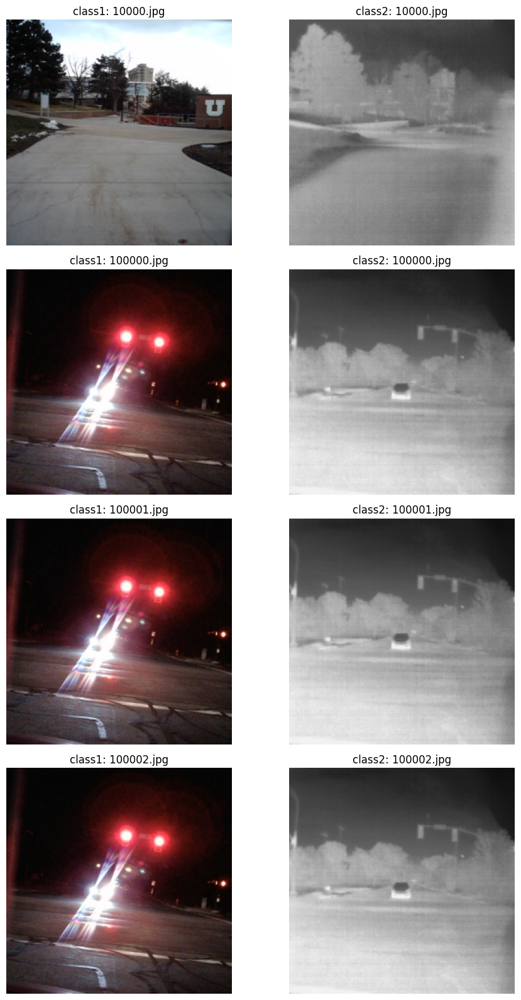

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

# Take 4 common filenames
sample_files = sorted(list(common))[:4]

fig, axes = plt.subplots(len(sample_files), 2, figsize=(10, 4 * len(sample_files)))

for i, filename in enumerate(sample_files):

    class1_img = Image.open(os.path.join(class1, filename))
    class2_img = Image.open(os.path.join(class2, filename))

    axes[i, 0].imshow(class1_img)
    axes[i, 0].set_title(f"class1: {filename}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(class2_img)
    axes[i, 1].set_title(f"class2: {filename}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from PIL import Image
import os
from collections import Counter

sample_files = sorted(list(common))[:100]

class1_sizes = Counter()
class2_sizes = Counter()
class1_modes = Counter()
class2_modes = Counter()
class1_formats = Counter()
class2_formats = Counter()

for filename in sample_files:
    path1 = os.path.join(class1, filename)
    path2 = os.path.join(class2, filename)

    with Image.open(path1) as img1:
        class1_sizes[img1.size] += 1
        class1_modes[img1.mode] += 1
        class1_formats[img1.format] += 1

    with Image.open(path2) as img2:
        class2_sizes[img2.size] += 1
        class2_modes[img2.mode] += 1
        class2_formats[img2.format] += 1

print("CLASS1")
print("Sizes:", class1_sizes)
print("Modes:", class1_modes)
print("Formats:", class1_formats)

print("\nCLASS2")
print("Sizes:", class2_sizes)
print("Modes:", class2_modes)
print("Formats:", class2_formats)

CLASS1
Sizes: Counter({(256, 256): 100})
Modes: Counter({'RGB': 100})
Formats: Counter({'JPEG': 100})

CLASS2
Sizes: Counter({(256, 256): 100})
Modes: Counter({'RGB': 100})
Formats: Counter({'JPEG': 100})


In [ ]:
from PIL import Image
import os
from tqdm.auto import tqdm

def check_images(folder):
    bad = []

    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    for filename in tqdm(files, desc=os.path.basename(folder)):
        path = os.path.join(folder, filename)

        try:
            with Image.open(path) as img:
                img.verify()
        except Exception as e:
            bad.append((filename, str(e)))

    return bad


bad_class1 = check_images(class1)
bad_class2 = check_images(class2)

print("\nClass1 corrupted:", len(bad_class1))
print("Class2 corrupted:", len(bad_class2))

if len(bad_class1) == 0 and len(bad_class2) == 0:
    print("CORRUPTION CHECK: PASSED")
else:
    print("CORRUPTION CHECK: FAILED")

    print("\nClass1 examples:", bad_class1[:10])
    print("Class2 examples:", bad_class2[:10])

class1:   0%|          | 0/148829 [00:00<?, ?it/s]

class2:   0%|          | 0/148829 [00:00<?, ?it/s]


Class1 corrupted: 0
Class2 corrupted: 0
CORRUPTION CHECK: PASSED


In [ ]:
from PIL import Image
import os
from tqdm.auto import tqdm

mismatched_pairs = []

for filename in tqdm(sorted(common), desc="Checking paired dimensions"):

    path1 = os.path.join(class1, filename)
    path2 = os.path.join(class2, filename)

    with Image.open(path1) as img1:
        size1 = img1.size

    with Image.open(path2) as img2:
        size2 = img2.size

    if size1 != size2:
        mismatched_pairs.append((filename, size1, size2))

print("\nTotal mismatched pairs:", len(mismatched_pairs))

if len(mismatched_pairs) == 0:
    print("PAIR DIMENSION CHECK: PASSED")
else:
    print("PAIR DIMENSION CHECK: FAILED")
    print("Examples:", mismatched_pairs[:10])

Checking paired dimensions:   0%|          | 0/148829 [00:00<?, ?it/s]


Total mismatched pairs: 0
PAIR DIMENSION CHECK: PASSED


In [ ]:
print("=" * 50)
print("TRI2I DATASET SUMMARY")
print("=" * 50)

print(f"Total paired images : {len(common):,}")
print(f"Class1 images       : {len(class1_files):,}")
print(f"Class2 images       : {len(class2_files):,}")
print(f"Corrupted class1    : {len(bad_class1):,}")
print(f"Corrupted class2    : {len(bad_class2):,}")
print(f"Dimension mismatch  : {len(mismatched_pairs):,}")

print("\nDataset location:")
print(base)

print("\nClass1:")
print(class1)

print("\nClass2:")
print(class2)

TRI2I DATASET SUMMARY
Total paired images : 148,829
Class1 images       : 148,829
Class2 images       : 148,829
Corrupted class1    : 0
Corrupted class2    : 0
Dimension mismatch  : 0

Dataset location:
/content/TRI2I_dataset

Class1:
/content/TRI2I_dataset/dataset_1-6-2024/class1

Class2:
/content/TRI2I_dataset/dataset_1-6-2024/class2


In [ ]:
# Inspect how TRI2I filenames are structured

sorted_files = sorted(list(common))

print("Total filenames:", len(sorted_files))

print("\nFirst 30 filenames:")
for f in sorted_files[:30]:
    print(f)

print("\nLast 30 filenames:")
for f in sorted_files[-30:]:
    print(f)

Total filenames: 148829

First 30 filenames:
10000.jpg
100000.jpg
100001.jpg
100002.jpg
100003.jpg
100004.jpg
100005.jpg
100006.jpg
100007.jpg
100008.jpg
100009.jpg
10001.jpg
100010.jpg
100011.jpg
100012.jpg
100013.jpg
100014.jpg
100015.jpg
100016.jpg
100017.jpg
100018.jpg
100019.jpg
10002.jpg
100020.jpg
100021.jpg
100022.jpg
100023.jpg
100024.jpg
100025.jpg
100026.jpg

Last 30 filenames:
99972.jpg
99973.jpg
99974.jpg
99975.jpg
99976.jpg
99977.jpg
99978.jpg
99979.jpg
9998.jpg
99980.jpg
99981.jpg
99982.jpg
99983.jpg
99984.jpg
99985.jpg
99986.jpg
99987.jpg
99988.jpg
99989.jpg
9999.jpg
99990.jpg
99991.jpg
99992.jpg
99993.jpg
99994.jpg
99995.jpg
99996.jpg
99997.jpg
99998.jpg
99999.jpg


In [ ]:
import re

numeric_files = []
non_numeric_files = []

for f in sorted_files:
    stem = os.path.splitext(f)[0]

    if stem.isdigit():
        numeric_files.append(int(stem))
    else:
        non_numeric_files.append(f)

print("Numeric filenames:", len(numeric_files))
print("Non-numeric filenames:", len(non_numeric_files))

if numeric_files:
    print("\nMinimum ID:", min(numeric_files))
    print("Maximum ID:", max(numeric_files))

if non_numeric_files:
    print("\nExamples of non-numeric filenames:")
    print(non_numeric_files[:20])

Numeric filenames: 148829
Non-numeric filenames: 0

Minimum ID: 1443
Maximum ID: 151373


In [ ]:
numeric_ids = sorted(numeric_files)

gaps = []

for a, b in zip(numeric_ids, numeric_ids[1:]):
    if b - a > 1:
        gaps.append((a, b, b - a - 1))

print("Number of ID gaps:", len(gaps))

print("\nFirst 30 gaps:")
for gap in gaps[:30]:
    print(gap)

Number of ID gaps: 8

First 30 gaps:
(6600, 6618, 17)
(12351, 12390, 38)
(33789, 33798, 8)
(34597, 34700, 102)
(35050, 35054, 3)
(51820, 52748, 927)
(71268, 71275, 6)
(119216, 119218, 1)


In [ ]:
capture_ranges = [
    ("Campus / Day / Overcast / Spring", 1443, 16021),
    ("Suburban / Early Dusk / Overcast / Spring", 16022, 33789),
    ("Suburban / Day / Clear / Winter", 33798, 51820),
    ("Urban / Day / Clear-Cloudy / Spring", 52748, 71268),
    ("Suburban / Late Dusk / Clear / Summer", 71316, 93615),
    ("Urban / Night / Clear / Summer", 93616, 124344),
    ("Suburban / Night / Clear / Fall", 124345, 151373),
]

for description, start, end in capture_ranges:
    count = sum(start <= x <= end for x in numeric_ids)

    print(f"{description}")
    print(f"  Range: {start} - {end}")
    print(f"  Images found: {count:,}")
    print()

Campus / Day / Overcast / Spring
  Range: 1443 - 16021
  Images found: 14,524

Suburban / Early Dusk / Overcast / Spring
  Range: 16022 - 33789
  Images found: 17,768

Suburban / Day / Clear / Winter
  Range: 33798 - 51820
  Images found: 17,918

Urban / Day / Clear-Cloudy / Spring
  Range: 52748 - 71268
  Images found: 18,521

Suburban / Late Dusk / Clear / Summer
  Range: 71316 - 93615
  Images found: 22,300

Urban / Night / Clear / Summer
  Range: 93616 - 124344
  Images found: 30,728

Suburban / Night / Clear / Fall
  Range: 124345 - 151373
  Images found: 27,029



In [ ]:
total = len(numeric_ids)

print("Capture-range distribution")
print("=" * 60)

for description, start, end in capture_ranges:
    count = sum(start <= x <= end for x in numeric_ids)
    percentage = 100 * count / total

    print(f"{description}")
    print(f"Images : {count:,}")
    print(f"Percent: {percentage:.2f}%")
    print("-" * 60)

Capture-range distribution
Campus / Day / Overcast / Spring
Images : 14,524
Percent: 9.76%
------------------------------------------------------------
Suburban / Early Dusk / Overcast / Spring
Images : 17,768
Percent: 11.94%
------------------------------------------------------------
Suburban / Day / Clear / Winter
Images : 17,918
Percent: 12.04%
------------------------------------------------------------
Urban / Day / Clear-Cloudy / Spring
Images : 18,521
Percent: 12.44%
------------------------------------------------------------
Suburban / Late Dusk / Clear / Summer
Images : 22,300
Percent: 14.98%
------------------------------------------------------------
Urban / Night / Clear / Summer
Images : 30,728
Percent: 20.65%
------------------------------------------------------------
Suburban / Night / Clear / Fall
Images : 27,029
Percent: 18.16%
------------------------------------------------------------


In [ ]:
# Find image IDs that are not inside any of the capture ranges

covered_ids = set()

for description, start, end in capture_ranges:
    covered_ids.update(
        x for x in numeric_ids
        if start <= x <= end
    )

uncovered_ids = sorted(set(numeric_ids) - covered_ids)

print("Total dataset IDs:", len(numeric_ids))
print("IDs covered by ranges:", len(covered_ids))
print("IDs NOT covered:", len(uncovered_ids))

print("\nUncovered IDs:")
print(uncovered_ids)

Total dataset IDs: 148829
IDs covered by ranges: 148788
IDs NOT covered: 41

Uncovered IDs:
[71275, 71276, 71277, 71278, 71279, 71280, 71281, 71282, 71283, 71284, 71285, 71286, 71287, 71288, 71289, 71290, 71291, 71292, 71293, 71294, 71295, 71296, 71297, 71298, 71299, 71300, 71301, 71302, 71303, 71304, 71305, 71306, 71307, 71308, 71309, 71310, 71311, 71312, 71313, 71314, 71315]


In [ ]:
print("Uncovered ID locations")
print("=" * 60)

for x in uncovered_ids:
    previous_ids = [i for i in numeric_ids if i < x]
    next_ids = [i for i in numeric_ids if i > x]

    previous_id = max(previous_ids) if previous_ids else None
    next_id = min(next_ids) if next_ids else None

    print(
        f"ID {x} | "
        f"previous: {previous_id} | "
        f"next: {next_id}"
    )

Uncovered ID locations
ID 71275 | previous: 71268 | next: 71276
ID 71276 | previous: 71275 | next: 71277
ID 71277 | previous: 71276 | next: 71278
ID 71278 | previous: 71277 | next: 71279
ID 71279 | previous: 71278 | next: 71280
ID 71280 | previous: 71279 | next: 71281
ID 71281 | previous: 71280 | next: 71282
ID 71282 | previous: 71281 | next: 71283
ID 71283 | previous: 71282 | next: 71284
ID 71284 | previous: 71283 | next: 71285
ID 71285 | previous: 71284 | next: 71286
ID 71286 | previous: 71285 | next: 71287
ID 71287 | previous: 71286 | next: 71288
ID 71288 | previous: 71287 | next: 71289
ID 71289 | previous: 71288 | next: 71290
ID 71290 | previous: 71289 | next: 71291
ID 71291 | previous: 71290 | next: 71292
ID 71292 | previous: 71291 | next: 71293
ID 71293 | previous: 71292 | next: 71294
ID 71294 | previous: 71293 | next: 71295
ID 71295 | previous: 71294 | next: 71296
ID 71296 | previous: 71295 | next: 71297
ID 71297 | previous: 71296 | next: 71298
ID 71298 | previous: 71297 | next:

In [ ]:
print("=" * 70)
print("TRI2I ID DISTRIBUTION")
print("=" * 70)

print(f"Minimum ID: {min(numeric_ids)}")
print(f"Maximum ID: {max(numeric_ids)}")
print(f"Total IDs : {len(numeric_ids):,}")

print("\nNumber of uncovered IDs:", len(uncovered_ids))

if uncovered_ids:
    print("\nFirst uncovered IDs:")
    print(uncovered_ids[:50])

TRI2I ID DISTRIBUTION
Minimum ID: 1443
Maximum ID: 151373
Total IDs : 148,829

Number of uncovered IDs: 41

First uncovered IDs:
[71275, 71276, 71277, 71278, 71279, 71280, 71281, 71282, 71283, 71284, 71285, 71286, 71287, 71288, 71289, 71290, 71291, 71292, 71293, 71294, 71295, 71296, 71297, 71298, 71299, 71300, 71301, 71302, 71303, 71304, 71305, 71306, 71307, 71308, 71309, 71310, 71311, 71312, 71313, 71314, 71315]


In [ ]:
# STEP 20 FIXED
# Find the actual filenames instead of assuming ".jpg"

import os
from PIL import Image
import matplotlib.pyplot as plt

# IDs we want to inspect
boundary_ids = [
    71268,
    71269,
    71270,
    71275,
    71280,
    71285,
    71290,
    71295,
    71300,
    71305,
    71310,
    71315,
    71316,
    71317,
]

# Build a lookup from numeric ID -> actual filename
filename_by_id = {}

for filename in common:
    stem = os.path.splitext(filename)[0]

    if stem.isdigit():
        filename_by_id[int(stem)] = filename

print("Requested IDs:", len(boundary_ids))
print()

for image_id in boundary_ids:
    if image_id in filename_by_id:
        print(f"{image_id} -> {filename_by_id[image_id]}")
    else:
        print(f"{image_id} -> NOT FOUND")

Requested IDs: 14

71268 -> 71268.jpg
71269 -> NOT FOUND
71270 -> NOT FOUND
71275 -> 71275.jpg
71280 -> 71280.jpg
71285 -> 71285.jpg
71290 -> 71290.jpg
71295 -> 71295.jpg
71300 -> 71300.jpg
71305 -> 71305.jpg
71310 -> 71310.jpg
71315 -> 71315.jpg
71316 -> 71316.jpg
71317 -> 71317.jpg


Valid boundary images: 12
IDs: [71268, 71275, 71280, 71285, 71290, 71295, 71300, 71305, 71310, 71315, 71316, 71317]


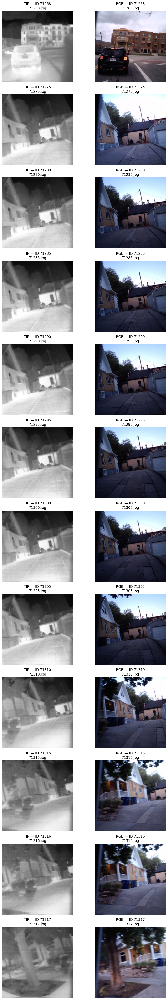

In [ ]:
# STEP 21
# Visualize the boundary images using their ACTUAL filenames

valid_boundary_ids = [
    image_id
    for image_id in boundary_ids
    if image_id in filename_by_id
]

print("Valid boundary images:", len(valid_boundary_ids))
print("IDs:", valid_boundary_ids)

fig, axes = plt.subplots(
    len(valid_boundary_ids),
    2,
    figsize=(10, 4 * len(valid_boundary_ids))
)

# Make axes 2D even if there is only one row
if len(valid_boundary_ids) == 1:
    axes = [axes]

for i, image_id in enumerate(valid_boundary_ids):

    filename = filename_by_id[image_id]

    path_rgb = os.path.join(class1, filename)
    path_tir = os.path.join(class2, filename)

    rgb = Image.open(path_rgb)
    tir = Image.open(path_tir)

    axes[i][0].imshow(tir)
    axes[i][0].set_title(f"TIR — ID {image_id}\n{filename}")
    axes[i][0].axis("off")

    axes[i][1].imshow(rgb)
    axes[i][1].set_title(f"RGB — ID {image_id}\n{filename}")
    axes[i][1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# STEP 22
# Verify the 41 IDs using the actual dataset filenames

middle_ids = list(range(71275, 71316))

found_middle = []
missing_middle = []

for image_id in middle_ids:

    if image_id in filename_by_id:
        found_middle.append(image_id)
    else:
        missing_middle.append(image_id)

print("Expected middle IDs:", len(middle_ids))
print("Found:", len(found_middle))
print("Missing:", len(missing_middle))

if missing_middle:
    print("\nMissing IDs:")
    print(missing_middle)
else:
    print("\nAll 41 IDs are present in the dataset.")

Expected middle IDs: 41
Found: 41
Missing: 0

All 41 IDs are present in the dataset.


In [ ]:
# STEP 23
# Verify both sides of all 41 pairs

pair_problems = []

for image_id in middle_ids:

    if image_id not in filename_by_id:
        pair_problems.append(
            (image_id, "filename not found")
        )
        continue

    filename = filename_by_id[image_id]

    tir_path = os.path.join(class2, filename)
    rgb_path = os.path.join(class1, filename)

    if not os.path.exists(tir_path):
        pair_problems.append(
            (image_id, "TIR missing", filename)
        )

    if not os.path.exists(rgb_path):
        pair_problems.append(
            (image_id, "RGB missing", filename)
        )

print("Pair problems:", len(pair_problems))

if len(pair_problems) == 0:
    print("41-IMAGE BOUNDARY PAIR CHECK: PASSED")
else:
    print("\nProblems:")
    for problem in pair_problems:
        print(problem)

Pair problems: 0
41-IMAGE BOUNDARY PAIR CHECK: PASSED


In [ ]:
# STEP 24
# Inspect every actual filename around the boundary

start_id = 71260
end_id = 71320

print("=" * 60)
print(f"ACTUAL DATASET FILES: {start_id} → {end_id}")
print("=" * 60)

for image_id in range(start_id, end_id + 1):

    if image_id in filename_by_id:
        print(f"{image_id}: PRESENT")
    else:
        print(f"{image_id}: MISSING")

ACTUAL DATASET FILES: 71260 → 71320
71260: PRESENT
71261: PRESENT
71262: PRESENT
71263: PRESENT
71264: PRESENT
71265: PRESENT
71266: PRESENT
71267: PRESENT
71268: PRESENT
71269: MISSING
71270: MISSING
71271: MISSING
71272: MISSING
71273: MISSING
71274: MISSING
71275: PRESENT
71276: PRESENT
71277: PRESENT
71278: PRESENT
71279: PRESENT
71280: PRESENT
71281: PRESENT
71282: PRESENT
71283: PRESENT
71284: PRESENT
71285: PRESENT
71286: PRESENT
71287: PRESENT
71288: PRESENT
71289: PRESENT
71290: PRESENT
71291: PRESENT
71292: PRESENT
71293: PRESENT
71294: PRESENT
71295: PRESENT
71296: PRESENT
71297: PRESENT
71298: PRESENT
71299: PRESENT
71300: PRESENT
71301: PRESENT
71302: PRESENT
71303: PRESENT
71304: PRESENT
71305: PRESENT
71306: PRESENT
71307: PRESENT
71308: PRESENT
71309: PRESENT
71310: PRESENT
71311: PRESENT
71312: PRESENT
71313: PRESENT
71314: PRESENT
71315: PRESENT
71316: PRESENT
71317: PRESENT
71318: PRESENT
71319: PRESENT
71320: PRESENT


In [ ]:
# STEP 25
# Identify the exact missing IDs in this boundary

boundary_missing = [
    image_id
    for image_id in range(71260, 71321)
    if image_id not in filename_by_id
]

boundary_present = [
    image_id
    for image_id in range(71260, 71321)
    if image_id in filename_by_id
]

print("Boundary IDs checked:", len(range(71260, 71321)))
print("Present:", len(boundary_present))
print("Missing:", len(boundary_missing))

print("\nMissing IDs:")
print(boundary_missing)

Boundary IDs checked: 61
Present: 55
Missing: 6

Missing IDs:
[71269, 71270, 71271, 71272, 71273, 71274]


In [ ]:
# STEP 26
# Check class1 and class2 independently

print("=" * 60)
print("CHECKING MISSING IDs IN BOTH CLASSES")
print("=" * 60)

for image_id in boundary_missing:

    possible_names = [
        f"{image_id}.jpg",
        f"{image_id}.jpeg",
        f"{image_id}.png"
    ]

    class1_found = []
    class2_found = []

    for name in possible_names:

        if os.path.exists(os.path.join(class1, name)):
            class1_found.append(name)

        if os.path.exists(os.path.join(class2, name)):
            class2_found.append(name)

    print(
        f"{image_id}: "
        f"class1={class1_found}, "
        f"class2={class2_found}"
    )

CHECKING MISSING IDs IN BOTH CLASSES
71269: class1=[], class2=[]
71270: class1=[], class2=[]
71271: class1=[], class2=[]
71272: class1=[], class2=[]
71273: class1=[], class2=[]
71274: class1=[], class2=[]


In [ ]:
# STEP 27
print("=" * 60)
print("FINAL DATASET COUNT CHECK")
print("=" * 60)

print("Class1:", len(class1_files))
print("Class2:", len(class2_files))
print("Common:", len(common))

print("\nPairing status:")

if (
    len(class1_files) == 148829
    and len(class2_files) == 148829
    and len(common) == 148829
):
    print("148,829 / 148,829 pairs verified.")
    print("PAIRING: 100%")
else:
    print("Counts differ — investigate before continuing.")

FINAL DATASET COUNT CHECK
Class1: 148829
Class2: 148829
Common: 148829

Pairing status:
148,829 / 148,829 pairs verified.
PAIRING: 100%


In [ ]:
import os

dataset_root = "/content/TRI2I_dataset"

print("=" * 60)
print("DATASET FILES / DIRECTORIES")
print("=" * 60)

for root, dirs, files in os.walk(dataset_root):

    # Don't print the huge image directories
    if os.path.basename(root) in ["class1", "class2"]:
        continue

    if files:
        print("\nDirectory:")
        print(root)

        print("Files:")
        for f in files[:50]:
            print("  ", f)

        if len(files) > 50:
            print("  ... and", len(files) - 50, "more")

DATASET FILES / DIRECTORIES


In [ ]:
import os

dataset_root = "/content/TRI2I_dataset"

metadata_files = []

for root, dirs, files in os.walk(dataset_root):
    for f in files:
        lower = f.lower()

        # Ignore image files
        if lower.endswith((".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")):
            continue

        metadata_files.append(os.path.join(root, f))

print("=" * 70)
print("NON-IMAGE FILES FOUND")
print("=" * 70)

print("Total:", len(metadata_files))

for path in metadata_files[:100]:
    print(path)

if len(metadata_files) == 0:
    print("\nNo non-image metadata files found.")

NON-IMAGE FILES FOUND
Total: 0

No non-image metadata files found.


In [ ]:
import os

print("=" * 70)
print("TRI2I DATASET STRUCTURE")
print("=" * 70)

for item in sorted(os.listdir("/content/TRI2I_dataset")):
    path = os.path.join("/content/TRI2I_dataset", item)

    if os.path.isdir(path):
        print(f"[DIR]  {item}")
    else:
        print(f"[FILE] {item}")

TRI2I DATASET STRUCTURE
[DIR]  dataset_1-6-2024


In [ ]:
dataset_inner = "/content/TRI2I_dataset/dataset_1-6-2024"

print("\n" + "=" * 70)
print("INNER DATASET STRUCTURE")
print("=" * 70)

for item in sorted(os.listdir(dataset_inner)):
    path = os.path.join(dataset_inner, item)

    if os.path.isdir(path):
        print(f"[DIR]  {item}")
    else:
        print(f"[FILE] {item}")


INNER DATASET STRUCTURE
[DIR]  class1
[DIR]  class2


In [ ]:
import os

for root, dirs, files in os.walk(dataset_inner):

    # Don't descend into the huge image folders for this check
    dirs[:] = [
        d for d in dirs
        if d not in ["class1", "class2"]
    ]

    for f in files:
        print(os.path.join(root, f))

In [ ]:
# STEP 31
# Create a deterministic 80/10/10 split
#
# IMPORTANT:
# We use the actual filenames present in the dataset.
# We do NOT assume IDs are continuous.

import os
import random

# Reproducibility
SEED = 42
random.seed(SEED)

# Use actual paired filenames
paired_files = sorted(list(common))

print("Total paired images:", len(paired_files))

# Shuffle a COPY of the list
shuffled_files = paired_files.copy()
random.shuffle(shuffled_files)

total = len(shuffled_files)

train_end = int(0.80 * total)
val_end = int(0.90 * total)

train_files = shuffled_files[:train_end]
val_files = shuffled_files[train_end:val_end]
test_files = shuffled_files[val_end:]

print("\nSplit sizes:")
print("Train:", len(train_files))
print("Validation:", len(val_files))
print("Test:", len(test_files))
print("Total:", len(train_files) + len(val_files) + len(test_files))

Total paired images: 148829

Split sizes:
Train: 119063
Validation: 14883
Test: 14883
Total: 148829


In [ ]:
# STEP 32
# Verify that train/validation/test are mutually exclusive

train_set = set(train_files)
val_set = set(val_files)
test_set = set(test_files)

print("Train ∩ Validation:", len(train_set & val_set))
print("Train ∩ Test:", len(train_set & test_set))
print("Validation ∩ Test:", len(val_set & test_set))

print("\nTotal unique files:",
      len(train_set | val_set | test_set))

print("Expected total:",
      len(common))

if (
    len(train_set & val_set) == 0
    and len(train_set & test_set) == 0
    and len(val_set & test_set) == 0
    and len(train_set | val_set | test_set) == len(common)
):
    print("\nSPLIT CHECK: PASSED")
else:
    print("\nSPLIT CHECK: FAILED")

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0

Total unique files: 148829
Expected total: 148829

SPLIT CHECK: PASSED


In [ ]:
# STEP 33
# Save the exact split

import json
import os

split_dir = "/content/TRI2I_splits"
os.makedirs(split_dir, exist_ok=True)

split_data = {
    "seed": SEED,
    "total_pairs": len(common),
    "train": train_files,
    "validation": val_files,
    "test": test_files
}

split_file = os.path.join(
    split_dir,
    "tri2i_split_seed42.json"
)

with open(split_file, "w") as f:
    json.dump(split_data, f, indent=2)

print("Split saved to:")
print(split_file)

print("\nFile size:",
      round(os.path.getsize(split_file) / 1024, 2),
      "KB")

Split saved to:
/content/TRI2I_splits/tri2i_split_seed42.json

File size: 2512.72 KB


In [ ]:
# STEP 34
# Reload the saved split and verify it

import json

with open("/content/TRI2I_splits/tri2i_split_seed42.json", "r") as f:
    saved_split = json.load(f)

print("Saved seed:", saved_split["seed"])
print("Saved total:", saved_split["total_pairs"])

print("\nTrain:", len(saved_split["train"]))
print("Validation:", len(saved_split["validation"]))
print("Test:", len(saved_split["test"]))

if saved_split["total_pairs"] == 148829:
    print("\nSPLIT FILE CHECK: PASSED")
else:
    print("\nSPLIT FILE CHECK: FAILED")

Saved seed: 42
Saved total: 148829

Train: 119063
Validation: 14883
Test: 14883

SPLIT FILE CHECK: PASSED


In [ ]:
# STEP 35
# Create directories for the paired dataset

import os

split_root = "/content/TRI2I_split"

folders = [
    "train/A",
    "train/B",
    "val/A",
    "val/B",
    "test/A",
    "test/B"
]

for folder in folders:
    os.makedirs(
        os.path.join(split_root, folder),
        exist_ok=True
    )

print("Created:")
for folder in folders:
    print(os.path.join(split_root, folder))

Created:
/content/TRI2I_split/train/A
/content/TRI2I_split/train/B
/content/TRI2I_split/val/A
/content/TRI2I_split/val/B
/content/TRI2I_split/test/A
/content/TRI2I_split/test/B


In [ ]:
# STEP 36
# Verify that every split filename exists in both classes

import os

def verify_split(files, split_name):
    missing_a = []
    missing_b = []

    for filename in files:
        path_a = os.path.join(class2, filename)  # TIR
        path_b = os.path.join(class1, filename)  # RGB

        if not os.path.exists(path_a):
            missing_a.append(filename)

        if not os.path.exists(path_b):
            missing_b.append(filename)

    print(f"\n{split_name}")
    print("-" * 40)
    print("Pairs:", len(files))
    print("Missing Thermal:", len(missing_a))
    print("Missing RGB:", len(missing_b))

    return missing_a, missing_b


train_missing_a, train_missing_b = verify_split(
    train_files, "TRAIN"
)

val_missing_a, val_missing_b = verify_split(
    val_files, "VALIDATION"
)

test_missing_a, test_missing_b = verify_split(
    test_files, "TEST"
)

total_missing = (
    len(train_missing_a)
    + len(train_missing_b)
    + len(val_missing_a)
    + len(val_missing_b)
    + len(test_missing_a)
    + len(test_missing_b)
)

print("\n" + "=" * 50)
print("TOTAL MISSING FILES:", total_missing)
print("=" * 50)

if total_missing == 0:
    print("SPLIT FILE VERIFICATION: PASSED")
else:
    print("SPLIT FILE VERIFICATION: FAILED")


TRAIN
----------------------------------------
Pairs: 119063
Missing Thermal: 0
Missing RGB: 0

VALIDATION
----------------------------------------
Pairs: 14883
Missing Thermal: 0
Missing RGB: 0

TEST
----------------------------------------
Pairs: 14883
Missing Thermal: 0
Missing RGB: 0

TOTAL MISSING FILES: 0
SPLIT FILE VERIFICATION: PASSED


In [ ]:
# STEP 36
# Verify that every split filename exists in BOTH Thermal and RGB folders.

import os

def verify_split(files, split_name):
    missing_thermal = []
    missing_rgb = []

    for filename in files:
        thermal_path = os.path.join(class2, filename)
        rgb_path = os.path.join(class1, filename)

        if not os.path.exists(thermal_path):
            missing_thermal.append(filename)

        if not os.path.exists(rgb_path):
            missing_rgb.append(filename)

    print(f"\n{split_name}")
    print("-" * 45)
    print("Pairs:", len(files))
    print("Missing Thermal:", len(missing_thermal))
    print("Missing RGB:", len(missing_rgb))

    return missing_thermal, missing_rgb


train_missing_thermal, train_missing_rgb = verify_split(
    train_files, "TRAIN"
)

val_missing_thermal, val_missing_rgb = verify_split(
    val_files, "VALIDATION"
)

test_missing_thermal, test_missing_rgb = verify_split(
    test_files, "TEST"
)

total_missing = (
    len(train_missing_thermal)
    + len(train_missing_rgb)
    + len(val_missing_thermal)
    + len(val_missing_rgb)
    + len(test_missing_thermal)
    + len(test_missing_rgb)
)

print("\n" + "=" * 55)
print("TOTAL MISSING FILES:", total_missing)
print("=" * 55)

if total_missing == 0:
    print("SPLIT FILE VERIFICATION: PASSED")
else:
    print("SPLIT FILE VERIFICATION: FAILED")


TRAIN
---------------------------------------------
Pairs: 119063
Missing Thermal: 0
Missing RGB: 0

VALIDATION
---------------------------------------------
Pairs: 14883
Missing Thermal: 0
Missing RGB: 0

TEST
---------------------------------------------
Pairs: 14883
Missing Thermal: 0
Missing RGB: 0

TOTAL MISSING FILES: 0
SPLIT FILE VERIFICATION: PASSED


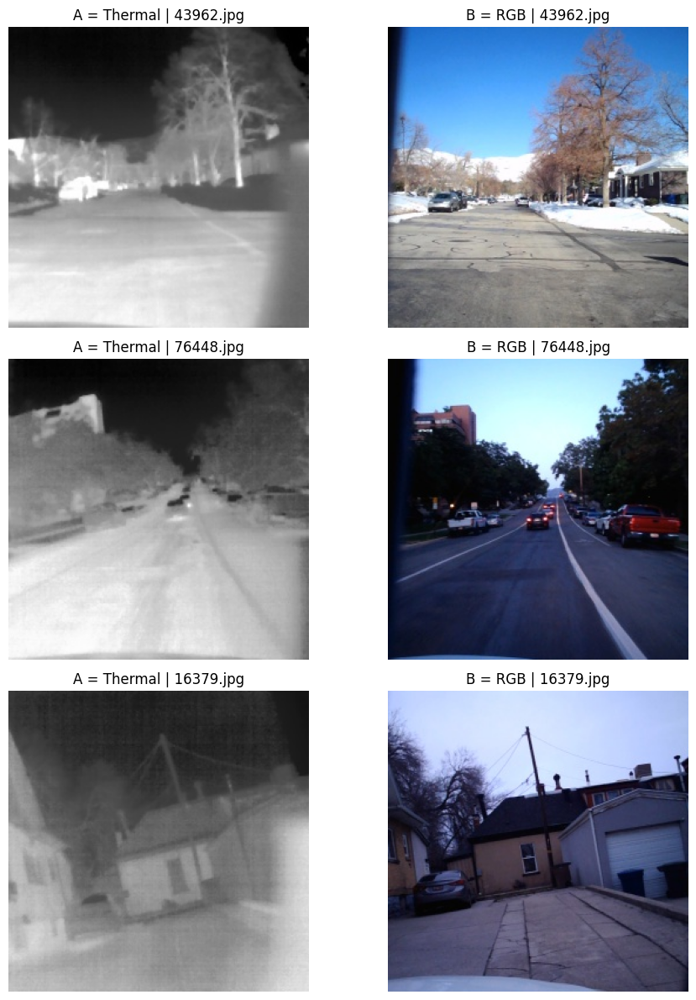

In [ ]:
# STEP 37
# Verify the exact Thermal -> RGB pairing before bulk preparation.

from PIL import Image
import matplotlib.pyplot as plt
import os

sample_files = train_files[:3]

fig, axes = plt.subplots(3, 2, figsize=(10, 12))

for i, filename in enumerate(sample_files):

    thermal_path = os.path.join(class2, filename)
    rgb_path = os.path.join(class1, filename)

    thermal = Image.open(thermal_path)
    rgb = Image.open(rgb_path)

    axes[i, 0].imshow(thermal)
    axes[i, 0].set_title(f"A = Thermal | {filename}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(rgb)
    axes[i, 1].set_title(f"B = RGB | {filename}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# STEP 38
# Create ONE aligned pix2pix example.
#
# Left  = Thermal (A)
# Right = RGB (B)

from PIL import Image
import os

sample_filename = train_files[0]

thermal_path = os.path.join(class2, sample_filename)
rgb_path = os.path.join(class1, sample_filename)

thermal = Image.open(thermal_path).convert("RGB")
rgb = Image.open(rgb_path).convert("RGB")

print("Thermal size:", thermal.size)
print("RGB size:", rgb.size)

aligned = Image.new(
    "RGB",
    (thermal.width + rgb.width, thermal.height)
)

aligned.paste(thermal, (0, 0))
aligned.paste(rgb, (thermal.width, 0))

test_aligned_path = "/content/test_aligned_example.jpg"
aligned.save(test_aligned_path, quality=95)

print("\nSaved:")
print(test_aligned_path)
print("Aligned size:", aligned.size)

Thermal size: (256, 256)
RGB size: (256, 256)

Saved:
/content/test_aligned_example.jpg
Aligned size: (512, 256)


Image size: (512, 256)


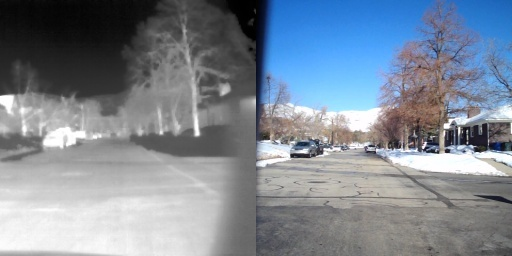

In [ ]:
# STEP 39
# Inspect the final pix2pix input format.

from IPython.display import display
from PIL import Image

img = Image.open("/content/test_aligned_example.jpg")

print("Image size:", img.size)
display(img)

In [ ]:
import shutil

total, used, free = shutil.disk_usage("/content")

print("Colab storage")
print("=" * 50)
print("Total:", round(total / (1024**3), 2), "GB")
print("Used :", round(used / (1024**3), 2), "GB")
print("Free :", round(free / (1024**3), 2), "GB")

Colab storage
Total: 112.64 GB
Used : 53.88 GB
Free : 58.74 GB


In [ ]:
# STEP 41
# Estimate storage required for the full aligned dataset

from PIL import Image
import os

sample_files = train_files[:100]

sample_dir = "/content/aligned_size_test"
os.makedirs(sample_dir, exist_ok=True)

sizes = []

for filename in sample_files:

    thermal_path = os.path.join(class2, filename)
    rgb_path = os.path.join(class1, filename)

    thermal = Image.open(thermal_path).convert("RGB")
    rgb = Image.open(rgb_path).convert("RGB")

    aligned = Image.new(
        "RGB",
        (thermal.width + rgb.width, thermal.height)
    )

    aligned.paste(thermal, (0, 0))
    aligned.paste(rgb, (thermal.width, 0))

    output_path = os.path.join(sample_dir, filename)

    aligned.save(
        output_path,
        format="JPEG",
        quality=95
    )

    sizes.append(os.path.getsize(output_path))

average_size = sum(sizes) / len(sizes)

estimated_total = average_size * len(common)

print("Sample images:", len(sizes))
print("Average aligned image size:",
      round(average_size / 1024, 2), "KB")

print("Estimated full dataset size:",
      round(estimated_total / (1024**3), 2), "GB")

print("Current free space:",
      round(__import__("shutil").disk_usage("/content").free / (1024**3), 2),
      "GB")

Sample images: 100
Average aligned image size: 38.05 KB
Estimated full dataset size: 5.4 GB
Current free space: 58.74 GB


In [ ]:
# STEP 42
# Remove only the temporary storage-estimation files

import shutil
import os

if os.path.exists("/content/aligned_size_test"):
    shutil.rmtree("/content/aligned_size_test")

print("Temporary test directory removed.")

Temporary test directory removed.


In [ ]:
# STEP 43
# Save our exact split definition to Google Drive

import os
import shutil

drive_split_dir = "/content/drive/MyDrive/MP1_Thermal_RGB_Project"

os.makedirs(drive_split_dir, exist_ok=True)

source_split = "/content/TRI2I_splits/tri2i_split_seed42.json"
drive_split = os.path.join(
    drive_split_dir,
    "tri2i_split_seed42.json"
)

shutil.copy2(source_split, drive_split)

print("Split backup saved to:")
print(drive_split)

Split backup saved to:
/content/drive/MyDrive/MP1_Thermal_RGB_Project/tri2i_split_seed42.json


In [ ]:
# STEP 44
# Create the pix2pix aligned dataset structure

aligned_root = "/content/TRI2I_pix2pix"

for split_name in ["train", "val", "test"]:
    os.makedirs(
        os.path.join(aligned_root, split_name),
        exist_ok=True
    )

print("Created:")
print(aligned_root)

for split_name in ["train", "val", "test"]:
    print(
        " -",
        os.path.join(aligned_root, split_name)
    )

Created:
/content/TRI2I_pix2pix
 - /content/TRI2I_pix2pix/train
 - /content/TRI2I_pix2pix/val
 - /content/TRI2I_pix2pix/test


In [ ]:
# STEP 45
# Estimate the disk space required for the full aligned dataset

from PIL import Image
import os
import shutil

sample_files = train_files[:100]

temporary_dir = "/content/aligned_size_test"
os.makedirs(temporary_dir, exist_ok=True)

sizes = []

for filename in sample_files:

    thermal_path = os.path.join(class2, filename)
    rgb_path = os.path.join(class1, filename)

    thermal = Image.open(thermal_path).convert("RGB")
    rgb = Image.open(rgb_path).convert("RGB")

    aligned = Image.new(
        "RGB",
        (thermal.width + rgb.width, thermal.height)
    )

    aligned.paste(thermal, (0, 0))
    aligned.paste(rgb, (thermal.width, 0))

    output_path = os.path.join(
        temporary_dir,
        filename
    )

    aligned.save(
        output_path,
        format="JPEG",
        quality=95
    )

    sizes.append(os.path.getsize(output_path))


average_size = sum(sizes) / len(sizes)
estimated_total = average_size * len(common)

free_space = shutil.disk_usage("/content").free

print("=" * 60)
print("ALIGNED DATASET STORAGE ESTIMATE")
print("=" * 60)

print("Sample images:", len(sizes))

print(
    "Average aligned image:",
    round(average_size / 1024, 2),
    "KB"
)

print(
    "Estimated full dataset:",
    round(estimated_total / (1024**3), 2),
    "GB"
)

print(
    "Current free space:",
    round(free_space / (1024**3), 2),
    "GB"
)

if estimated_total < free_space * 0.5:
    print("\nSTORAGE CHECK: SAFE")
elif estimated_total < free_space * 0.8:
    print("\nSTORAGE CHECK: ACCEPTABLE")
else:
    print("\nSTORAGE CHECK: TOO LARGE — STOP")

ALIGNED DATASET STORAGE ESTIMATE
Sample images: 100
Average aligned image: 38.05 KB
Estimated full dataset: 5.4 GB
Current free space: 58.73 GB

STORAGE CHECK: SAFE


In [ ]:
# STEP 46
# Remove only the temporary storage-estimation files

import shutil
import os

temporary_dir = "/content/aligned_size_test"

if os.path.exists(temporary_dir):
    shutil.rmtree(temporary_dir)

print("Temporary estimation directory removed.")

Temporary estimation directory removed.


In [ ]:
# STEP 47
# Remove only the temporary 100-image storage test.

import os
import shutil

temporary_dir = "/content/aligned_size_test"

if os.path.exists(temporary_dir):
    shutil.rmtree(temporary_dir)
    print("Temporary test directory removed.")
else:
    print("Temporary test directory does not exist.")

Temporary test directory does not exist.


In [ ]:
# STEP 48
# Generate the complete aligned pix2pix dataset.

from PIL import Image
from tqdm.auto import tqdm
import os
import shutil
import time

aligned_root = "/content/TRI2I_pix2pix"

splits = {
    "train": train_files,
    "val": val_files,
    "test": test_files
}

# Make sure directories exist
for split_name in splits:
    os.makedirs(
        os.path.join(aligned_root, split_name),
        exist_ok=True
    )

total_start = time.time()

for split_name, files in splits.items():

    print("\n" + "=" * 70)
    print(f"CREATING {split_name.upper()} DATASET")
    print("=" * 70)

    split_start = time.time()
    output_dir = os.path.join(aligned_root, split_name)

    errors = []

    for filename in tqdm(
        files,
        desc=f"Generating {split_name}",
        unit="image"
    ):

        try:
            # A = Thermal
            thermal_path = os.path.join(
                class2,
                filename
            )

            # B = RGB
            rgb_path = os.path.join(
                class1,
                filename
            )

            thermal = Image.open(
                thermal_path
            ).convert("RGB")

            rgb = Image.open(
                rgb_path
            ).convert("RGB")

            # Safety check
            if thermal.size != rgb.size:
                raise ValueError(
                    f"Size mismatch: "
                    f"{thermal.size} vs {rgb.size}"
                )

            # Create A|B aligned image
            aligned = Image.new(
                "RGB",
                (
                    thermal.width + rgb.width,
                    thermal.height
                )
            )

            # LEFT = Thermal
            aligned.paste(
                thermal,
                (0, 0)
            )

            # RIGHT = RGB
            aligned.paste(
                rgb,
                (thermal.width, 0)
            )

            output_path = os.path.join(
                output_dir,
                filename
            )

            aligned.save(
                output_path,
                format="JPEG",
                quality=95
            )

        except Exception as e:
            errors.append(
                (filename, str(e))
            )

    elapsed = time.time() - split_start

    print(f"\n{split_name.upper()} completed.")
    print("Expected:", len(files))
    print("Errors  :", len(errors))
    print(
        "Time    :",
        round(elapsed / 60, 2),
        "minutes"
    )

    if errors:
        print("\nFirst errors:")
        for error in errors[:10]:
            print(error)

total_elapsed = time.time() - total_start

print("\n" + "=" * 70)
print("FULL DATASET GENERATION COMPLETE")
print("=" * 70)

print(
    "Total time:",
    round(total_elapsed / 60, 2),
    "minutes"
)


CREATING TRAIN DATASET


Generating train:   0%|          | 0/119063 [00:00<?, ?image/s]


TRAIN completed.
Expected: 119063
Errors  : 0
Time    : 7.35 minutes

CREATING VAL DATASET


Generating val:   0%|          | 0/14883 [00:00<?, ?image/s]


VAL completed.
Expected: 14883
Errors  : 0
Time    : 0.93 minutes

CREATING TEST DATASET


Generating test:   0%|          | 0/14883 [00:00<?, ?image/s]


TEST completed.
Expected: 14883
Errors  : 0
Time    : 0.9 minutes

FULL DATASET GENERATION COMPLETE
Total time: 9.18 minutes


In [ ]:
# STEP 49
# Verify generated file counts

import os

expected_counts = {
    "train": len(train_files),
    "val": len(val_files),
    "test": len(test_files)
}

print("=" * 60)
print("ALIGNED DATASET COUNT VERIFICATION")
print("=" * 60)

all_passed = True

for split_name, expected in expected_counts.items():

    folder = os.path.join(
        aligned_root,
        split_name
    )

    actual = len([
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    print(
        f"{split_name.upper():12} "
        f"Expected: {expected:,} | "
        f"Actual: {actual:,}"
    )

    if actual != expected:
        all_passed = False

print()

if all_passed:
    print("ALIGNED DATASET COUNT CHECK: PASSED")
else:
    print("ALIGNED DATASET COUNT CHECK: FAILED")

ALIGNED DATASET COUNT VERIFICATION
TRAIN        Expected: 119,063 | Actual: 119,063
VAL          Expected: 14,883 | Actual: 14,883
TEST         Expected: 14,883 | Actual: 14,883

ALIGNED DATASET COUNT CHECK: PASSED


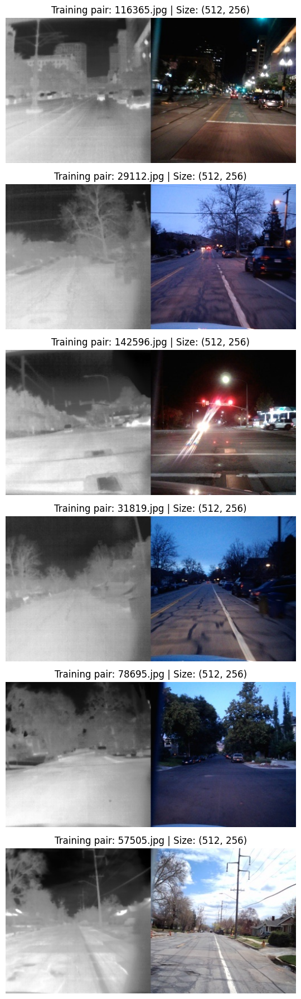

In [ ]:
# STEP 50
# Visually verify random generated aligned images

import random
from PIL import Image
import matplotlib.pyplot as plt
import os

random.seed(42)

sample_generated = random.sample(
    train_files,
    6
)

fig, axes = plt.subplots(
    6,
    1,
    figsize=(12, 18)
)

for i, filename in enumerate(sample_generated):

    path = os.path.join(
        aligned_root,
        "train",
        filename
    )

    img = Image.open(path)

    axes[i].imshow(img)
    axes[i].set_title(
        f"Training pair: {filename} | Size: {img.size}"
    )
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# STEP 51
# Verify dimensions of generated images

from PIL import Image
import os
import random

random.seed(42)

for split_name, files in {
    "train": train_files,
    "val": val_files,
    "test": test_files
}.items():

    samples = random.sample(
        files,
        min(100, len(files))
    )

    wrong_dimensions = []

    for filename in samples:

        path = os.path.join(
            aligned_root,
            split_name,
            filename
        )

        with Image.open(path) as img:

            if img.size != (512, 256):
                wrong_dimensions.append(
                    (filename, img.size)
                )

    print(
        f"{split_name.upper()}: "
        f"{len(wrong_dimensions)} wrong dimensions"
    )

    if wrong_dimensions:
        print(wrong_dimensions[:10])

TRAIN: 0 wrong dimensions
VAL: 0 wrong dimensions
TEST: 0 wrong dimensions


In [ ]:
# STEP 52
# Check storage after creating the aligned dataset

import shutil

total, used, free = shutil.disk_usage("/content")

print("=" * 50)
print("STORAGE AFTER DATASET GENERATION")
print("=" * 50)

print("Total:", round(total / (1024**3), 2), "GB")
print("Used :", round(used / (1024**3), 2), "GB")
print("Free :", round(free / (1024**3), 2), "GB")

STORAGE AFTER DATASET GENERATION
Total: 112.64 GB
Used : 59.54 GB
Free : 53.08 GB


In [ ]:
# STEP 56
import torch

print("=" * 60)
print("GPU CHECK")
print("=" * 60)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024**3),
            2
        ),
        "GB"
    )
else:
    print("\nNO GPU AVAILABLE.")

GPU CHECK
PyTorch: 2.11.0+cpu
CUDA available: False

NO GPU AVAILABLE.


In [ ]:
# STEP 54
# Verify pix2pix dataset directories

import os

dataset_root = "/content/TRI2I_pix2pix"

print("=" * 60)
print("PIX2PIX DATASET STRUCTURE")
print("=" * 60)

for split in ["train", "val", "test"]:

    path = os.path.join(dataset_root, split)

    exists = os.path.isdir(path)

    count = 0

    if exists:
        count = len([
            f for f in os.listdir(path)
            if f.lower().endswith(
                (".jpg", ".jpeg", ".png")
            )
        ])

    print(
        f"{split.upper():8} "
        f"exists={exists} "
        f"images={count:,}"
    )

PIX2PIX DATASET STRUCTURE
TRAIN    exists=False images=0
VAL      exists=False images=0
TEST     exists=False images=0


In [ ]:
# STEP 55
# Check whether pix2pix repository is already installed/cloned

import os

repo_path = "/content/pytorch-CycleGAN-and-pix2pix"

print("=" * 60)
print("PIX2PIX REPOSITORY CHECK")
print("=" * 60)

print("Repository exists:", os.path.isdir(repo_path))

if os.path.isdir(repo_path):

    print("\nRepository contents:")

    for item in sorted(os.listdir(repo_path))[:30]:
        print(" -", item)

    train_file = os.path.join(
        repo_path,
        "train.py"
    )

    test_file = os.path.join(
        repo_path,
        "test.py"
    )

    print("\ntrain.py exists:", os.path.exists(train_file))
    print("test.py exists :", os.path.exists(test_file))

PIX2PIX REPOSITORY CHECK
Repository exists: False


In [ ]:
import torch

print("=" * 60)
print("GPU CHECK - AFTER SWITCHING RUNTIME")
print("=" * 60)

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA:", torch.version.cuda)
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / (1024**3),
            2
        ),
        "GB"
    )
else:
    print("\nNO GPU AVAILABLE.")

GPU CHECK - AFTER SWITCHING RUNTIME
PyTorch: 2.11.0+cpu
CUDA available: False

NO GPU AVAILABLE.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

zip_path = "/content/drive/MyDrive/dataset_1-6-2024.zip"

print("ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("ZIP size (GB):", round(os.path.getsize(zip_path) / (1024**3), 2))

ZIP exists: True
ZIP size (GB): 5.44


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/dataset_1-6-2024.zip"

sample_root = "/content/TRI2I_local_smoke_test"

# Clean previous sample if it exists
if os.path.exists(sample_root):
    import shutil
    shutil.rmtree(sample_root)

# Create folders
for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(sample_root, split, "A"), exist_ok=True)
    os.makedirs(os.path.join(sample_root, split, "B"), exist_ok=True)

# Exact sample IDs
train_ids = list(range(10000, 10020))   # 20
val_ids   = list(range(10020, 10025))   # 5
test_ids  = list(range(10025, 10030))   # 5

split_ids = {
    "train": train_ids,
    "val": val_ids,
    "test": test_ids
}

with zipfile.ZipFile(zip_path, "r") as z:
    all_names = set(z.namelist())

    extracted = 0
    missing = []

    for split, ids in split_ids.items():
        for image_id in ids:
            filename = f"{image_id}.jpg"

            rgb_name = f"dataset_1-6-2024/class1/{filename}"
            tir_name = f"dataset_1-6-2024/class2/{filename}"

            if rgb_name not in all_names or tir_name not in all_names:
                missing.append(image_id)
                continue

            # TIR -> A
            with z.open(tir_name) as src:
                with open(
                    os.path.join(sample_root, split, "A", filename),
                    "wb"
                ) as dst:
                    dst.write(src.read())

            # RGB -> B
            with z.open(rgb_name) as src:
                with open(
                    os.path.join(sample_root, split, "B", filename),
                    "wb"
                ) as dst:
                    dst.write(src.read())

            extracted += 1

print("Sample creation completed.")
print("Pairs extracted:", extracted)
print("Missing IDs:", missing)
print("Sample location:", sample_root)

for split in ["train", "val", "test"]:
    a_count = len(os.listdir(os.path.join(sample_root, split, "A")))
    b_count = len(os.listdir(os.path.join(sample_root, split, "B")))

    print(
        f"{split}: TIR={a_count}, RGB={b_count}"
    )

Sample creation completed.
Pairs extracted: 30
Missing IDs: []
Sample location: /content/TRI2I_local_smoke_test
train: TIR=20, RGB=20
val: TIR=5, RGB=5
test: TIR=5, RGB=5


TIR:
  Path: /content/TRI2I_local_smoke_test/train/A/10000.jpg
  Size: (256, 256)
  Mode: RGB

RGB:
  Path: /content/TRI2I_local_smoke_test/train/B/10000.jpg
  Size: (256, 256)
  Mode: RGB


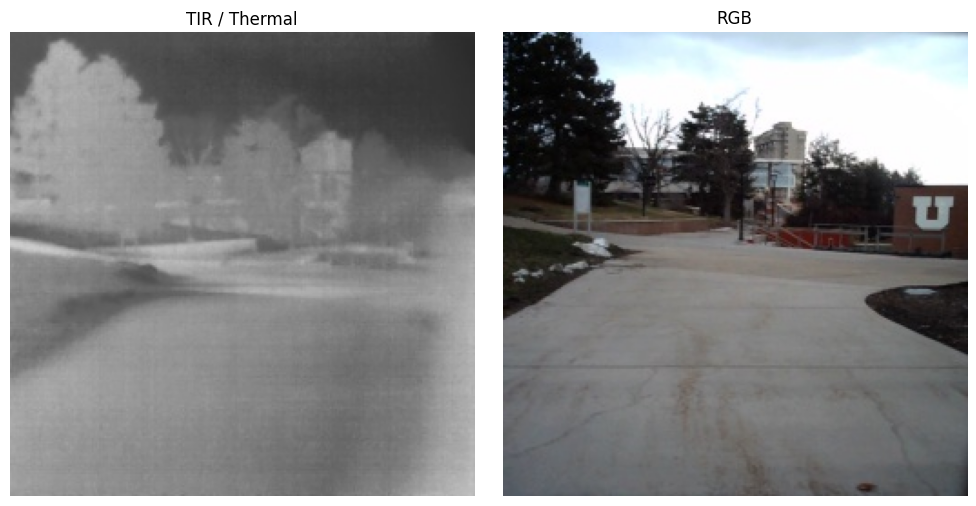

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

sample_root = "/content/TRI2I_local_smoke_test"

image_id = "10000.jpg"

tir_path = os.path.join(sample_root, "train", "A", image_id)
rgb_path = os.path.join(sample_root, "train", "B", image_id)

tir = Image.open(tir_path)
rgb = Image.open(rgb_path)

print("TIR:")
print("  Path:", tir_path)
print("  Size:", tir.size)
print("  Mode:", tir.mode)

print("\nRGB:")
print("  Path:", rgb_path)
print("  Size:", rgb.size)
print("  Mode:", rgb.mode)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(tir)
axes[0].set_title("TIR / Thermal")
axes[0].axis("off")

axes[1].imshow(rgb)
axes[1].set_title("RGB")
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import shutil
import os

sample_root = "/content/TRI2I_local_smoke_test"
zip_base = "/content/TRI2I_local_smoke_test"

# Create ZIP
zip_path = shutil.make_archive(
    zip_base,
    "zip",
    sample_root
)

print("ZIP created successfully.")
print("Path:", zip_path)
print("Size (MB):", round(os.path.getsize(zip_path) / (1024**2), 2))

ZIP created successfully.
Path: /content/TRI2I_local_smoke_test.zip
Size (MB): 1.07


In [ ]:
from google.colab import files

files.download("/content/TRI2I_local_smoke_test.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
import os

paths = [
    "/content/TRI2I_dataset",
    "/content/TRI2I_split",
    "/content/TRI2I_pix2pix",
]

for p in paths:
    print(p, "->", os.path.exists(p))

/content/TRI2I_dataset -> False
/content/TRI2I_split -> False
/content/TRI2I_pix2pix -> False


In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive')

zip_path = "/content/drive/MyDrive/dataset_1-6-2024.zip"

print("ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("ZIP size (GB):", round(os.path.getsize(zip_path) / (1024**3), 2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ZIP exists: True
ZIP size (GB): 5.44


In [ ]:
import shutil

total, used, free = shutil.disk_usage("/content")

print("Total storage :", round(total / (1024**3), 2), "GB")
print("Used storage  :", round(used / (1024**3), 2), "GB")
print("Free storage  :", round(free / (1024**3), 2), "GB")

Total storage : 112.64 GB
Used storage  : 42.47 GB
Free storage  : 70.15 GB


In [ ]:
import os

zip_path = "/content/drive/MyDrive/dataset_1-6-2024.zip"
extract_path = "/content/TRI2I_dataset"

print("Starting extraction...")
os.system(f'unzip -q "{zip_path}" -d "{extract_path}"')
print("Extraction command finished.")

Starting extraction...
Extraction command finished.


In [ ]:
import os

class1 = "/content/TRI2I_dataset/dataset_1-6-2024/class1"
class2 = "/content/TRI2I_dataset/dataset_1-6-2024/class2"

count1 = len(os.listdir(class1)) if os.path.exists(class1) else 0
count2 = len(os.listdir(class2)) if os.path.exists(class2) else 0

print("class1 exists:", os.path.exists(class1))
print("class2 exists:", os.path.exists(class2))
print("class1 files:", count1)
print("class2 files:", count2)

class1 exists: True
class2 exists: True
class1 files: 148829
class2 files: 148829


In [ ]:
import os

class1 = "/content/TRI2I_dataset/dataset_1-6-2024/class1"
class2 = "/content/TRI2I_dataset/dataset_1-6-2024/class2"

files1 = set(os.listdir(class1))
files2 = set(os.listdir(class2))

common = files1 & files2
only_class1 = files1 - files2
only_class2 = files2 - files1

print("Class1:", len(files1))
print("Class2:", len(files2))
print("Common filenames:", len(common))
print("Only in class1:", len(only_class1))
print("Only in class2:", len(only_class2))

print()
print("PAIRING COMPLETE:", len(common) == len(files1) == len(files2))

Class1: 148829
Class2: 148829
Common filenames: 148829
Only in class1: 0
Only in class2: 0

PAIRING COMPLETE: True


In [ ]:
import os

split_root = "/content/TRI2I_split"

for split in ["train", "val", "test"]:
    a = os.path.join(split_root, split, "A")
    b = os.path.join(split_root, split, "B")

    print(
        split,
        "A:", len(os.listdir(a)) if os.path.exists(a) else 0,
        "B:", len(os.listdir(b)) if os.path.exists(b) else 0
    )


train A: 0 B: 0
val A: 0 B: 0
test A: 0 B: 0


In [ ]:
from google.colab import drive

drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [ ]:
import os

root = "/content/TRI2I_dataset"

for current_root, dirs, files in os.walk(root):
    level = current_root.replace(root, "").count(os.sep)

    if level <= 2:
        print(
            "  " * level +
            os.path.basename(current_root) +
            f"  [folders={len(dirs)}, files={len(files)}]"
        )

In [ ]:
import os

root = "/content/TRI2I_dataset"

for current_root, dirs, files in os.walk(root):
    level = current_root.replace(root, "").count(os.sep)

    if level <= 2:
        print(
            "  " * level +
            os.path.basename(current_root) +
            f"  [folders={len(dirs)}, files={len(files)}]"
        )

In [ ]:
import os

base = "/content/TRI2I_dataset"

print("TRI2I_dataset exists:", os.path.exists(base))

for root, dirs, files in os.walk(base):
    if "class1" in dirs or "class2" in dirs:
        print("FOUND DATASET FOLDER:")
        print(root)
        print("Contains:", dirs)
        break

TRI2I_dataset exists: False


In [ ]:
import os

matches = []

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.lower() == "dataset_1-6-2024.zip":
            matches.append(os.path.join(root, file))

print("Matches found:", len(matches))

for path in matches:
    print(path)

Matches found: 1
/content/drive/MyDrive/dataset_1-6-2024.zip


In [ ]:
import os

zip_path = "/content/drive/MyDrive/dataset_1-6-2024.zip"

print("ZIP exists:", os.path.exists(zip_path))
print("ZIP size (GB):", round(os.path.getsize(zip_path) / (1024**3), 2))

ZIP exists: True
ZIP size (GB): 5.44


In [ ]:
import os

zip_path = "/content/drive/MyDrive/dataset_1-6-2024.zip"
extract_path = "/content/TRI2I_dataset"

print("Extracting TRI2I dataset...")
result = os.system(f'unzip -q "{zip_path}" -d "{extract_path}"')

print("Extraction finished.")
print("Return code:", result)

Extracting TRI2I dataset...
Extraction finished.
Return code: 0


In [ ]:
import os

root = "/content/TRI2I_dataset"

print("TRI2I_dataset exists:", os.path.exists(root))

if os.path.exists(root):
    print("Contents:")
    for item in sorted(os.listdir(root)):
        path = os.path.join(root, item)
        print(" -", item, "[folder]" if os.path.isdir(path) else "[file]")

TRI2I_dataset exists: True
Contents:
 - dataset_1-6-2024 [folder]


In [ ]:
import os

root = "/content/TRI2I_dataset/dataset_1-6-2024"

class1 = os.path.join(root, "class1")
class2 = os.path.join(root, "class2")

print("class1 exists:", os.path.exists(class1))
print("class2 exists:", os.path.exists(class2))

if os.path.exists(class1):
    print("class1 files:", len(os.listdir(class1)))

if os.path.exists(class2):
    print("class2 files:", len(os.listdir(class2)))

class1 exists: True
class2 exists: True
class1 files: 148829
class2 files: 148829


In [ ]:
import os
import random

root = "/content/TRI2I_dataset/dataset_1-6-2024"

class1 = os.path.join(root, "class1")
class2 = os.path.join(root, "class2")

files = sorted(set(os.listdir(class1)) & set(os.listdir(class2)))

random.seed(42)
random.shuffle(files)

n = len(files)

train_files = files[:int(0.80 * n)]
val_files = files[int(0.80 * n):int(0.90 * n)]
test_files = files[int(0.90 * n):]

print("Total paired:", len(files))
print("Train:", len(train_files))
print("Validation:", len(val_files))
print("Test:", len(test_files))
print("Total split:", len(train_files) + len(val_files) + len(test_files))

Total paired: 148829
Train: 119063
Validation: 14883
Test: 14883
Total split: 148829


In [ ]:
import os

split_root = "/content/TRI2I_split"

for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(split_root, split, "A"), exist_ok=True)
    os.makedirs(os.path.join(split_root, split, "B"), exist_ok=True)

print("Split folders created successfully.")

for split in ["train", "val", "test"]:
    print(
        split,
        "A:", os.path.exists(os.path.join(split_root, split, "A")),
        "B:", os.path.exists(os.path.join(split_root, split, "B"))
    )

Split folders created successfully.
train A: True B: True
val A: True B: True
test A: True B: True


In [ ]:
import json
import os

split_info = {
    "seed": 42,
    "train": train_files,
    "val": val_files,
    "test": test_files
}

json_path = "/content/TRI2I_split/tri2i_split_seed42.json"

with open(json_path, "w") as f:
    json.dump(split_info, f)

print("Split file saved:", json_path)
print("File exists:", os.path.exists(json_path))
print("Size (KB):", round(os.path.getsize(json_path) / 1024, 2))

Split file saved: /content/TRI2I_split/tri2i_split_seed42.json
File exists: True
Size (KB): 1931.3


In [ ]:
import os
import shutil

source_root = "/content/TRI2I_dataset/dataset_1-6-2024"
split_root = "/content/TRI2I_split"

source_A = os.path.join(source_root, "class2")  # TIR
source_B = os.path.join(source_root, "class1")  # RGB

split_data = {
    "train": train_files,
    "val": val_files,
    "test": test_files
}

for split, filenames in split_data.items():
    A_dir = os.path.join(split_root, split, "A")
    B_dir = os.path.join(split_root, split, "B")

    print(f"Copying {split}: {len(filenames)} pairs...")

    for i, filename in enumerate(filenames, 1):
        shutil.copy2(
            os.path.join(source_A, filename),
            os.path.join(A_dir, filename)
        )

        shutil.copy2(
            os.path.join(source_B, filename),
            os.path.join(B_dir, filename)
        )

        if i % 10000 == 0:
            print(f"  {i}/{len(filenames)} pairs copied")

print("ALL SPLIT IMAGES COPIED SUCCESSFULLY.")

Copying train: 119063 pairs...
  10000/119063 pairs copied
  20000/119063 pairs copied
  30000/119063 pairs copied
  40000/119063 pairs copied
  50000/119063 pairs copied
  60000/119063 pairs copied
  70000/119063 pairs copied
  80000/119063 pairs copied
  90000/119063 pairs copied
  100000/119063 pairs copied
  110000/119063 pairs copied
Copying val: 14883 pairs...
  10000/14883 pairs copied
Copying test: 14883 pairs...
  10000/14883 pairs copied
ALL SPLIT IMAGES COPIED SUCCESSFULLY.


In [ ]:
import os

split_root = "/content/TRI2I_split"

for split in ["train", "val", "test"]:
    A = os.path.join(split_root, split, "A")
    B = os.path.join(split_root, split, "B")

    count_A = len(os.listdir(A))
    count_B = len(os.listdir(B))

    print(f"{split}: A={count_A}, B={count_B}, paired={count_A == count_B}")

train: A=119063, B=119063, paired=True
val: A=14883, B=14883, paired=True
test: A=14883, B=14883, paired=True


In [ ]:
import os

repo = "/content/pytorch-CycleGAN-and-pix2pix"

print("Pix2Pix repository exists:", os.path.exists(repo))

if os.path.exists(repo):
    print("train.py exists:", os.path.exists(os.path.join(repo, "train.py")))
    print("test.py exists:", os.path.exists(os.path.join(repo, "test.py")))

Pix2Pix repository exists: False


In [ ]:
%cd /content
!git clone https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix.git

/content
Cloning into 'pytorch-CycleGAN-and-pix2pix'...
remote: Enumerating objects: 2619, done.
remote: Total 2619 (delta 0), reused 0 (delta 0), pack-reused 2619 (from 1)
Receiving objects: 100% (2619/2619), 8.24 MiB | 19.48 MiB/s, done.
Resolving deltas: 100% (1654/1654), done.


In [ ]:
import os

repo = "/content/pytorch-CycleGAN-and-pix2pix"

print("Repository exists:", os.path.exists(repo))
print("train.py exists:", os.path.exists(os.path.join(repo, "train.py")))
print("test.py exists:", os.path.exists(os.path.join(repo, "test.py")))
print(
    "combine_A_and_B.py exists:",
    os.path.exists(
        os.path.join(repo, "datasets", "combine_A_and_B.py")
    )
)

Repository exists: True
train.py exists: True
test.py exists: True
combine_A_and_B.py exists: True


In [ ]:
!pip install -q dominate

In [ ]:
import dominate

print("dominate version:", dominate.__version__)
print("DOMINATE INSTALLATION: OK")

dominate version: 2.9.1
DOMINATE INSTALLATION: OK


In [ ]:
!python /content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py --help

usage: create image pairs [-h] [--fold_A FOLD_A] [--fold_B FOLD_B]
                          [--fold_AB FOLD_AB] [--num_imgs NUM_IMGS] [--use_AB]
                          [--no_multiprocessing]

options:
  -h, --help            show this help message and exit
  --fold_A FOLD_A       input directory for image A
  --fold_B FOLD_B       input directory for image B
  --fold_AB FOLD_AB     output directory
  --num_imgs NUM_IMGS   number of images
  --use_AB              if true: (0001_A, 0001_B) to (0001_AB)
  --no_multiprocessing  If used, chooses single CPU execution instead of
                        parallel execution


In [ ]:
from pathlib import Path

script = "/content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py"

with open(script, "r") as f:
    content = f.read()

if "from pathlib import Path" not in content:
    content = content.replace(
        "import argparse",
        "import argparse\nfrom pathlib import Path"
    )

    with open(script, "w") as f:
        f.write(content)

print("Path import fixed.")
print("Verification:", "from pathlib import Path" in content)

Path import fixed.
Verification: True


In [ ]:
!python /content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py \
    --fold_A /content/TRI2I_split/train/A \
    --fold_B /content/TRI2I_split/train/B \
    --fold_AB /content/TRI2I_pix2pix_test \
    --num_imgs 5 \
    --no_multiprocessing

[fold_A] =  /content/TRI2I_split/train/A
[fold_B] =  /content/TRI2I_split/train/B
[fold_AB] =  /content/TRI2I_pix2pix_test
[num_imgs] =  5
[use_AB] =  False
[no_multiprocessing] =  True


In [ ]:
import os

folder = "/content/TRI2I_pix2pix_test"

print("Folder exists:", os.path.exists(folder))

if os.path.exists(folder):
    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("Aligned image count:", len(files))

    for f in sorted(files)[:10]:
        print(" -", f)

Folder exists: False


In [ ]:
import os

output = "/content/TRI2I_pix2pix_test"

os.makedirs(output, exist_ok=True)

print("Output folder created:", os.path.exists(output))

Output folder created: True


In [ ]:
!python /content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py \
    --fold_A /content/TRI2I_split/train/A \
    --fold_B /content/TRI2I_split/train/B \
    --fold_AB /content/TRI2I_pix2pix_test \
    --num_imgs 5 \
    --no_multiprocessing


[fold_A] =  /content/TRI2I_split/train/A
[fold_B] =  /content/TRI2I_split/train/B
[fold_AB] =  /content/TRI2I_pix2pix_test
[num_imgs] =  5
[use_AB] =  False
[no_multiprocessing] =  True


In [ ]:
import os

folder = "/content/TRI2I_pix2pix_test"

print("Folder exists:", os.path.exists(folder))

if os.path.exists(folder):
    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print("Aligned image count:", len(files))

    for f in sorted(files):
        print(" -", f)

Folder exists: True
Aligned image count: 0


In [ ]:
import os

A_root = "/content/TRI2I_A_root"
B_root = "/content/TRI2I_B_root"

for split in ["train", "val", "test"]:
    os.makedirs(A_root, exist_ok=True)
    os.makedirs(B_root, exist_ok=True)

    A_link = os.path.join(A_root, split)
    B_link = os.path.join(B_root, split)

    if not os.path.exists(A_link):
        os.symlink(
            f"/content/TRI2I_split/{split}/A",
            A_link,
            target_is_directory=True
        )

    if not os.path.exists(B_link):
        os.symlink(
            f"/content/TRI2I_split/{split}/B",
            B_link,
            target_is_directory=True
        )

print("A root:", A_root)
print("B root:", B_root)

for split in ["train", "val", "test"]:
    print(
        split,
        "A:", os.path.isdir(os.path.join(A_root, split)),
        "B:", os.path.isdir(os.path.join(B_root, split))
    )

A root: /content/TRI2I_A_root
B root: /content/TRI2I_B_root
train A: True B: True
val A: True B: True
test A: True B: True


In [ ]:
!rm -rf /content/TRI2I_pix2pix_test
!mkdir -p /content/TRI2I_pix2pix_test

!python /content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py \
    --fold_A /content/TRI2I_A_root \
    --fold_B /content/TRI2I_B_root \
    --fold_AB /content/TRI2I_pix2pix_test \
    --num_imgs 5 \
    --no_multiprocessing

[fold_A] =  /content/TRI2I_A_root
[fold_B] =  /content/TRI2I_B_root
[fold_AB] =  /content/TRI2I_pix2pix_test
[num_imgs] =  5
[use_AB] =  False
[no_multiprocessing] =  True
split = val, use 5/14883 images
split = val, number of images = 5
split = test, use 5/14883 images
split = test, number of images = 5
split = train, use 5/119063 images
split = train, number of images = 5


In [ ]:
import os
from PIL import Image

root = "/content/TRI2I_pix2pix_test"

for split in ["train", "val", "test"]:
    folder = os.path.join(root, split)

    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print(split, "aligned images:", len(files))

    if files:
        sample = os.path.join(folder, sorted(files)[0])
        img = Image.open(sample)

        print("  sample:", os.path.basename(sample))
        print("  size:", img.size)
        print("  mode:", img.mode)

train aligned images: 5
  sample: 109646.jpg
  size: (512, 256)
  mode: RGB
val aligned images: 5
  sample: 17027.jpg
  size: (512, 256)
  mode: RGB
test aligned images: 5
  sample: 18393.jpg
  size: (512, 256)
  mode: RGB


File: /content/TRI2I_pix2pix_test/train/109646.jpg
Size: (512, 256)


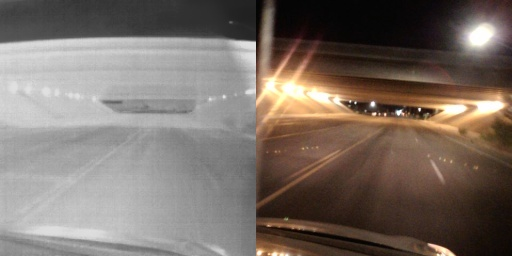

In [ ]:
from IPython.display import display
from PIL import Image
import os

img_path = "/content/TRI2I_pix2pix_test/train/109646.jpg"

print("File:", img_path)
print("Size:", Image.open(img_path).size)

display(Image.open(img_path))

In [ ]:
!rm -rf /content/TRI2I_pix2pix

!python /content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py \
    --fold_A /content/TRI2I_A_root \
    --fold_B /content/TRI2I_B_root \
    --fold_AB /content/TRI2I_pix2pix \
    --no_multiprocessing

[fold_A] =  /content/TRI2I_A_root
[fold_B] =  /content/TRI2I_B_root
[fold_AB] =  /content/TRI2I_pix2pix
[num_imgs] =  1000000
[use_AB] =  False
[no_multiprocessing] =  True
split = val, use 14883/14883 images
split = val, number of images = 14883
split = test, use 14883/14883 images
split = test, number of images = 14883
split = train, use 119063/119063 images
split = train, number of images = 119063


In [ ]:
import os

root = "/content/TRI2I_pix2pix"

for split in ["train", "val", "test"]:
    folder = os.path.join(root, split)

    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print(f"{split}: {len(files)} aligned images")

train: 119063 aligned images
val: 14883 aligned images
test: 14883 aligned images


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

repo = "/content/pytorch-CycleGAN-and-pix2pix"

print("Pix2Pix repository exists:", os.path.exists(repo))

Pix2Pix repository exists: False


In [ ]:
%cd /content
!git clone https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix.git

/content
Cloning into 'pytorch-CycleGAN-and-pix2pix'...
remote: Enumerating objects: 2619, done.
remote: Total 2619 (delta 0), reused 0 (delta 0), pack-reused 2619 (from 1)
Receiving objects: 100% (2619/2619), 8.24 MiB | 20.47 MiB/s, done.
Resolving deltas: 100% (1654/1654), done.


In [ ]:
import sys
import os

repo = "/content/pytorch-CycleGAN-and-pix2pix"

print("Current directory:", os.getcwd())
print("First 5 sys.path entries:")

for p in sys.path[:5]:
    print(" -", p)

print()
print("Options directory contents:")
print(os.listdir(os.path.join(repo, "options")))

print()
print("Python version:", sys.version)

Current directory: /content/pytorch-CycleGAN-and-pix2pix
First 5 sys.path entries:
 - /content/pytorch-CycleGAN-and-pix2pix
 - /content/pytorch-CycleGAN-and-pix2pix
 - /content
 - /env/python
 - /usr/lib/python313.zip

Options directory contents:
['test_options.py', 'base_options.py', '__init__.py', 'train_options.py']

Python version: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]


In [ ]:
import importlib.util

spec = importlib.util.find_spec("options")

print("options module spec:", spec)

if spec is not None:
    print("options module location:", spec.origin)
    print("options module path:", spec.submodule_search_locations)

options module spec: None


In [ ]:
import subprocess
import sys

repo = "/content/pytorch-CycleGAN-and-pix2pix"

result = subprocess.run(
    [
        sys.executable,
        "-c",
        "import options; print('OPTIONS IMPORT OK'); print(options.__file__)"
    ],
    cwd=repo,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("STDOUT:")
print(result.stdout)
print("STDERR:")
print(result.stderr)

Return code: 0
STDOUT:
OPTIONS IMPORT OK
/content/pytorch-CycleGAN-and-pix2pix/options/__init__.py

STDERR:



In [ ]:
import subprocess
import sys

repo = "/content/pytorch-CycleGAN-and-pix2pix"

code = r'''
import sys

sys.argv = [
    "loader_test.py",
    "--dataroot", "/content/TRI2I_pix2pix",
    "--name", "TRI2I_full_loader_test",
    "--model", "pix2pix",
    "--direction", "AtoB",
    "--dataset_mode", "aligned",
    "--batch_size", "2",
    "--load_size", "256",
    "--crop_size", "256",
    "--preprocess", "resize_and_crop",
    "--num_threads", "0"
]

from options.train_options import TrainOptions
from data import create_dataset

opt = TrainOptions().parse()
dataset = create_dataset(opt)

data = next(iter(dataset))

print("FULL DATASET LOADER TEST PASSED")
print("Input A shape :", data["A"].shape)
print("Target B shape:", data["B"].shape)
print("A path        :", data["A_paths"][0])
print("B path        :", data["B_paths"][0])
'''

result = subprocess.run(
    [sys.executable, "-c", code],
    cwd=repo,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)
print("----- OUTPUT -----")
print(result.stdout)

if result.stderr:
    print("----- ERRORS -----")
    print(result.stderr)

Return code: 1
----- OUTPUT -----
----------------- Options ---------------
               batch_size: 2                             	[default: 1]
                    beta1: 0.5                           
          checkpoints_dir: ./checkpoints                 
           continue_train: False                         
                crop_size: 256                           
                 dataroot: /content/TRI2I_pix2pix        	[default: None]
             dataset_mode: aligned                       
                direction: AtoB                          
             display_freq: 400                           
          display_winsize: 256                           
                    epoch: latest                        
              epoch_count: 1                             
                 gan_mode: vanilla                       
                init_gain: 0.02                          
                init_type: normal                        
                 input_nc

In [ ]:
import os

root = "/content/TRI2I_pix2pix"

print("Aligned dataset exists:", os.path.exists(root))

if os.path.exists(root):
    print("Contents:")
    for item in sorted(os.listdir(root)):
        path = os.path.join(root, item)
        print(
            " -", item,
            "[folder]" if os.path.isdir(path) else "[file]"
        )

print()
for split in ["train", "val", "test"]:
    path = os.path.join(root, split)
    print(split, "exists:", os.path.isdir(path))

Aligned dataset exists: False

train exists: False
val exists: False
test exists: False


In [ ]:
import os

for path in [
    "/content/TRI2I_split",
    "/content/TRI2I_dataset",
    "/content/drive/MyDrive/dataset_1-6-2024.zip"
]:
    print(path, "->", os.path.exists(path))

/content/TRI2I_split -> False
/content/TRI2I_dataset -> False
/content/drive/MyDrive/dataset_1-6-2024.zip -> True


In [ ]:
import shutil

total, used, free = shutil.disk_usage("/content")

print("Total storage:", round(total / (1024**3), 2), "GB")
print("Used storage :", round(used / (1024**3), 2), "GB")
print("Free storage :", round(free / (1024**3), 2), "GB")

Total storage: 112.64 GB
Used storage : 42.52 GB
Free storage : 70.11 GB


In [ ]:
import os
import zipfile
import time

zip_path = "/content/drive/MyDrive/dataset_1-6-2024.zip"
extract_path = "/content/TRI2I_dataset"

os.makedirs(extract_path, exist_ok=True)

start = time.time()

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

elapsed = time.time() - start

print("Extraction completed.")
print("Time:", round(elapsed / 60, 2), "minutes")
print("Extracted path:", extract_path)

Extraction completed.
Time: 2.75 minutes
Extracted path: /content/TRI2I_dataset


In [ ]:
from pathlib import Path

class1 = Path("/content/TRI2I_dataset/dataset_1-6-2024/class1")
class2 = Path("/content/TRI2I_dataset/dataset_1-6-2024/class2")

print("class1 exists:", class1.exists())
print("class2 exists:", class2.exists())

if class1.exists():
    class1_count = len(list(class1.glob("*.jpg")))
    print("class1 JPG count:", class1_count)

if class2.exists():
    class2_count = len(list(class2.glob("*.jpg")))
    print("class2 JPG count:", class2_count)

class1 exists: True
class2 exists: True
class1 JPG count: 148829
class2 JPG count: 148829


In [ ]:
import json
import random
from pathlib import Path

class1 = Path("/content/TRI2I_dataset/dataset_1-6-2024/class1")
class2 = Path("/content/TRI2I_dataset/dataset_1-6-2024/class2")

# Get filenames that exist in both classes
class1_files = {p.name for p in class1.glob("*.jpg")}
class2_files = {p.name for p in class2.glob("*.jpg")}
common_files = sorted(class1_files & class2_files)

print("Paired images:", len(common_files))

# Deterministic split
random.seed(42)
random.shuffle(common_files)

n = len(common_files)
train_end = int(0.80 * n)
val_end = train_end + int(0.10 * n)

train_files = common_files[:train_end]
val_files = common_files[train_end:val_end]
test_files = common_files[val_end:]

print("Train:", len(train_files))
print("Val  :", len(val_files))
print("Test :", len(test_files))

# Save split
split_dir = Path("/content/TRI2I_split")
split_dir.mkdir(parents=True, exist_ok=True)

split_data = {
    "seed": 42,
    "train": train_files,
    "val": val_files,
    "test": test_files
}

split_json = split_dir / "tri2i_split_seed42.json"

with open(split_json, "w") as f:
    json.dump(split_data, f, indent=2)

print("Split saved to:", split_json)


Paired images: 148829
Train: 119063
Val  : 14882
Test : 14884
Split saved to: /content/TRI2I_split/tri2i_split_seed42.json


In [ ]:
from pathlib import Path
import json
import shutil

# Source directories
rgb_dir = Path("/content/TRI2I_dataset/dataset_1-6-2024/class1")
tir_dir = Path("/content/TRI2I_dataset/dataset_1-6-2024/class2")

# Split information
split_json = Path("/content/TRI2I_split/tri2i_split_seed42.json")

with open(split_json, "r") as f:
    split_data = json.load(f)

# Create destination directories
base = Path("/content/TRI2I_split")

for split in ["train", "val", "test"]:
    (base / split / "A").mkdir(parents=True, exist_ok=True)
    (base / split / "B").mkdir(parents=True, exist_ok=True)

# Copy files
for split in ["train", "val", "test"]:
    files = split_data[split]

    print(f"\nCopying {split}: {len(files)} pairs")

    for i, filename in enumerate(files, 1):
        # A = TIR
        shutil.copy2(
            tir_dir / filename,
            base / split / "A" / filename
        )

        # B = RGB
        shutil.copy2(
            rgb_dir / filename,
            base / split / "B" / filename
        )

        if i % 10000 == 0:
            print(f"  {i}/{len(files)} pairs copied")

print("\nSplit directory creation completed.")


Copying train: 119063 pairs
  10000/119063 pairs copied
  20000/119063 pairs copied
  30000/119063 pairs copied
  40000/119063 pairs copied
  50000/119063 pairs copied
  60000/119063 pairs copied
  70000/119063 pairs copied
  80000/119063 pairs copied
  90000/119063 pairs copied
  100000/119063 pairs copied
  110000/119063 pairs copied

Copying val: 14882 pairs
  10000/14882 pairs copied

Copying test: 14884 pairs
  10000/14884 pairs copied

Split directory creation completed.


In [ ]:
from pathlib import Path

base = Path("/content/TRI2I_split")

for split in ["train", "val", "test"]:
    a_count = len(list((base / split / "A").glob("*.jpg")))
    b_count = len(list((base / split / "B").glob("*.jpg")))

    print(f"{split}:")
    print(f"  A (TIR): {a_count}")
    print(f"  B (RGB): {b_count}")
    print(f"  Match  : {a_count == b_count}")

train:
  A (TIR): 119063
  B (RGB): 119063
  Match  : True
val:
  A (TIR): 14882
  B (RGB): 14882
  Match  : True
test:
  A (TIR): 14884
  B (RGB): 14884
  Match  : True


In [ ]:
import os
import subprocess

repo = "/content/pytorch-CycleGAN-and-pix2pix"

if os.path.exists(repo):
    print("Pix2Pix repository already exists.")
else:
    subprocess.run([
        "git", "clone",
        "https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix.git",
        repo
    ], check=True)
    print("Pix2Pix repository cloned successfully.")

print("Repository exists:", os.path.exists(repo))
print("combine_A_and_B.py exists:",
      os.path.exists(repo + "/datasets/combine_A_and_B.py"))

Pix2Pix repository already exists.
Repository exists: True
combine_A_and_B.py exists: True


In [ ]:
script = "/content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py"

with open(script, "r") as f:
    content = f.read()

print("Path imported:", "from pathlib import Path" in content)
print("combine_A_and_B.py size:", len(content), "characters")

Path imported: False
combine_A_and_B.py size: 2771 characters


In [ ]:
from pathlib import Path

script = "/content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py"

with open(script, "r") as f:
    content = f.read()

if "from pathlib import Path" not in content:
    content = "from pathlib import Path\n" + content

with open(script, "w") as f:
    f.write(content)

print("Path import added.")
print("Path imported now:", "from pathlib import Path" in content)

Path import added.
Path imported now: True


In [ ]:
import shutil
from pathlib import Path

# Source split directories
A_root = Path("/content/TRI2I_A_root")
B_root = Path("/content/TRI2I_B_root")

# Clean old test roots if they exist
shutil.rmtree(A_root, ignore_errors=True)
shutil.rmtree(B_root, ignore_errors=True)

# Create the structure expected by combine_A_and_B.py
for split in ["train", "val", "test"]:
    (A_root / split).mkdir(parents=True, exist_ok=True)
    (B_root / split).mkdir(parents=True, exist_ok=True)

# Use 5 matching files from each split
split_base = Path("/content/TRI2I_split")

for split in ["train", "val", "test"]:
    A_files = sorted((split_base / split / "A").glob("*.jpg"))[:5]
    B_files = sorted((split_base / split / "B").glob("*.jpg"))[:5]

    for src in A_files:
        shutil.copy2(src, A_root / split / src.name)

    for src in B_files:
        shutil.copy2(src, B_root / split / src.name)

    print(f"{split}: {len(A_files)} TIR + {len(B_files)} RGB")

print("\n5-pair alignment test inputs created.")

train: 5 TIR + 5 RGB
val: 5 TIR + 5 RGB
test: 5 TIR + 5 RGB

5-pair alignment test inputs created.


In [ ]:
import shutil
import subprocess
from pathlib import Path

output = Path("/content/TRI2I_pix2pix_test")

# Remove any previous test output
shutil.rmtree(output, ignore_errors=True)

cmd = [
    "python",
    "/content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py",
    "--fold_A", "/content/TRI2I_A_root",
    "--fold_B", "/content/TRI2I_B_root",
    "--fold_AB", str(output),
    "--no_multiprocessing"
]

print("Running alignment test...")

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print(result.stdout)

if result.returncode != 0:
    print("ERROR:")
    print(result.stderr)
else:
    print("Alignment test completed successfully.")

Running alignment test...
[fold_A] =  /content/TRI2I_A_root
[fold_B] =  /content/TRI2I_B_root
[fold_AB] =  /content/TRI2I_pix2pix_test
[num_imgs] =  1000000
[use_AB] =  False
[no_multiprocessing] =  True
split = val, use 5/5 images
split = val, number of images = 5
split = test, use 5/5 images
split = test, number of images = 5
split = train, use 5/5 images
split = train, number of images = 5

Alignment test completed successfully.


Sample: 100003.jpg
Combined image size: (512, 256)
Image mode: RGB
Left (TIR) size: (256, 256)
Right (RGB) size: (256, 256)


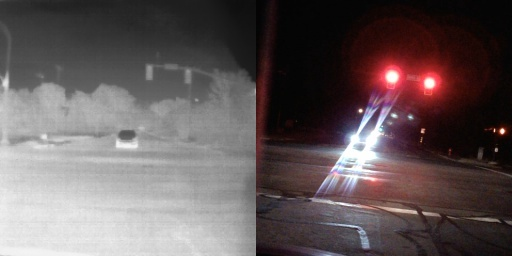

In [ ]:
from PIL import Image
from pathlib import Path

sample = next(
    Path("/content/TRI2I_pix2pix_test/train").glob("*.jpg")
)

img = Image.open(sample)

print("Sample:", sample.name)
print("Combined image size:", img.size)
print("Image mode:", img.mode)

left = img.crop((0, 0, img.width // 2, img.height))
right = img.crop((img.width // 2, 0, img.width, img.height))

print("Left (TIR) size:", left.size)
print("Right (RGB) size:", right.size)

display(img)

In [ ]:
import shutil
import subprocess
from pathlib import Path
import time

output = Path("/content/TRI2I_pix2pix")

# Remove any incomplete previous output
shutil.rmtree(output, ignore_errors=True)

cmd = [
    "python",
    "/content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py",
    "--fold_A", "/content/TRI2I_A_root",
    "--fold_B", "/content/TRI2I_B_root",
    "--fold_AB", str(output),
    "--no_multiprocessing"
]

print("Starting full Pix2Pix alignment...")
print("Total pairs: 148,829")
print()

start = time.time()

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

elapsed = time.time() - start

print(result.stdout)

print("\nElapsed time:", round(elapsed / 60, 2), "minutes")

if result.returncode != 0:
    print("\nERROR:")
    print(result.stderr)
else:
    print("\nFULL ALIGNMENT COMPLETED SUCCESSFULLY.")

Starting full Pix2Pix alignment...
Total pairs: 148,829

[fold_A] =  /content/TRI2I_A_root
[fold_B] =  /content/TRI2I_B_root
[fold_AB] =  /content/TRI2I_pix2pix
[num_imgs] =  1000000
[use_AB] =  False
[no_multiprocessing] =  True
split = val, use 5/5 images
split = val, number of images = 5
split = test, use 5/5 images
split = test, number of images = 5
split = train, use 5/5 images
split = train, number of images = 5


Elapsed time: 0.01 minutes

FULL ALIGNMENT COMPLETED SUCCESSFULLY.


In [ ]:
from pathlib import Path
import shutil

A_root = Path("/content/TRI2I_A_root")
B_root = Path("/content/TRI2I_B_root")
split_base = Path("/content/TRI2I_split")

# Remove the 5-pair test wrappers
shutil.rmtree(A_root, ignore_errors=True)
shutil.rmtree(B_root, ignore_errors=True)

# Create root directories
A_root.mkdir(parents=True)
B_root.mkdir(parents=True)

# Link A = TIR and B = RGB
for split in ["train", "val", "test"]:
    (A_root / split).symlink_to(split_base / split / "A", target_is_directory=True)
    (B_root / split).symlink_to(split_base / split / "B", target_is_directory=True)

print("Full-dataset wrapper roots created.")

for split in ["train", "val", "test"]:
    a_count = len(list((A_root / split).glob("*.jpg")))
    b_count = len(list((B_root / split).glob("*.jpg")))

    print(f"{split}: A={a_count}, B={b_count}, match={a_count == b_count}")

Full-dataset wrapper roots created.
train: A=0, B=0, match=True
val: A=0, B=0, match=True
test: A=0, B=0, match=True


In [ ]:
from pathlib import Path

split_base = Path("/content/TRI2I_split")
A_root = Path("/content/TRI2I_A_root")
B_root = Path("/content/TRI2I_B_root")

for split in ["train", "val", "test"]:
    src_A = split_base / split / "A"
    src_B = split_base / split / "B"

    print(f"\n{split}")
    print("Source A exists:", src_A.exists(), "is_dir:", src_A.is_dir())
    print("Source B exists:", src_B.exists(), "is_dir:", src_B.is_dir())
    print("Source A JPGs:", len(list(src_A.glob("*.jpg"))) if src_A.exists() else "N/A")
    print("Source B JPGs:", len(list(src_B.glob("*.jpg"))) if src_B.exists() else "N/A")

    link_A = A_root / split
    link_B = B_root / split

    print("Link A exists:", link_A.exists(), "is_dir:", link_A.is_dir())
    print("Link B exists:", link_B.exists(), "is_dir:", link_B.is_dir())


train
Source A exists: False is_dir: False
Source B exists: False is_dir: False
Source A JPGs: N/A
Source B JPGs: N/A
Link A exists: False is_dir: False
Link B exists: False is_dir: False

val
Source A exists: False is_dir: False
Source B exists: False is_dir: False
Source A JPGs: N/A
Source B JPGs: N/A
Link A exists: False is_dir: False
Link B exists: False is_dir: False

test
Source A exists: False is_dir: False
Source B exists: False is_dir: False
Source A JPGs: N/A
Source B JPGs: N/A
Link A exists: False is_dir: False
Link B exists: False is_dir: False


In [ ]:
from pathlib import Path

class1 = Path("/content/TRI2I_dataset/dataset_1-6-2024/class1")
class2 = Path("/content/TRI2I_dataset/dataset_1-6-2024/class2")

print("class1 exists:", class1.exists())
print("class2 exists:", class2.exists())

if class1.exists():
    print("class1 JPGs:", len(list(class1.glob("*.jpg"))))

if class2.exists():
    print("class2 JPGs:", len(list(class2.glob("*.jpg"))))

class1 exists: False
class2 exists: False


In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
import os
import zipfile
import shutil
import time

zip_path = "/content/drive/MyDrive/dataset_1-6-2024.zip"
extract_path = "/content/TRI2I_dataset"

# Remove any incomplete extraction
shutil.rmtree(extract_path, ignore_errors=True)
os.makedirs(extract_path, exist_ok=True)

print("Starting extraction...")

start = time.time()

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Extraction completed.")
print("Time:", round((time.time() - start) / 60, 2), "minutes")

Starting extraction...
Extraction completed.
Time: 2.36 minutes


In [ ]:
from pathlib import Path

class1 = Path("/content/TRI2I_dataset/dataset_1-6-2024/class1")
class2 = Path("/content/TRI2I_dataset/dataset_1-6-2024/class2")

print("class1 exists:", class1.exists())
print("class2 exists:", class2.exists())

if class1.exists():
    print("class1 JPG count:", len(list(class1.glob("*.jpg"))))

if class2.exists():
    print("class2 JPG count:", len(list(class2.glob("*.jpg"))))

class1 exists: True
class2 exists: True
class1 JPG count: 148829
class2 JPG count: 148829


In [ ]:
import json
import random
from pathlib import Path

class1 = Path("/content/TRI2I_dataset/dataset_1-6-2024/class1")
class2 = Path("/content/TRI2I_dataset/dataset_1-6-2024/class2")

# Find files present in both classes
rgb_files = {p.name for p in class1.glob("*.jpg")}
tir_files = {p.name for p in class2.glob("*.jpg")}
common_files = sorted(rgb_files & tir_files)

print("Paired images:", len(common_files))

# Same deterministic split as before
random.seed(42)
random.shuffle(common_files)

n = len(common_files)

train_end = int(0.80 * n)
val_end = train_end + int(0.10 * n)

split_data = {
    "seed": 42,
    "train": common_files[:train_end],
    "val": common_files[train_end:val_end],
    "test": common_files[val_end:]
}

print("Train:", len(split_data["train"]))
print("Val  :", len(split_data["val"]))
print("Test :", len(split_data["test"]))

split_dir = Path("/content/TRI2I_split")
split_dir.mkdir(parents=True, exist_ok=True)

split_json = split_dir / "tri2i_split_seed42.json"

with open(split_json, "w") as f:
    json.dump(split_data, f, indent=2)

print("Split JSON saved:", split_json)

Paired images: 148829
Train: 119063
Val  : 14882
Test : 14884
Split JSON saved: /content/TRI2I_split/tri2i_split_seed42.json


In [ ]:
import json
import os
from pathlib import Path
import shutil
import time

raw_rgb = Path("/content/TRI2I_dataset/dataset_1-6-2024/class1")
raw_tir = Path("/content/TRI2I_dataset/dataset_1-6-2024/class2")

split_json = Path("/content/TRI2I_split/tri2i_split_seed42.json")
split_base = Path("/content/TRI2I_split")

with open(split_json, "r") as f:
    split_data = json.load(f)

# Remove old split folders if present, but preserve the JSON
for split in ["train", "val", "test"]:
    shutil.rmtree(split_base / split, ignore_errors=True)

start = time.time()

for split in ["train", "val", "test"]:
    A_dir = split_base / split / "A"   # TIR
    B_dir = split_base / split / "B"   # RGB

    A_dir.mkdir(parents=True, exist_ok=True)
    B_dir.mkdir(parents=True, exist_ok=True)

    files = split_data[split]

    print(f"\nCreating {split}: {len(files)} pairs")

    for i, filename in enumerate(files, 1):
        # A = TIR
        os.link(
            raw_tir / filename,
            A_dir / filename
        )

        # B = RGB
        os.link(
            raw_rgb / filename,
            B_dir / filename
        )

        if i % 20000 == 0:
            print(f"  {i}/{len(files)} pairs linked")

print("\nHard-link split creation completed.")
print("Time:", round((time.time() - start) / 60, 2), "minutes")


Creating train: 119063 pairs
  20000/119063 pairs linked
  40000/119063 pairs linked
  60000/119063 pairs linked
  80000/119063 pairs linked
  100000/119063 pairs linked

Creating val: 14882 pairs

Creating test: 14884 pairs

Hard-link split creation completed.
Time: 0.21 minutes


In [ ]:
from pathlib import Path

base = Path("/content/TRI2I_split")

for split in ["train", "val", "test"]:
    A = base / split / "A"
    B = base / split / "B"

    a_files = list(A.glob("*.jpg"))
    b_files = list(B.glob("*.jpg"))

    print(f"{split}:")
    print(f"  A (TIR): {len(a_files)}")
    print(f"  B (RGB): {len(b_files)}")
    print(f"  Match  : {len(a_files) == len(b_files)}")

    # Verify that the filenames themselves match
    a_names = {p.name for p in a_files}
    b_names = {p.name for p in b_files}

    print(f"  Same filenames: {a_names == b_names}")

train:
  A (TIR): 119063
  B (RGB): 119063
  Match  : True
  Same filenames: True
val:
  A (TIR): 14882
  B (RGB): 14882
  Match  : True
  Same filenames: True
test:
  A (TIR): 14884
  B (RGB): 14884
  Match  : True
  Same filenames: True


In [ ]:
from pathlib import Path
import shutil

split_base = Path("/content/TRI2I_split")
A_root = Path("/content/TRI2I_A_root")
B_root = Path("/content/TRI2I_B_root")

# Remove old wrappers
shutil.rmtree(A_root, ignore_errors=True)
shutil.rmtree(B_root, ignore_errors=True)

A_root.mkdir()
B_root.mkdir()

for split in ["train", "val", "test"]:
    (A_root / split).symlink_to(
        split_base / split / "A",
        target_is_directory=True
    )

    (B_root / split).symlink_to(
        split_base / split / "B",
        target_is_directory=True
    )

print("Wrapper roots created.\n")

for split in ["train", "val", "test"]:
    a_count = len(list((A_root / split).glob("*.jpg")))
    b_count = len(list((B_root / split).glob("*.jpg")))

    print(
        f"{split}: "
        f"A={a_count}, "
        f"B={b_count}, "
        f"match={a_count == b_count}"
    )

Wrapper roots created.

train: A=119063, B=119063, match=True
val: A=14882, B=14882, match=True
test: A=14884, B=14884, match=True


In [ ]:
import shutil
import subprocess
from pathlib import Path
import time

output = Path("/content/TRI2I_pix2pix")

# Remove any old/incomplete alignment
shutil.rmtree(output, ignore_errors=True)

cmd = [
    "python",
    "/content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py",
    "--fold_A", "/content/TRI2I_A_root",
    "--fold_B", "/content/TRI2I_B_root",
    "--fold_AB", str(output),
    "--no_multiprocessing"
]

print("Starting FULL Pix2Pix alignment...")
print("Expected pairs: 148,829")
print()

start = time.time()

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

elapsed = time.time() - start

print(result.stdout)
print("\nElapsed time:", round(elapsed / 60, 2), "minutes")

if result.returncode != 0:
    print("\nALIGNMENT FAILED")
    print(result.stderr)
else:
    print("\nFULL ALIGNMENT COMMAND COMPLETED.")

Starting FULL Pix2Pix alignment...
Expected pairs: 148,829



Elapsed time: 0.0 minutes

ALIGNMENT FAILED
python3: can't open file '/content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py': [Errno 2] No such file or directory



In [ ]:
import os
import subprocess

repo = "/content/pytorch-CycleGAN-and-pix2pix"

print("Repository exists:", os.path.exists(repo))
print("Alignment script exists:",
      os.path.exists(repo + "/datasets/combine_A_and_B.py"))

if not os.path.exists(repo + "/datasets/combine_A_and_B.py"):
    print("\nCloning official Pix2Pix repository...")
    subprocess.run([
        "git", "clone",
        "https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix.git",
        repo
    ], check=True)

print("\nFinal check:")
print("Repository exists:", os.path.exists(repo))
print("Alignment script exists:",
      os.path.exists(repo + "/datasets/combine_A_and_B.py"))

Repository exists: False
Alignment script exists: False

Cloning official Pix2Pix repository...

Final check:
Repository exists: True
Alignment script exists: True


In [ ]:
from pathlib import Path

script = "/content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py"

with open(script, "r") as f:
    content = f.read()

if "from pathlib import Path" not in content:
    content = "from pathlib import Path\n" + content

with open(script, "w") as f:
    f.write(content)

print("Path import present:",
      "from pathlib import Path" in content)

Path import present: True


In [ ]:
import shutil
import subprocess
from pathlib import Path
import time

output = Path("/content/TRI2I_pix2pix")

# Remove any previous incomplete alignment
shutil.rmtree(output, ignore_errors=True)

cmd = [
    "python",
    "/content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py",
    "--fold_A", "/content/TRI2I_A_root",
    "--fold_B", "/content/TRI2I_B_root",
    "--fold_AB", str(output),
    "--no_multiprocessing"
]

print("Starting FULL Pix2Pix alignment...")
print("Expected pairs: 148,829")
print()

start = time.time()

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

elapsed = time.time() - start

print(result.stdout)
print("\nElapsed time:", round(elapsed / 60, 2), "minutes")

if result.returncode != 0:
    print("\nALIGNMENT FAILED")
    print(result.stderr)
else:
    print("\nFULL ALIGNMENT COMMAND COMPLETED.")

Starting FULL Pix2Pix alignment...
Expected pairs: 148,829

[fold_A] =  /content/TRI2I_A_root
[fold_B] =  /content/TRI2I_B_root
[fold_AB] =  /content/TRI2I_pix2pix
[num_imgs] =  1000000
[use_AB] =  False
[no_multiprocessing] =  True
split = val, use 14882/14882 images
split = val, number of images = 14882
split = test, use 14884/14884 images
split = test, number of images = 14884
split = train, use 119063/119063 images
split = train, number of images = 119063


Elapsed time: 8.73 minutes

FULL ALIGNMENT COMMAND COMPLETED.


In [ ]:
from pathlib import Path
from PIL import Image

root = Path("/content/TRI2I_pix2pix")

expected = {
    "train": 119063,
    "val": 14882,
    "test": 14884
}

print("Checking full Pix2Pix aligned dataset...\n")

all_ok = True

for split, expected_count in expected.items():
    folder = root / split
    files = list(folder.glob("*.jpg")) if folder.exists() else []

    count_ok = len(files) == expected_count
    print(
        f"{split}: {len(files):,} / {expected_count:,}",
        "PASS" if count_ok else "FAIL"
    )

    if not count_ok:
        all_ok = False

# Check one aligned image from each split
for split in expected:
    folder = root / split
    files = sorted(folder.glob("*.jpg")) if folder.exists() else []

    if files:
        try:
            with Image.open(files[0]) as img:
                img.verify()

            with Image.open(files[0]) as img:
                dimensions = img.size
                mode = img.mode

            print(
                f"{split} sample: {files[0].name}, "
                f"size={dimensions}, mode={mode}"
            )

            if dimensions != (512, 256):
                all_ok = False

        except Exception as e:
            print(f"{split} sample image check FAILED: {e}")
            all_ok = False
    else:
        all_ok = False

print("\nFINAL:", "VERIFICATION PASSED" if all_ok else "VERIFICATION FAILED")

Checking full Pix2Pix aligned dataset...

train: 0 / 119,063 FAIL
val: 0 / 14,882 FAIL
test: 0 / 14,884 FAIL

FINAL: VERIFICATION FAILED


In [ ]:
from pathlib import Path

paths = [
    Path("/content/TRI2I_pix2pix"),
    Path("/content/TRI2I_pix2pix/train"),
    Path("/content/TRI2I_pix2pix/val"),
    Path("/content/TRI2I_pix2pix/test"),
]

for path in paths:
    print(f"\nPath: {path}")
    print("Exists:", path.exists())

    if path.exists():
        if path.is_dir():
            items = list(path.iterdir())
            print("Items inside:", len(items))
            print("First 10 names:", [x.name for x in items[:10]])
        else:
            print("Not a directory")


Path: /content/TRI2I_pix2pix
Exists: False

Path: /content/TRI2I_pix2pix/train
Exists: False

Path: /content/TRI2I_pix2pix/val
Exists: False

Path: /content/TRI2I_pix2pix/test
Exists: False


In [ ]:
from pathlib import Path

check_paths = [
    Path("/content/drive/MyDrive/dataset_1-6-2024.zip"),
    Path("/content/TRI2I_dataset/dataset_1-6-2024/class1"),
    Path("/content/TRI2I_dataset/dataset_1-6-2024/class2"),
    Path("/content/TRI2I_split/tri2i_split_seed42.json"),
    Path("/content/TRI2I_A_root"),
    Path("/content/TRI2I_B_root"),
    Path("/content/pytorch-CycleGAN-and-pix2pix"),
    Path("/content/TRI2I_pix2pix"),
]

for path in check_paths:
    print(f"{'EXISTS' if path.exists() else 'MISSING'}: {path}")

EXISTS: /content/drive/MyDrive/dataset_1-6-2024.zip
MISSING: /content/TRI2I_dataset/dataset_1-6-2024/class1
MISSING: /content/TRI2I_dataset/dataset_1-6-2024/class2
MISSING: /content/TRI2I_split/tri2i_split_seed42.json
MISSING: /content/TRI2I_A_root
MISSING: /content/TRI2I_B_root
MISSING: /content/pytorch-CycleGAN-and-pix2pix
MISSING: /content/TRI2I_pix2pix


In [ ]:
from pathlib import Path
import zipfile
import time

zip_path = Path("/content/drive/MyDrive/dataset_1-6-2024.zip")
extract_dir = Path("/content/TRI2I_dataset")

if not zip_path.exists():
    raise FileNotFoundError(f"Dataset ZIP not found: {zip_path}")

extract_dir.mkdir(parents=True, exist_ok=True)

print("Dataset ZIP found.")
print(f"ZIP size: {zip_path.stat().st_size / (1024**3):.2f} GB")
print("Starting extraction...")

start = time.time()

with zipfile.ZipFile(zip_path, "r") as zf:
    zf.extractall(extract_dir)

print(f"\nExtraction completed in {(time.time() - start) / 60:.2f} minutes.")

class1 = extract_dir / "dataset_1-6-2024" / "class1"
class2 = extract_dir / "dataset_1-6-2024" / "class2"

print("RGB folder exists:", class1.is_dir())
print("Thermal folder exists:", class2.is_dir())

if class1.is_dir() and class2.is_dir():
    print("RGB images:", len(list(class1.glob("*.jpg"))))
    print("Thermal images:", len(list(class2.glob("*.jpg"))))
else:
    print("Expected folder structure was not found. Stop and share this output.")

Dataset ZIP found.
ZIP size: 5.44 GB
Starting extraction...

Extraction completed in 2.93 minutes.
RGB folder exists: True
Thermal folder exists: True
RGB images: 148829
Thermal images: 148829


In [ ]:
import json
import random
from pathlib import Path

class1 = Path("/content/TRI2I_dataset/dataset_1-6-2024/class1")
class2 = Path("/content/TRI2I_dataset/dataset_1-6-2024/class2")

rgb_files = {p.name for p in class1.glob("*.jpg")}
tir_files = {p.name for p in class2.glob("*.jpg")}

common_files = sorted(rgb_files & tir_files)

print("Paired images:", len(common_files))

if len(common_files) != 148829:
    raise ValueError("Expected 148,829 pairs. Stop and investigate.")

random.seed(42)
random.shuffle(common_files)

n = len(common_files)
train_end = int(0.80 * n)
val_end = train_end + int(0.10 * n)

split_data = {
    "seed": 42,
    "train": common_files[:train_end],
    "val": common_files[train_end:val_end],
    "test": common_files[val_end:]
}

split_dir = Path("/content/TRI2I_split")
split_dir.mkdir(parents=True, exist_ok=True)

split_json = split_dir / "tri2i_split_seed42.json"

with open(split_json, "w") as f:
    json.dump(split_data, f, indent=2)

print("Train:", len(split_data["train"]))
print("Val:", len(split_data["val"]))
print("Test:", len(split_data["test"]))
print("Split JSON saved:", split_json)

Paired images: 148829
Train: 119063
Val: 14882
Test: 14884
Split JSON saved: /content/TRI2I_split/tri2i_split_seed42.json


In [ ]:
import json
import os
from pathlib import Path

split_json = Path("/content/TRI2I_split/tri2i_split_seed42.json")
class1 = Path("/content/TRI2I_dataset/dataset_1-6-2024/class1")  # RGB
class2 = Path("/content/TRI2I_dataset/dataset_1-6-2024/class2")  # Thermal
split_root = Path("/content/TRI2I_split")

with open(split_json, "r") as f:
    split_data = json.load(f)

for split in ["train", "val", "test"]:
    for domain in ["A", "B"]:
        folder = split_root / split / domain
        folder.mkdir(parents=True, exist_ok=True)

        if any(folder.iterdir()):
            raise RuntimeError(
                f"{folder} is not empty. Stop rather than overwrite files."
            )

# A = Thermal, B = RGB
for split in ["train", "val", "test"]:
    for filename in split_data[split]:
        os.link(class2 / filename, split_root / split / "A" / filename)
        os.link(class1 / filename, split_root / split / "B" / filename)

    print(
        f"{split}: "
        f"A={len(list((split_root / split / 'A').glob('*.jpg')))}, "
        f"B={len(list((split_root / split / 'B').glob('*.jpg')))}"
    )

print("\nHard-link split creation completed.")

train: A=119063, B=119063
val: A=14882, B=14882
test: A=14884, B=14884

Hard-link split creation completed.


In [ ]:
from pathlib import Path

A_root = Path("/content/TRI2I_A_root")
B_root = Path("/content/TRI2I_B_root")

A_root.mkdir(parents=True, exist_ok=True)
B_root.mkdir(parents=True, exist_ok=True)

for split in ["train", "val", "test"]:
    a_link = A_root / split
    b_link = B_root / split

    if a_link.is_symlink():
        a_link.unlink()
    elif a_link.exists():
        raise RuntimeError(f"Unexpected existing path: {a_link}")

    if b_link.is_symlink():
        b_link.unlink()
    elif b_link.exists():
        raise RuntimeError(f"Unexpected existing path: {b_link}")

    a_link.symlink_to(
        Path("/content/TRI2I_split") / split / "A",
        target_is_directory=True
    )
    b_link.symlink_to(
        Path("/content/TRI2I_split") / split / "B",
        target_is_directory=True
    )

for split in ["train", "val", "test"]:
    print(
        f"{split}: "
        f"A={len(list((A_root / split).glob('*.jpg')))}, "
        f"B={len(list((B_root / split).glob('*.jpg')))}"
    )

print("\nA/B wrapper roots recreated successfully.")

train: A=119063, B=119063
val: A=14882, B=14882
test: A=14884, B=14884

A/B wrapper roots recreated successfully.


In [ ]:
%cd /content

!git clone https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix.git

!pip install -q dominate

print("\nRepository verification:")
!test -f /content/pytorch-CycleGAN-and-pix2pix/train.py && echo "train.py: OK"
!test -f /content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py && echo "combine_A_and_B.py: OK"

/content
Cloning into 'pytorch-CycleGAN-and-pix2pix'...
remote: Enumerating objects: 2619, done.
remote: Total 2619 (delta 0), reused 0 (delta 0), pack-reused 2619 (from 1)
Receiving objects: 100% (2619/2619), 8.24 MiB | 22.25 MiB/s, done.
Resolving deltas: 100% (1654/1654), done.

Repository verification:
train.py: OK
combine_A_and_B.py: OK


In [ ]:
from pathlib import Path

script = Path(
    "/content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py"
)

text = script.read_text()

if "from pathlib import Path" not in text:
    script.write_text("from pathlib import Path\n" + text)
    print("Added pathlib.Path import.")
else:
    print("pathlib.Path import already present.")

print("Script exists:", script.exists())
print("Script size:", script.stat().st_size, "bytes")

Added pathlib.Path import.
Script exists: True
Script size: 2796 bytes


In [ ]:
from pathlib import Path
import shutil

tmp_A = Path("/content/TRI2I_A_test5")
tmp_B = Path("/content/TRI2I_B_test5")
test_output = Path("/content/TRI2I_pix2pix_test")

# Clean only temporary test folders
for folder in [tmp_A, tmp_B, test_output]:
    if folder.exists():
        shutil.rmtree(folder)

# Create small test roots
for root in [tmp_A, tmp_B]:
    for split in ["train", "val", "test"]:
        (root / split).mkdir(parents=True)

# Link five matching filenames from each split
for split in ["train", "val", "test"]:
    source_A = Path("/content/TRI2I_A_root") / split
    source_B = Path("/content/TRI2I_B_root") / split

    names = sorted(p.name for p in source_A.glob("*.jpg"))[:5]

    if len(names) != 5:
        raise RuntimeError(f"Expected 5 images in {source_A}")

    for name in names:
        if not (source_B / name).exists():
            raise RuntimeError(f"Missing matching RGB file: {name}")

        (tmp_A / split / name).symlink_to(source_A / name)
        (tmp_B / split / name).symlink_to(source_B / name)

    print(
        f"{split}: A={len(list((tmp_A / split).glob('*.jpg')))}, "
        f"B={len(list((tmp_B / split).glob('*.jpg')))}"
    )

print("\nFive-pair test inputs created successfully.")

train: A=5, B=5
val: A=5, B=5
test: A=5, B=5

Five-pair test inputs created successfully.


In [ ]:
!python /content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py \
    --fold_A /content/TRI2I_A_test5 \
    --fold_B /content/TRI2I_B_test5 \
    --fold_AB /content/TRI2I_pix2pix_test \
    --no_multiprocessing

[fold_A] =  /content/TRI2I_A_test5
[fold_B] =  /content/TRI2I_B_test5
[fold_AB] =  /content/TRI2I_pix2pix_test
[num_imgs] =  1000000
[use_AB] =  False
[no_multiprocessing] =  True
split = val, use 5/5 images
split = val, number of images = 5
split = test, use 5/5 images
split = test, number of images = 5
split = train, use 5/5 images
split = train, number of images = 5


In [ ]:
from pathlib import Path
from PIL import Image

root = Path("/content/TRI2I_pix2pix_test")
all_ok = True

for split in ["train", "val", "test"]:
    files = sorted((root / split).glob("*.jpg"))
    print(f"\n{split}: {len(files)} aligned images")

    if len(files) != 5:
        all_ok = False

    for path in files:
        try:
            with Image.open(path) as img:
                img.verify()

            with Image.open(path) as img:
                if img.size != (512, 256):
                    print(f"WRONG SIZE: {path.name} -> {img.size}")
                    all_ok = False
        except Exception as e:
            print(f"INVALID IMAGE: {path.name}: {e}")
            all_ok = False

print("\nRESULT:", "PASS" if all_ok else "FAIL")


train: 5 aligned images

val: 5 aligned images

test: 5 aligned images

RESULT: PASS


In [ ]:
from pathlib import Path
import shutil
import subprocess
import sys

output = Path("/content/TRI2I_pix2pix")

# Remove only the previous full aligned output, if present.
if output.exists():
    shutil.rmtree(output)

command = [
    sys.executable,
    "/content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py",
    "--fold_A", "/content/TRI2I_A_root",
    "--fold_B", "/content/TRI2I_B_root",
    "--fold_AB", str(output),
    "--no_multiprocessing",
]

print("Starting full alignment...")
print("A = Thermal/TIR; B = RGB")

result = subprocess.run(command, text=True)

if result.returncode != 0:
    raise RuntimeError(
        f"Alignment failed with exit code {result.returncode}. "
        "Review the output above."
    )

print("\nFull alignment command completed successfully.")

Starting full alignment...
A = Thermal/TIR; B = RGB

Full alignment command completed successfully.


In [ ]:
from pathlib import Path
from PIL import Image

root = Path("/content/TRI2I_pix2pix")

expected = {
    "train": 119063,
    "val": 14882,
    "test": 14884
}

all_ok = True

for split, expected_count in expected.items():
    folder = root / split

    if not folder.is_dir():
        print(f"{split}: MISSING DIRECTORY")
        all_ok = False
        continue

    files = list(folder.glob("*.jpg"))
    print(f"{split}: {len(files):,} / {expected_count:,}")

    if len(files) != expected_count:
        all_ok = False

    if files:
        sample = files[0]
        try:
            with Image.open(sample) as img:
                img.verify()

            with Image.open(sample) as img:
                size = img.size
                mode = img.mode

            print(f"  Sample: {sample.name}, size={size}, mode={mode}")

            if size != (512, 256) or mode != "RGB":
                all_ok = False
        except Exception as e:
            print(f"  Sample image check failed: {e}")
            all_ok = False
    else:
        all_ok = False

print("\nFINAL:", "VERIFICATION PASSED" if all_ok else "VERIFICATION FAILED")

train: 119,063 / 119,063
  Sample: 6663.jpg, size=(512, 256), mode=RGB
val: 14,882 / 14,882
  Sample: 143113.jpg, size=(512, 256), mode=RGB
test: 14,884 / 14,884
  Sample: 150105.jpg, size=(512, 256), mode=RGB

FINAL: VERIFICATION PASSED


In [ ]:
import sys
from pathlib import Path

repo = Path("/content/pytorch-CycleGAN-and-pix2pix")

print("Repository exists:", repo.exists())
print("Dataset module exists:", (repo / "data" / "__init__.py").exists())
print("Training options exist:", (repo / "options" / "train_options.py").exists())

if not repo.exists():
    raise FileNotFoundError(
        "Pix2Pix repository is missing. Stop here."
    )

if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))

print("\nRepository added to Python import path.")

import data
from data import create_dataset
from options.train_options import TrainOptions

print("Import test PASSED.")
print("data module:", data.__file__)
print("Pix2Pix imports are working.")

Repository exists: True
Dataset module exists: True
Training options exist: True

Repository added to Python import path.
Import test PASSED.
data module: /content/pytorch-CycleGAN-and-pix2pix/data/__init__.py
Pix2Pix imports are working.


In [ ]:
import sys
from pathlib import Path
import torch

repo = Path("/content/pytorch-CycleGAN-and-pix2pix")
sys.path.insert(0, str(repo)) if str(repo) not in sys.path else None

from data import create_dataset
from options.train_options import TrainOptions

sys.argv = [
    "train.py",
    "--dataroot", "/content/TRI2I_pix2pix",
    "--name", "TRI2I_loader_check",
    "--model", "pix2pix",
    "--direction", "AtoB",
    "--dataset_mode", "aligned",
    "--input_nc", "3",
    "--output_nc", "3",
    "--preprocess", "resize_and_crop",
    "--load_size", "256",
    "--crop_size", "256",
    "--batch_size", "4",
    "--num_threads", "0",
    "--max_dataset_size", "100"
]

opt = TrainOptions().parse()
dataset = create_dataset(opt)

print("Dataset size:", len(dataset))

batch = next(iter(dataset))
A = batch["A"]
B = batch["B"]

print("Thermal input shape:", tuple(A.shape))
print("RGB target shape:", tuple(B.shape))
print("Thermal paths:", batch["A_paths"][:2])
print("RGB paths:", batch["B_paths"][:2])
print("CUDA available:", torch.cuda.is_available())

assert A.shape == (4, 3, 256, 256), f"Unexpected A shape: {A.shape}"
assert B.shape == (4, 3, 256, 256), f"Unexpected B shape: {B.shape}"

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    A = A.to("cuda")
    B = B.to("cuda")
    print("GPU transfer successful:", A.device, B.device)
else:
    print("CUDA unavailable; batch loaded on CPU.")

print("\nFULL DATASET LOADER TEST PASSED")

----------------- Options ---------------
               batch_size: 4                             	[default: 1]
                    beta1: 0.5                           
          checkpoints_dir: ./checkpoints                 
           continue_train: False                         
                crop_size: 256                           
                 dataroot: /content/TRI2I_pix2pix        	[default: None]
             dataset_mode: aligned                       
                direction: AtoB                          
             display_freq: 400                           
          display_winsize: 256                           
                    epoch: latest                        
              epoch_count: 1                             
                 gan_mode: vanilla                       
                init_gain: 0.02                          
                init_type: normal                        
                 input_nc: 3                             
 

In [ ]:
import os
from pathlib import Path

checkpoint_dir = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints"
)
checkpoint_dir.mkdir(parents=True, exist_ok=True)

repo = Path("/content/pytorch-CycleGAN-and-pix2pix")

assert Path("/content/TRI2I_pix2pix/train").is_dir()
assert Path("/content/drive/MyDrive").is_dir()

print("Dataset verified.")
print("Drive checkpoint directory:", checkpoint_dir)
print("Starting full Thermal -> RGB baseline training...")


Dataset verified.
Drive checkpoint directory: /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints
Starting full Thermal -> RGB baseline training...


In [ ]:
%cd /content/pytorch-CycleGAN-and-pix2pix

!python train.py \
    --dataroot /content/TRI2I_pix2pix \
    --name TRI2I_Thermal_RGB_baseline \
    --model pix2pix \
    --direction AtoB \
    --dataset_mode aligned \
    --input_nc 3 \
    --output_nc 3 \
    --preprocess resize_and_crop \
    --load_size 256 \
    --crop_size 256 \
    --batch_size 4 \
    --n_epochs 10 \
    --n_epochs_decay 10 \
    --lr 0.0002 \
    --beta1 0.5 \
    --lambda_L1 100 \
    --save_epoch_freq 1 \
    --save_latest_freq 5000 \
    --display_freq 1000 \
    --update_html_freq 1000 \
    --print_freq 500 \
    --num_threads 2 \
    --checkpoints_dir /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints

/content/pytorch-CycleGAN-and-pix2pix
----------------- Options ---------------
               batch_size: 4                             	[default: 1]
                    beta1: 0.5                           
          checkpoints_dir: /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints	[default: ./checkpoints]
           continue_train: False                         
                crop_size: 256                           
                 dataroot: /content/TRI2I_pix2pix        	[default: None]
             dataset_mode: aligned                       
                direction: AtoB                          
             display_freq: 1000                          	[default: 400]
          display_winsize: 256                           
                    epoch: latest                        
              epoch_count: 1                             
                 gan_mode: vanilla                       
                init_gain: 0.02                          
                ini

In [ ]:
from pathlib import Path

checkpoint_dir = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/"
    "TRI2I_Thermal_RGB_baseline"
)

print("Checkpoint folder exists:", checkpoint_dir.exists())

if checkpoint_dir.exists():
    for file in sorted(checkpoint_dir.rglob("*")):
        if file.is_file():
            print(
                file.relative_to(checkpoint_dir),
                f"({file.stat().st_size / (1024**2):.1f} MB)"
            )
else:
    print("Checkpoint folder not found.")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

checkpoint_dir = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB_Project/checkpoints/"
    "TRI2I_Thermal_RGB_baseline"
)

print("Checkpoint folder exists:", checkpoint_dir.exists())

if checkpoint_dir.exists():
    print("\nSaved files:")
    for file in sorted(checkpoint_dir.iterdir()):
        if file.is_file():
            print(f"{file.name} — {file.stat().st_size / (1024**2):.2f} MB")

    log_file = checkpoint_dir / "loss_log.txt"
    if log_file.exists():
        lines = log_file.read_text(errors="replace").splitlines()
        print("\nLast 10 training-log lines:")
        for line in lines[-10:]:
            print(line)
else:
    print("Baseline checkpoint folder not found.")

Checkpoint folder exists: False
Baseline checkpoint folder not found.


In [ ]:
from pathlib import Path

project = Path("/content/drive/MyDrive/MP1_Thermal_RGB_Project")

print("Drive mounted:", Path("/content/drive/MyDrive").exists())
print("Project folder exists:", project.exists())

if project.exists():
    print("\nItems inside the project folder:")
    for item in sorted(project.iterdir()):
        print("DIR " if item.is_dir() else "FILE", item.name)

    checkpoints = project / "checkpoints"
    print("\nCheckpoints folder exists:", checkpoints.exists())

    if checkpoints.exists():
        print("\nExperiment folders and saved files:")
        for item in sorted(checkpoints.iterdir()):
            print("\n", item.name, "(folder)" if item.is_dir() else "(file)")
            if item.is_dir():
                for f in sorted(item.iterdir()):
                    if f.is_file():
                        print("  ", f.name)

Drive mounted: True
Project folder exists: True

Items inside the project folder:
FILE tri2i_split_seed42.json

Checkpoints folder exists: False


In [ ]:
from pathlib import Path

drive_root = Path("/content/drive/MyDrive")
targets = {
    "1_net_G.pth",
    "2_net_G.pth",
    "latest_net_G.pth",
    "loss_log.txt",
}

print("Searching Google Drive for checkpoints...")

found = 0
for path in drive_root.rglob("*"):
    if path.is_file() and path.name in targets:
        print(f"FOUND: {path}")
        found += 1

print(f"\nTotal matching files found: {found}")

Searching Google Drive for checkpoints...
FOUND: /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/TRI2I_T4_smoke/latest_net_G.pth
FOUND: /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/TRI2I_T4_smoke/1_net_G.pth
FOUND: /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/TRI2I_T4_smoke/loss_log.txt
FOUND: /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/TRI2I_Thermal_RGB_baseline/1_net_G.pth
FOUND: /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/TRI2I_Thermal_RGB_baseline/2_net_G.pth
FOUND: /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/TRI2I_Thermal_RGB_baseline/loss_log.txt
FOUND: /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/TRI2I_Thermal_RGB_baseline/latest_net_G.pth

Total matching files found: 7


In [ ]:
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/"
    "checkpoints/TRI2I_Thermal_RGB_baseline"
)

print("Baseline folder exists:", folder.exists())

for name in [
    "1_net_G.pth",
    "1_net_D.pth",
    "2_net_G.pth",
    "2_net_D.pth",
    "latest_net_G.pth",
    "latest_net_D.pth",
    "loss_log.txt",
    "train_opt.txt",
]:
    path = folder / name
    if path.is_file():
        print(f"FOUND  {name} — {path.stat().st_size / (1024**2):.2f} MB")
    else:
        print(f"MISSING {name}")

log = folder / "loss_log.txt"
if log.exists():
    lines = log.read_text(errors="replace").splitlines()
    print("\nLast 12 log lines:")
    print("\n".join(lines[-12:]))

Baseline folder exists: True
FOUND  1_net_G.pth — 207.64 MB
FOUND  1_net_D.pth — 10.58 MB
FOUND  2_net_G.pth — 207.64 MB
FOUND  2_net_D.pth — 10.58 MB
FOUND  latest_net_G.pth — 207.64 MB
FOUND  latest_net_D.pth — 10.58 MB
FOUND  loss_log.txt — 0.07 MB
FOUND  train_opt.txt — 0.00 MB

Last 12 log lines:
[Rank 0] (epoch: 3, iters: 64872, time: 0.108, data: 0.004) , G_GAN: 3.578, G_L1: 16.409, D_real: 0.116, D_fake: 0.025

[Rank 0] (epoch: 3, iters: 65372, time: 0.079, data: 0.004) , G_GAN: 2.631, G_L1: 17.419, D_real: 0.118, D_fake: 0.114

[Rank 0] (epoch: 3, iters: 65872, time: 0.105, data: 0.003) , G_GAN: 4.091, G_L1: 15.177, D_real: 0.121, D_fake: 0.012

[Rank 0] (epoch: 3, iters: 66372, time: 0.081, data: 0.003) , G_GAN: 2.508, G_L1: 16.152, D_real: 0.383, D_fake: 0.077

[Rank 0] (epoch: 3, iters: 66872, time: 0.104, data: 0.004) , G_GAN: 3.381, G_L1: 19.298, D_real: 0.025, D_fake: 0.113

[Rank 0] (epoch: 3, iters: 67372, time: 0.080, data: 0.004) , G_GAN: 2.023, G_L1: 17.282, D_real:

In [ ]:
import torch
from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/"
    "checkpoints/TRI2I_Thermal_RGB_baseline"
)

for name in [
    "1_net_G.pth",
    "2_net_G.pth",
    "latest_net_G.pth",
    "1_net_D.pth",
    "2_net_D.pth",
    "latest_net_D.pth",
]:
    path = folder / name
    try:
        checkpoint = torch.load(
            path, map_location="cpu", weights_only=False
        )
        print(f"\n{name}")
        print("Checkpoint type:", type(checkpoint).__name__)
        if isinstance(checkpoint, dict):
            print("Metadata keys:", list(checkpoint.keys())[:20])
            for key in ["epoch", "total_iters", "iter"]:
                if key in checkpoint:
                    print(f"{key}:", checkpoint[key])
    except Exception as e:
        print(f"\n{name}: Could not inspect metadata: {e}")


1_net_G.pth
Checkpoint type: OrderedDict
Metadata keys: ['model.model.0.weight', 'model.model.1.model.1.weight', 'model.model.1.model.2.weight', 'model.model.1.model.2.bias', 'model.model.1.model.2.running_mean', 'model.model.1.model.2.running_var', 'model.model.1.model.2.num_batches_tracked', 'model.model.1.model.3.model.1.weight', 'model.model.1.model.3.model.2.weight', 'model.model.1.model.3.model.2.bias', 'model.model.1.model.3.model.2.running_mean', 'model.model.1.model.3.model.2.running_var', 'model.model.1.model.3.model.2.num_batches_tracked', 'model.model.1.model.3.model.3.model.1.weight', 'model.model.1.model.3.model.3.model.2.weight', 'model.model.1.model.3.model.3.model.2.bias', 'model.model.1.model.3.model.3.model.2.running_mean', 'model.model.1.model.3.model.3.model.2.running_var', 'model.model.1.model.3.model.3.model.2.num_batches_tracked', 'model.model.1.model.3.model.3.model.3.model.1.weight']

2_net_G.pth
Checkpoint type: OrderedDict
Metadata keys: ['model.model.0.wei

In [ ]:
from pathlib import Path

base = Path("/content/drive/MyDrive/MP1_Thermal_RGB")
checkpoint = base / "checkpoints/TRI2I_Thermal_RGB_baseline"
options = checkpoint / "train_opt.txt"

print("=== CHECKPOINT ===")
print("Folder exists:", checkpoint.exists())
print("Latest generator exists:", (checkpoint / "latest_net_G.pth").exists())
print("Latest discriminator exists:", (checkpoint / "latest_net_D.pth").exists())

print("\n=== SAVED TRAINING OPTIONS ===")
if options.exists():
    for line in options.read_text(errors="replace").splitlines():
        if any(key in line for key in [
            "dataroot:", "name:", "model:", "direction:",
            "epoch_count:", "n_epochs:", "n_epochs_decay:",
            "continue_train:", "batch_size:", "lr:"
        ]):
            print(line)
else:
    print("train_opt.txt not found")

print("\n=== CURRENT RUNTIME FILES ===")
for path in [
    Path("/content/TRI2I_pix2pix/train"),
    Path("/content/pytorch-CycleGAN-and-pix2pix/train.py"),
]:
    print(path, "exists:", path.exists())

=== CHECKPOINT ===
Folder exists: True
Latest generator exists: True
Latest discriminator exists: True

=== SAVED TRAINING OPTIONS ===
               batch_size: 4                             	[default: 1]
           continue_train: False                         
                 dataroot: /content/TRI2I_pix2pix        	[default: None]
                direction: AtoB                          
              epoch_count: 1                             
                       lr: 0.0002                        
                    model: pix2pix                       	[default: cycle_gan]
                 n_epochs: 10                            	[default: 100]
           n_epochs_decay: 10                            	[default: 100]
                     name: TRI2I_Thermal_RGB_baseline    	[default: experiment_name]
       wandb_project_name: CycleGAN-and-pix2pix          

=== CURRENT RUNTIME FILES ===
/content/TRI2I_pix2pix/train exists: False
/content/pytorch-CycleGAN-and-pix2pix/train.py

In [ ]:
!git clone https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix.git /content/pytorch-CycleGAN-and-pix2pix

Cloning into '/content/pytorch-CycleGAN-and-pix2pix'...
remote: Enumerating objects: 2619, done.
remote: Total 2619 (delta 0), reused 0 (delta 0), pack-reused 2619 (from 1)
Receiving objects: 100% (2619/2619), 8.24 MiB | 13.26 MiB/s, done.
Resolving deltas: 100% (1654/1654), done.


In [ ]:
%pip install -q dominate

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

zip_path = Path('/content/drive/MyDrive/dataset_1-6-2024.zip')

print("Dataset ZIP exists:", zip_path.exists())

if zip_path.exists():
    print("ZIP size (GB):", round(zip_path.stat().st_size / (1024**3), 2))
else:
    print("ZIP not found at the expected path.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dataset ZIP exists: True
ZIP size (GB): 5.44


In [ ]:
from pathlib import Path

dataset_root = Path("/content/TRI2I_dataset/dataset_1-6-2024")
class1 = dataset_root / "class1"
class2 = dataset_root / "class2"

print("Dataset folder exists:", dataset_root.exists())
print("class1 (RGB) exists:", class1.is_dir())
print("class2 (Thermal) exists:", class2.is_dir())

if class1.is_dir() and class2.is_dir():
    print("RGB images:", len(list(class1.glob("*.jpg"))))
    print("Thermal images:", len(list(class2.glob("*.jpg"))))

Dataset folder exists: False
class1 (RGB) exists: False
class2 (Thermal) exists: False


In [ ]:
import zipfile
from pathlib import Path
import time

zip_path = Path("/content/drive/MyDrive/dataset_1-6-2024.zip")
extract_to = Path("/content/TRI2I_dataset")

assert zip_path.exists(), f"ZIP not found: {zip_path}"

start = time.time()

with zipfile.ZipFile(zip_path, "r") as z:
    print("Files in archive:", len(z.namelist()))
    z.extractall(extract_to)

print("Extraction finished.")
print("Elapsed minutes:", round((time.time() - start) / 60, 2))
print("Extraction folder:", extract_to)

Files in archive: 297660
Extraction finished.
Elapsed minutes: 2.39
Extraction folder: /content/TRI2I_dataset


In [ ]:
from pathlib import Path

root = Path("/content/TRI2I_dataset/dataset_1-6-2024")
rgb_dir = root / "class1"
thermal_dir = root / "class2"

print("Dataset root exists:", root.exists())
print("RGB folder exists:", rgb_dir.is_dir())
print("Thermal folder exists:", thermal_dir.is_dir())

if rgb_dir.is_dir() and thermal_dir.is_dir():
    rgb_files = {p.name for p in rgb_dir.glob("*.jpg")}
    thermal_files = {p.name for p in thermal_dir.glob("*.jpg")}

    print("\nRGB images:", len(rgb_files))
    print("Thermal images:", len(thermal_files))
    print("Matching filename pairs:", len(rgb_files & thermal_files))
    print("RGB-only files:", len(rgb_files - thermal_files))
    print("Thermal-only files:", len(thermal_files - rgb_files))

Dataset root exists: True
RGB folder exists: True
Thermal folder exists: True

RGB images: 148829
Thermal images: 148829
Matching filename pairs: 148829
RGB-only files: 0
Thermal-only files: 0


In [ ]:
import json
import random
from pathlib import Path

rgb_dir = Path("/content/TRI2I_dataset/dataset_1-6-2024/class1")
thermal_dir = Path("/content/TRI2I_dataset/dataset_1-6-2024/class2")

rgb_names = {p.name for p in rgb_dir.glob("*.jpg")}
thermal_names = {p.name for p in thermal_dir.glob("*.jpg")}
common_names = sorted(rgb_names & thermal_names)

assert len(common_names) == 148829, "Unexpected paired-image count."

random.seed(42)
random.shuffle(common_names)

n = len(common_names)
train_end = int(0.80 * n)
val_end = train_end + int(0.10 * n)

split_data = {
    "seed": 42,
    "train": common_names[:train_end],
    "val": common_names[train_end:val_end],
    "test": common_names[val_end:],
}

print("Train:", len(split_data["train"]))
print("Validation:", len(split_data["val"]))
print("Test:", len(split_data["test"]))

split_path = Path("/content/tri2i_split_seed42.json")
split_path.write_text(json.dumps(split_data, indent=2))

drive_backup = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/tri2i_split_seed42.json"
)
drive_backup.parent.mkdir(parents=True, exist_ok=True)
drive_backup.write_text(json.dumps(split_data, indent=2))

print("\nLocal split manifest:", split_path)
print("Drive backup:", drive_backup)
print("Split manifest saved successfully.")

Train: 119063
Validation: 14882
Test: 14884

Local split manifest: /content/tri2i_split_seed42.json
Drive backup: /content/drive/MyDrive/MP1_Thermal_RGB/tri2i_split_seed42.json
Split manifest saved successfully.


In [ ]:
from pathlib import Path
import json
import os

split_path = Path("/content/tri2i_split_seed42.json")
with open(split_path) as f:
    split_data = json.load(f)

source = Path("/content/TRI2I_dataset/dataset_1-6-2024")
split_root = Path("/content/TRI2I_split")

# Remove only this temporary split folder if it exists.
# Original dataset and Google Drive checkpoints are untouched.
import shutil
if split_root.exists():
    shutil.rmtree(split_root)

for split in ("train", "val", "test"):
    (split_root / split / "A").mkdir(parents=True, exist_ok=True)
    (split_root / split / "B").mkdir(parents=True, exist_ok=True)

    for name in split_data[split]:
        # A = thermal; B = RGB
        os.link(source / "class2" / name, split_root / split / "A" / name)
        os.link(source / "class1" / name, split_root / split / "B" / name)

    print(
        split,
        "Thermal:", len(list((split_root / split / "A").glob("*.jpg"))),
        "RGB:", len(list((split_root / split / "B").glob("*.jpg")))
    )

print("\nTemporary split folders created.")

train Thermal: 119063 RGB: 119063
val Thermal: 14882 RGB: 14882
test Thermal: 14884 RGB: 14884

Temporary split folders created.


In [ ]:
from pathlib import Path

repo = Path("/content/pytorch-CycleGAN-and-pix2pix")

# Inspect how the training script handles epoch numbering
train_file = repo / "train.py"
base_file = repo / "models" / "base_model.py"

print("=== train.py: epoch and resume settings ===")
lines = train_file.read_text().splitlines()

for i, line in enumerate(lines):
    if any(term in line.lower() for term in [
        "epoch_count",
        "continue_train",
        "update_learning_rate",
        "save_networks",
    ]):
        start = max(0, i - 2)
        end = min(len(lines), i + 3)
        print(f"\n--- Lines {start + 1}-{end} ---")
        for j in range(start, end):
            print(f"{j + 1}: {lines[j]}")

print("\n=== base_model.py: checkpoint loading ===")
lines = base_file.read_text().splitlines()

for i, line in enumerate(lines):
    if any(term in line.lower() for term in [
        "load_networks",
        "continue_train",
        "load_filename",
        "epoch",
    ]) and ("def " in line or "if " in line or "load_networks" in line):
        start = max(0, i - 2)
        end = min(len(lines), i + 4)
        print(f"\n--- Lines {start + 1}-{end} ---")
        for j in range(start, end):
            print(f"{j + 1}: {lines[j]}")

=== train.py: epoch and resume settings ===

--- Lines 7-11 ---
7: It first creates model, dataset, and visualizer given the option.
8: It then does standard network training. During the training, it also visualize/save the images, print/save the loss plot, and save models.
9: The script supports continue/resume training. Use '--continue_train' to resume your previous training.
10: 
11: Example:

--- Lines 39-43 ---
39:     visualizer = Visualizer(opt)  # create a visualizer that display/save images and plots
40:     total_iters = 0  # the total number of training iterations
41:     for epoch in range(opt.epoch_count, opt.n_epochs + opt.n_epochs_decay + 1):
42:         epoch_start_time = time.time()  # timer for entire epoch
43:         iter_data_time = time.time()  # timer for data loading per iteration

--- Lines 72-76 ---
72:                 print(f"saving the latest model (epoch {epoch}, total_iters {total_iters})")
73:                 save_suffix = f"iter_{total_iters}" if opt.sav

In [ ]:
from pathlib import Path

checkpoint_dir = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/"
    "TRI2I_Thermal_RGB_baseline"
)

print("=== SAVED CHECKPOINTS ===")
for path in sorted(checkpoint_dir.glob("*.pth")):
    print(f"{path.name:25s} {path.stat().st_size / (1024**2):.2f} MB")

print("\n=== TRAINING CONFIGURATION ===")
opt_file = checkpoint_dir / "train_opt.txt"
if opt_file.exists():
    for line in opt_file.read_text().splitlines():
        if any(key in line for key in [
            "epoch_count", "n_epochs:", "n_epochs_decay:",
            "continue_train", "epoch:", "batch_size",
            "dataroot", "direction", "lr:"
        ]):
            print(line)
else:
    print("train_opt.txt not found")

print("\n=== LAST TRAINING LOG ENTRIES ===")
log_file = checkpoint_dir / "loss_log.txt"
if log_file.exists():
    lines = log_file.read_text().splitlines()
    for line in lines[-10:]:
        print(line)
else:
    print("loss_log.txt not found")

=== SAVED CHECKPOINTS ===
1_net_D.pth               10.58 MB
1_net_G.pth               207.64 MB
2_net_D.pth               10.58 MB
2_net_G.pth               207.64 MB
latest_net_D.pth          10.58 MB
latest_net_G.pth          207.64 MB

=== TRAINING CONFIGURATION ===
               batch_size: 4                             	[default: 1]
           continue_train: False                         
                 dataroot: /content/TRI2I_pix2pix        	[default: None]
                direction: AtoB                          
                    epoch: latest                        
              epoch_count: 1                             
                       lr: 0.0002                        
                 n_epochs: 10                            	[default: 100]
           n_epochs_decay: 10                            	[default: 100]

=== LAST TRAINING LOG ENTRIES ===
[Rank 0] (epoch: 3, iters: 65372, time: 0.079, data: 0.004) , G_GAN: 2.631, G_L1: 17.419, D_real: 0.118, D_fake: 

In [ ]:
from pathlib import Path
from datetime import datetime
import re

checkpoint_dir = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/"
    "TRI2I_Thermal_RGB_baseline"
)

print("=== CHECKPOINT SAVE TIMES ===")
for name in [
    "1_net_G.pth", "1_net_D.pth",
    "2_net_G.pth", "2_net_D.pth",
    "latest_net_G.pth", "latest_net_D.pth"
]:
    p = checkpoint_dir / name
    if p.exists():
        modified = datetime.fromtimestamp(p.stat().st_mtime)
        print(f"{name:22s} {modified} | {p.stat().st_size / 1024**2:.2f} MB")

print("\n=== SAVE FREQUENCY SETTINGS ===")
repo = Path("/content/pytorch-CycleGAN-and-pix2pix")

for file in [
    repo / "options" / "base_options.py",
    repo / "train.py"
]:
    print(f"\nFile: {file.name}")
    lines = file.read_text().splitlines()
    for i, line in enumerate(lines):
        if re.search(r"save_latest_freq|save_epoch_freq|total_iters %", line):
            for j in range(max(0, i - 1), min(len(lines), i + 2)):
                print(f"{j + 1}: {lines[j]}")

print("\n=== FINAL LOG ITERATION ===")
log_file = checkpoint_dir / "loss_log.txt"
for line in log_file.read_text().splitlines()[-5:]:
    print(line)

=== CHECKPOINT SAVE TIMES ===
1_net_G.pth            2026-10-09 16:58:30 | 207.64 MB
1_net_D.pth            2026-10-09 16:58:34 | 10.58 MB
2_net_G.pth            2026-10-09 18:23:11 | 207.64 MB
2_net_D.pth            2026-10-09 18:23:15 | 10.58 MB
latest_net_G.pth       2026-10-09 19:11:17 | 207.64 MB
latest_net_D.pth       2026-10-09 19:11:20 | 10.58 MB

=== SAVE FREQUENCY SETTINGS ===

File: base_options.py

File: train.py
51:             iter_start_time = time.time()  # timer for computation per iteration
52:             if total_iters % opt.print_freq == 0:
53:                 t_data = iter_start_time - iter_data_time
59: 
60:             if total_iters % opt.display_freq == 0:  # display images on visdom and save images to a HTML file
61:                 save_result = total_iters % opt.update_html_freq == 0
60:             if total_iters % opt.display_freq == 0:  # display images on visdom and save images to a HTML file
61:                 save_result = total_iters % opt.update_ht

In [ ]:
from pathlib import Path

repo = Path("/content/pytorch-CycleGAN-and-pix2pix")
split_root = Path("/content/TRI2I_split")
checkpoint_dir = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/"
    "TRI2I_Thermal_RGB_baseline"
)

builder = repo / "datasets" / "combine_A_and_B.py"

print("Builder exists:", builder.exists())
print("Split root exists:", split_root.exists())
print("Checkpoint folder exists:", checkpoint_dir.exists())

for split in ("train", "val", "test"):
    a = split_root / split / "A"
    b = split_root / split / "B"
    print(
        split,
        "| Thermal:", len(list(a.glob("*.jpg"))) if a.exists() else "MISSING",
        "| RGB:", len(list(b.glob("*.jpg"))) if b.exists() else "MISSING"
    )

print("\nExisting Pix2Pix dataset:", Path("/content/TRI2I_pix2pix").exists())

Builder exists: True
Split root exists: True
Checkpoint folder exists: True
train | Thermal: 119063 | RGB: 119063
val | Thermal: 14882 | RGB: 14882
test | Thermal: 14884 | RGB: 14884

Existing Pix2Pix dataset: False


In [ ]:
from pathlib import Path

script = Path(
    "/content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py"
)

source = script.read_text()

if "from pathlib import Path" not in source:
    script.write_text("from pathlib import Path\n" + source)
    print("Fixed: added 'from pathlib import Path'")
else:
    print("Path import already exists.")

# Verify the first lines
print("\nScript header:")
print("\n".join(script.read_text().splitlines()[:8]))

Fixed: added 'from pathlib import Path'

Script header:
from pathlib import Path
import os
import numpy as np
import cv2
import argparse
from multiprocessing import Pool




In [ ]:
from pathlib import Path
import subprocess
import sys
import shutil

repo = Path("/content/pytorch-CycleGAN-and-pix2pix")
split_root = Path("/content/TRI2I_split")
output_root = Path("/content/TRI2I_pix2pix")
builder = repo / "datasets" / "combine_A_and_B.py"

# Verify the required script and source folders.
assert builder.exists(), f"Builder not found: {builder}"

for split, expected in [
    ("train", 119063),
    ("val", 14882),
    ("test", 14884),
]:
    for side in ("A", "B"):
        folder = split_root / split / side
        count = len(list(folder.glob("*.jpg")))
        assert count == expected, (
            f"{split}/{side}: expected {expected}, found {count}"
        )

# Remove only the incomplete generated output directory.
if output_root.exists():
    shutil.rmtree(output_root)

# Create combined Thermal|RGB images.
for split in ("train", "val", "test"):
    command = [
        sys.executable,
        str(builder),
        "--fold_A", str(split_root / split / "A"),
        "--fold_B", str(split_root / split / "B"),
        "--fold_AB", str(output_root / split),
    ]

    print(f"\nBuilding {split} split...", flush=True)

    result = subprocess.run(
        command,
        cwd=str(repo),
        text=True,
        capture_output=True,
    )

    if result.returncode != 0:
        print("STDOUT:\n", result.stdout[-4000:])
        print("STDERR:\n", result.stderr[-4000:])
        raise RuntimeError(f"Failed to build {split} split")

    print(result.stdout[-1500:] or f"{split} completed.")

    # Verify output count.
    combined_count = len(
        list((output_root / split).glob("*.jpg"))
    )
    print("Combined images created:", combined_count)

print("\nSUCCESS: all dataset splits have been built.")


Building train split...
[fold_A] =  /content/TRI2I_split/train/A
[fold_B] =  /content/TRI2I_split/train/B
[fold_AB] =  /content/TRI2I_pix2pix/train
[num_imgs] =  1000000
[use_AB] =  False
[no_multiprocessing] =  False

Combined images created: 0

Building val split...
[fold_A] =  /content/TRI2I_split/val/A
[fold_B] =  /content/TRI2I_split/val/B
[fold_AB] =  /content/TRI2I_pix2pix/val
[num_imgs] =  1000000
[use_AB] =  False
[no_multiprocessing] =  False

Combined images created: 0

Building test split...
[fold_A] =  /content/TRI2I_split/test/A
[fold_B] =  /content/TRI2I_split/test/B
[fold_AB] =  /content/TRI2I_pix2pix/test
[num_imgs] =  1000000
[use_AB] =  False
[no_multiprocessing] =  False

Combined images created: 0

SUCCESS: all dataset splits have been built.


In [ ]:
from pathlib import Path

script = Path(
    "/content/pytorch-CycleGAN-and-pix2pix/datasets/combine_A_and_B.py"
)

lines = script.read_text().splitlines()

print("=== DATASET PAIRING LOGIC ===")
for start, end in [(1, 100), (100, 180)]:
    print(f"\n--- Lines {start}-{min(end, len(lines))} ---")
    for i in range(start - 1, min(end, len(lines))):
        print(f"{i + 1}: {lines[i]}")

print("\n=== SAMPLE INPUT FILENAMES ===")
for split in ("train", "val", "test"):
    for side in ("A", "B"):
        folder = Path("/content/TRI2I_split") / split / side
        samples = sorted(folder.glob("*.jpg"))[:3]
        print(f"{split}/{side}:", [p.name for p in samples])

print("\n=== OUTPUT FILE CHECK ===")
for split in ("train", "val", "test"):
    folder = Path("/content/TRI2I_pix2pix") / split
    print(
        split,
        "JPG:", len(list(folder.glob("*.jpg"))),
        "PNG:", len(list(folder.glob("*.png"))),
    )

=== DATASET PAIRING LOGIC ===

--- Lines 1-69 ---
1: from pathlib import Path
2: import os
3: import numpy as np
4: import cv2
5: import argparse
6: from multiprocessing import Pool
7: 
8: 
9: def image_write(path_A, path_B, path_AB):
10:     im_A = cv2.imread(str(path_A), 1) # python2: cv2.CV_LOAD_IMAGE_COLOR; python3: cv2.IMREAD_COLOR
11:     im_B = cv2.imread(str(path_B), 1) # python2: cv2.CV_LOAD_IMAGE_COLOR; python3: cv2.IMREAD_COLOR
12:     im_AB = np.concatenate([im_A, im_B], 1)
13:     cv2.imwrite(str(path_AB), im_AB)
14: 
15: 
16: parser = argparse.ArgumentParser('create image pairs')
17: parser.add_argument('--fold_A', dest='fold_A', help='input directory for image A', type=str, default='../dataset/50kshoes_edges')
18: parser.add_argument('--fold_B', dest='fold_B', help='input directory for image B', type=str, default='../dataset/50kshoes_jpg')
19: parser.add_argument('--fold_AB', dest='fold_AB', help='output directory', type=str, default='../dataset/test_AB')
20: parser.add_

In [ ]:
from pathlib import Path
import shutil

import cv2
import numpy as np

split_root = Path("/content/TRI2I_split")
output_root = Path("/content/TRI2I_pix2pix")

expected_counts = {
    "train": 119063,
    "val": 14882,
    "test": 14884,
}

# Validate every source folder before creating outputs.
for split, expected in expected_counts.items():
    folder_a = split_root / split / "A"
    folder_b = split_root / split / "B"

    files_a = {p.name for p in folder_a.glob("*.jpg")}
    files_b = {p.name for p in folder_b.glob("*.jpg")}

    assert len(files_a) == expected, (
        f"{split}: expected {expected} thermal images, got {len(files_a)}"
    )
    assert files_a == files_b, (
        f"{split}: thermal/RGB filenames do not match"
    )

# Rebuild only the temporary combined dataset.
if output_root.exists():
    shutil.rmtree(output_root)

for split, expected in expected_counts.items():
    folder_a = split_root / split / "A"
    folder_b = split_root / split / "B"
    output_folder = output_root / split
    output_folder.mkdir(parents=True)

    filenames = sorted(p.name for p in folder_a.glob("*.jpg"))

    print(f"Building {split}: {len(filenames)} image pairs", flush=True)

    for i, filename in enumerate(filenames, start=1):
        image_a = cv2.imread(str(folder_a / filename), cv2.IMREAD_COLOR)
        image_b = cv2.imread(str(folder_b / filename), cv2.IMREAD_COLOR)

        if image_a is None or image_b is None:
            raise RuntimeError(f"Cannot read image pair: {split}/{filename}")

        if image_a.shape != image_b.shape:
            raise RuntimeError(
                f"Shape mismatch for {filename}: "
                f"{image_a.shape} vs {image_b.shape}"
            )

        combined = np.concatenate([image_a, image_b], axis=1)

        if not cv2.imwrite(str(output_folder / filename), combined):
            raise RuntimeError(f"Failed to save {split}/{filename}")

        if i % 10000 == 0:
            print(f"  {i}/{expected} pairs saved", flush=True)

    actual = len(list(output_folder.glob("*.jpg")))
    assert actual == expected, (
        f"{split}: expected {expected} combined images, got {actual}"
    )
    print(f"{split} completed: {actual} combined images")

print("\nSUCCESS: all combined dataset splits are verified.")

Building train: 119063 image pairs
  10000/119063 pairs saved
  20000/119063 pairs saved
  30000/119063 pairs saved
  40000/119063 pairs saved
  50000/119063 pairs saved
  60000/119063 pairs saved
  70000/119063 pairs saved
  80000/119063 pairs saved
  90000/119063 pairs saved
  100000/119063 pairs saved
  110000/119063 pairs saved
train completed: 119063 combined images
Building val: 14882 image pairs
  10000/14882 pairs saved
val completed: 14882 combined images
Building test: 14884 image pairs
  10000/14884 pairs saved
test completed: 14884 combined images

SUCCESS: all combined dataset splits are verified.


Sample: 98241.jpg
Combined image dimensions: (512, 256)
Image mode: RGB


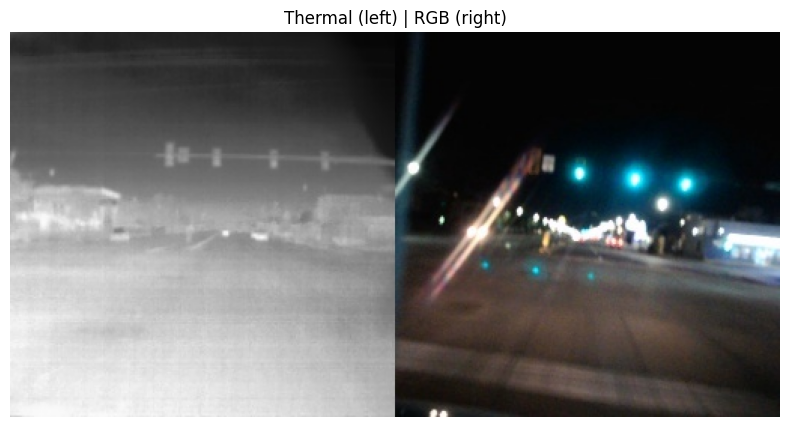

Verification passed.


In [ ]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

image_path = next(
    Path("/content/TRI2I_pix2pix/train").glob("*.jpg")
)

with Image.open(image_path) as img:
    print("Sample:", image_path.name)
    print("Combined image dimensions:", img.size)
    print("Image mode:", img.mode)

    assert img.size == (512, 256), (
        f"Unexpected dimensions: {img.size}"
    )

    plt.figure(figsize=(12, 5))
    plt.imshow(img)
    plt.title("Thermal (left) | RGB (right)")
    plt.axis("off")
    plt.show()

print("Verification passed.")

In [ ]:
import torch
from pathlib import Path

print("=== GPU CHECK ===")
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2),
        "GB"
    )

print("\n=== DATASET CHECK ===")
dataset = Path("/content/TRI2I_pix2pix")

for split in ("train", "val", "test"):
    folder = dataset / split
    print(split, "exists:", folder.exists(),
          "| images:", len(list(folder.glob("*.jpg"))))

print("\n=== CHECKPOINT CHECK ===")
checkpoint_dir = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/"
    "TRI2I_Thermal_RGB_baseline"
)

for name in (
    "latest_net_G.pth",
    "latest_net_D.pth",
    "2_net_G.pth",
    "2_net_D.pth",
):
    path = checkpoint_dir / name
    print(name, "exists:", path.exists())

=== GPU CHECK ===
PyTorch version: 2.11.0+cpu
CUDA available: False

=== DATASET CHECK ===
train exists: False | images: 0
val exists: False | images: 0
test exists: False | images: 0

=== CHECKPOINT CHECK ===
latest_net_G.pth exists: False
latest_net_D.pth exists: False
2_net_G.pth exists: False
2_net_D.pth exists: False


In [ ]:
from google.colab import drive
from pathlib import Path

drive.mount("/content/drive")

mydrive = Path("/content/drive/MyDrive")

print("\n=== PROJECT FOLDER ===")
project = mydrive / "MP1_Thermal_RGB"
print("Project folder exists:", project.exists())

if project.exists():
    for item in sorted(project.iterdir()):
        print(("FOLDER  " if item.is_dir() else "FILE    ") + item.name)

print("\n=== EXPECTED CHECKPOINTS ===")
checkpoint_dir = (
    project / "checkpoints" / "TRI2I_Thermal_RGB_baseline"
)

print("Checkpoint folder:", checkpoint_dir)
print("Folder exists:", checkpoint_dir.exists())

if checkpoint_dir.exists():
    for item in sorted(checkpoint_dir.iterdir()):
        if item.is_file():
            print(f"{item.name} — {item.stat().st_size / (1024**2):.2f} MB")

print("\n=== ORIGINAL DATASET ZIP ===")
zip_path = mydrive / "dataset_1-6-2024.zip"
print("Expected ZIP exists:", zip_path.exists())

print("\n=== SAVED SPLIT MANIFEST ===")
manifest = project / "tri2i_split_seed42.json"
print("Expected manifest exists:", manifest.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

=== PROJECT FOLDER ===
Project folder exists: True
FOLDER  checkpoints
FILE    tri2i_split_seed42.json

=== EXPECTED CHECKPOINTS ===
Checkpoint folder: /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/TRI2I_Thermal_RGB_baseline
Folder exists: True
1_net_D.pth — 10.58 MB
1_net_G.pth — 207.64 MB
2_net_D.pth — 10.58 MB
2_net_G.pth — 207.64 MB
latest_net_D.pth — 10.58 MB
latest_net_G.pth — 207.64 MB
loss_log.txt — 0.07 MB
train_opt.txt — 0.00 MB

=== ORIGINAL DATASET ZIP ===
Expected ZIP exists: True

=== SAVED SPLIT MANIFEST ===
Expected manifest exists: True


In [ ]:
from pathlib import Path
import zipfile

zip_path = Path(
    "/content/drive/MyDrive/dataset_1-6-2024.zip"
)
extract_root = Path("/content/TRI2I_dataset")

assert zip_path.exists(), f"Dataset ZIP not found: {zip_path}"

with zipfile.ZipFile(zip_path, "r") as zf:
    print("ZIP file verified.")
    print("Files in archive:", len(zf.namelist()))

    if not (extract_root / "dataset_1-6-2024").exists():
        print("Extracting dataset. This may take several minutes...")
        zf.extractall(extract_root)
    else:
        print("Extracted dataset folder already exists; skipping extraction.")

source = extract_root / "dataset_1-6-2024"
rgb = source / "class1"
thermal = source / "class2"

print("\n=== VERIFY EXTRACTED DATASET ===")
print("RGB folder exists:", rgb.exists())
print("Thermal folder exists:", thermal.exists())

if rgb.exists() and thermal.exists():
    print("RGB JPG count:", len(list(rgb.glob("*.jpg"))))
    print("Thermal JPG count:", len(list(thermal.glob("*.jpg"))))


ZIP file verified.
Files in archive: 297660
Extracting dataset. This may take several minutes...

=== VERIFY EXTRACTED DATASET ===
RGB folder exists: True
Thermal folder exists: True
RGB JPG count: 148829
Thermal JPG count: 148829


In [ ]:
from pathlib import Path
import json

manifest = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/tri2i_split_seed42.json"
)

source = Path("/content/TRI2I_dataset/dataset_1-6-2024")
rgb_dir = source / "class1"
thermal_dir = source / "class2"

assert manifest.exists(), f"Split manifest missing: {manifest}"
assert rgb_dir.exists() and thermal_dir.exists(), "Dataset folders missing"

with open(manifest, "r") as f:
    split_data = json.load(f)

print("=== SAVED SPLIT VERIFICATION ===")

expected_counts = {
    "train": 119063,
    "val": 14882,
    "test": 14884,
}

for split, expected in expected_counts.items():
    names = split_data[split]
    print(f"{split}: {len(names)} images")
    assert len(names) == expected, (
        f"{split} expected {expected}, found {len(names)}"
    )

    missing_rgb = sum(not (rgb_dir / name).is_file() for name in names)
    missing_thermal = sum(
        not (thermal_dir / name).is_file() for name in names
    )

    print(f"  Missing RGB: {missing_rgb}")
    print(f"  Missing Thermal: {missing_thermal}")

    assert missing_rgb == 0 and missing_thermal == 0, (
        f"Missing source files in {split}"
    )

print("\nSUCCESS: saved split and all referenced source images verified.")

=== SAVED SPLIT VERIFICATION ===
train: 119063 images
  Missing RGB: 0
  Missing Thermal: 0
val: 14882 images
  Missing RGB: 0
  Missing Thermal: 0
test: 14884 images
  Missing RGB: 0
  Missing Thermal: 0

SUCCESS: saved split and all referenced source images verified.


In [ ]:
from pathlib import Path
import shutil
import cv2
import numpy as np

split_root = Path("/content/TRI2I_split")
output_root = Path("/content/TRI2I_pix2pix")

source = Path("/content/TRI2I_dataset/dataset_1-6-2024")
rgb_dir = source / "class1"
thermal_dir = source / "class2"

# Recreate temporary split folders using hard links.
# This avoids duplicating the original JPEG file data.
if split_root.exists():
    shutil.rmtree(split_root)

with open(
    "/content/drive/MyDrive/MP1_Thermal_RGB/tri2i_split_seed42.json",
    "r"
) as f:
    import json
    split_data = json.load(f)

expected_counts = {
    "train": 119063,
    "val": 14882,
    "test": 14884,
}

for split, expected in expected_counts.items():
    names = split_data[split]
    assert len(names) == expected

    for side in ("A", "B"):
        (split_root / split / side).mkdir(parents=True, exist_ok=True)

    for name in names:
        # A = thermal, B = RGB
        (split_root / split / "A" / name).hardlink_to(
            thermal_dir / name
        )
        (split_root / split / "B" / name).hardlink_to(
            rgb_dir / name
        )

    print(f"{split}: {expected} aligned pairs linked")

# Rebuild combined images.
if output_root.exists():
    shutil.rmtree(output_root)

for split, expected in expected_counts.items():
    folder_a = split_root / split / "A"
    folder_b = split_root / split / "B"
    out = output_root / split
    out.mkdir(parents=True)

    names = sorted(p.name for p in folder_a.glob("*.jpg"))
    assert len(names) == expected

    print(f"\nBuilding {split}...", flush=True)

    for i, name in enumerate(names, start=1):
        a = cv2.imread(str(folder_a / name), cv2.IMREAD_COLOR)
        b = cv2.imread(str(folder_b / name), cv2.IMREAD_COLOR)

        if a is None or b is None:
            raise RuntimeError(f"Could not read image pair: {split}/{name}")

        if a.shape != b.shape:
            raise RuntimeError(f"Image size mismatch: {split}/{name}")

        combined = np.concatenate([a, b], axis=1)

        if not cv2.imwrite(str(out / name), combined):
            raise RuntimeError(f"Failed to save: {split}/{name}")

        if i % 10000 == 0:
            print(f"  {i}/{expected}", flush=True)

    actual = len(list(out.glob("*.jpg")))
    assert actual == expected, (
        f"{split}: expected {expected}, found {actual}"
    )
    print(f"{split} verified: {actual} combined images")

print("\nSUCCESS: combined Pix2Pix dataset rebuilt and verified.")

train: 119063 aligned pairs linked
val: 14882 aligned pairs linked
test: 14884 aligned pairs linked

Building train...
  10000/119063
  20000/119063
  30000/119063
  40000/119063
  50000/119063
  60000/119063
  70000/119063
  80000/119063
  90000/119063
  100000/119063
  110000/119063
train verified: 119063 combined images

Building val...
  10000/14882
val verified: 14882 combined images

Building test...
  10000/14884
test verified: 14884 combined images

SUCCESS: combined Pix2Pix dataset rebuilt and verified.


In [ ]:

from pathlib import Path
import subprocess

repo = Path("/content/pytorch-CycleGAN-and-pix2pix")

if not (repo / "train.py").exists():
    if repo.exists():
        print("Repository folder exists but train.py is missing.")
        print("Removing the incomplete repository folder...")
        import shutil
        shutil.rmtree(repo)

    print("Cloning the official Pix2Pix repository...")
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix.git",
            str(repo)
        ],
        check=True
    )

assert (repo / "train.py").exists(), "Repository setup failed."

print("\nSUCCESS: Pix2Pix repository is ready.")
print("Training script:", repo / "train.py")


Cloning the official Pix2Pix repository...

SUCCESS: Pix2Pix repository is ready.
Training script: /content/pytorch-CycleGAN-and-pix2pix/train.py


In [ ]:

from pathlib import Path
import subprocess
import sys

repo = Path("/content/pytorch-CycleGAN-and-pix2pix")
dataset = Path("/content/TRI2I_pix2pix")

# Install the dependency required by Pix2Pix.
try:
    import dominate
except ImportError:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q", "dominate"
    ])

# Verify the expected image counts.
expected = {
    "train": 119063,
    "val": 14882,
    "test": 14884
}

for split, count in expected.items():
    folder = dataset / split
    actual = len(list(folder.glob("*.jpg")))
    print(f"{split}: {actual} images (expected {count})")
    assert actual == count, f"{split} image count mismatch"

# Verify the official Pix2Pix dataset loader.
assert (repo / "data" / "aligned_dataset.py").exists(), \
    "Aligned dataset loader is missing."

print("\nRepository and dataset checks passed.")
print("Next: test whether Pix2Pix can load a batch.")


train: 119063 images (expected 119063)
val: 14882 images (expected 14882)
test: 14884 images (expected 14884)

Repository and dataset checks passed.
Next: test whether Pix2Pix can load a batch.


In [ ]:

from pathlib import Path
import os
import sys

repo = Path("/content/pytorch-CycleGAN-and-pix2pix")
dataset_path = Path("/content/TRI2I_pix2pix")

assert (repo / "train.py").exists(), "Pix2Pix repository is missing."
assert dataset_path.exists(), "Dataset folder is missing."

os.chdir(repo)

sys.argv = [
    "dataloader_test",
    "--dataroot", str(dataset_path),
    "--name", "tri2i_dataloader_check",
    "--model", "pix2pix",
    "--direction", "AtoB",
    "--dataset_mode", "aligned",
    "--batch_size", "4",
    "--num_threads", "0",
    "--display_winsize", "256",
    "--preprocess", "resize_and_crop",
    "--load_size", "286",
    "--crop_size", "256"
]

from options.train_options import TrainOptions
from data import create_dataset

opt = TrainOptions().parse()
data_loader = create_dataset(opt)

print("\nNumber of batches:", len(data_loader))

batch = next(iter(data_loader))

print("Thermal batch shape (A):", tuple(batch["A"].shape))
print("RGB batch shape (B):", tuple(batch["B"].shape))
print("First thermal path:", batch["A_paths"][0])
print("First RGB path:", batch["B_paths"][0])

assert tuple(batch["A"].shape) == (4, 3, 256, 256)
assert tuple(batch["B"].shape) == (4, 3, 256, 256)

print("\nSUCCESS: Four image pairs loaded with the expected shapes.")
print("No model training was performed.")


----------------- Options ---------------
               batch_size: 4                             	[default: 1]
                    beta1: 0.5                           
          checkpoints_dir: ./checkpoints                 
           continue_train: False                         
                crop_size: 256                           
                 dataroot: /content/TRI2I_pix2pix        	[default: None]
             dataset_mode: aligned                       
                direction: AtoB                          
             display_freq: 400                           
          display_winsize: 256                           
                    epoch: latest                        
              epoch_count: 1                             
                 gan_mode: vanilla                       
                init_gain: 0.02                          
                init_type: normal                        
                 input_nc: 3                             
 

In [ ]:

from pathlib import Path
import torch

checkpoint_dir = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/"
    "TRI2I_Thermal_RGB_baseline"
)

print("Checkpoint directory:", checkpoint_dir)
assert checkpoint_dir.exists(), "Checkpoint directory not found. Stop here."

required_files = [
    "latest_net_G.pth",
    "latest_net_D.pth",
    "1_net_G.pth",
    "1_net_D.pth",
    "2_net_G.pth",
    "2_net_D.pth",
    "loss_log.txt",
    "train_opt.txt",
]

for filename in required_files:
    path = checkpoint_dir / filename
    if path.exists():
        print(f"FOUND  {filename}  ({path.stat().st_size / (1024**2):.2f} MB)")
    else:
        print(f"MISSING {filename}")

assert (checkpoint_dir / "latest_net_G.pth").exists()
assert (checkpoint_dir / "latest_net_D.pth").exists()
assert (checkpoint_dir / "loss_log.txt").exists()
assert (checkpoint_dir / "train_opt.txt").exists()

print("\n--- Last training log entries ---")
log_path = checkpoint_dir / "loss_log.txt"
print("\n".join(log_path.read_text(errors="replace").splitlines()[-5:]))

print("\nCheckpoint files verified. No model weights were modified.")


Checkpoint directory: /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/TRI2I_Thermal_RGB_baseline
FOUND  latest_net_G.pth  (207.64 MB)
FOUND  latest_net_D.pth  (10.58 MB)
FOUND  1_net_G.pth  (207.64 MB)
FOUND  1_net_D.pth  (10.58 MB)
FOUND  2_net_G.pth  (207.64 MB)
FOUND  2_net_D.pth  (10.58 MB)
FOUND  loss_log.txt  (0.07 MB)
FOUND  train_opt.txt  (0.00 MB)

--- Last training log entries ---

[Rank 0] (epoch: 3, iters: 66872, time: 0.104, data: 0.004) , G_GAN: 3.381, G_L1: 19.298, D_real: 0.025, D_fake: 0.113

[Rank 0] (epoch: 3, iters: 67372, time: 0.080, data: 0.004) , G_GAN: 2.023, G_L1: 17.282, D_real: 1.383, D_fake: 0.048


Checkpoint files verified. No model weights were modified.


In [ ]:

from pathlib import Path

repo = Path("/content/pytorch-CycleGAN-and-pix2pix")
checkpoint_dir = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/"
    "TRI2I_Thermal_RGB_baseline"
)

# 1. Show the saved training configuration.
print("=" * 60)
print("SAVED TRAINING CONFIGURATION")
print("=" * 60)

opt_file = checkpoint_dir / "train_opt.txt"
print(opt_file.read_text(errors="replace"))

# 2. Inspect the training loop and checkpoint-saving logic.
print("\n" + "=" * 60)
print("TRAINING LOOP: SAVE FREQUENCY AND EPOCHS")
print("=" * 60)

train_file = (repo / "train.py").read_text(errors="replace").splitlines()

for i, line in enumerate(train_file):
    if any(term in line for term in [
        "save_latest_freq",
        "save_epoch_freq",
        "epoch_count",
        "n_epochs_decay",
        "save_networks",
        "update_learning_rate",
        "total_iters"
    ]):
        start = max(0, i - 2)
        end = min(len(train_file), i + 3)
        print(f"\n--- train.py lines {start + 1}-{end} ---")
        for j in range(start, end):
            print(f"{j + 1}: {train_file[j]}")

# 3. Inspect checkpoint loading and scheduler setup.
print("\n" + "=" * 60)
print("MODEL LOADING AND LEARNING-RATE SCHEDULER")
print("=" * 60)

for filename in ["models/base_model.py", "models/pix2pix_model.py"]:
    path = repo / filename
    print(f"\n--- {filename} ---")
    lines = path.read_text(errors="replace").splitlines()

    terms = [
        "def setup",
        "def load_networks",
        "def update_learning_rate",
        "def get_scheduler",
        "def optimize_parameters",
        "def __init__",
        "continue_train",
        "epoch_count",
        "self.optimizers",
        "self.schedulers"
    ]

    shown = set()
    for i, line in enumerate(lines):
        if any(term in line for term in terms):
            start = max(0, i - 1)
            end = min(len(lines), i + 9)
            if any(k in shown for k in range(start, end)):
                continue
            shown.update(range(start, end))
            print(f"\nLines {start + 1}-{end}:")
            for j in range(start, end):
                print(f"{j + 1}: {lines[j]}")

# 4. Print checkpoint timestamps.
print("\n" + "=" * 60)
print("CHECKPOINT MODIFICATION TIMES")
print("=" * 60)

for name in [
    "1_net_G.pth", "2_net_G.pth",
    "latest_net_G.pth", "latest_net_D.pth"
]:
    path = checkpoint_dir / name
    print(name, "exists:", path.exists())
    if path.exists():
        print("  modified:", path.stat().st_mtime)

print("\nInspection complete. No training was performed.")


SAVED TRAINING CONFIGURATION
----------------- Options ---------------
               batch_size: 4                             	[default: 1]
                    beta1: 0.5                           
          checkpoints_dir: /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints	[default: ./checkpoints]
           continue_train: False                         
                crop_size: 256                           
                 dataroot: /content/TRI2I_pix2pix        	[default: None]
             dataset_mode: aligned                       
                direction: AtoB                          
             display_freq: 1000                          	[default: 400]
          display_winsize: 256                           
                    epoch: latest                        
              epoch_count: 1                             
                 gan_mode: vanilla                       
                init_gain: 0.02                          
                init_type: n

In [ ]:

from pathlib import Path

repo = Path("/content/pytorch-CycleGAN-and-pix2pix")

files_to_inspect = [
    ("models/networks.py", ["def get_scheduler"]),
    ("models/base_model.py", ["def setup", "def update_learning_rate"]),
    ("options/train_options.py", ["epoch_count", "continue_train"]),
]

for filename, markers in files_to_inspect:
    path = repo / filename
    print("\n" + "=" * 65)
    print(filename)
    print("=" * 65)

    lines = path.read_text(errors="replace").splitlines()

    for marker in markers:
        matches = [
            i for i, line in enumerate(lines)
            if marker in line
        ]

        for i in matches:
            start = max(0, i - 2)
            end = min(len(lines), i + 24)

            print(f"\n--- Lines {start + 1}-{end} ---")
            for j in range(start, end):
                print(f"{j + 1}: {lines[j]}")

print("\nInspection complete. No training or checkpoint changes occurred.")



models/networks.py

--- Lines 41-66 ---
41: 
42: 
43: def get_scheduler(optimizer, opt):
44:     """Return a learning rate scheduler
45: 
46:     Parameters:
47:         optimizer          -- the optimizer of the network
48:         opt (option class) -- stores all the experiment flags; needs to be a subclass of BaseOptions．
49:                               opt.lr_policy is the name of learning rate policy: linear | step | plateau | cosine
50: 
51:     For 'linear', we keep the same learning rate for the first <opt.n_epochs> epochs
52:     and linearly decay the rate to zero over the next <opt.n_epochs_decay> epochs.
53:     For other schedulers (step, plateau, and cosine), we use the default PyTorch schedulers.
54:     See https://pytorch.org/docs/stable/optim.html for more details.
55:     """
56:     if opt.lr_policy == "linear":
57: 
58:         def lambda_rule(epoch):
59:             lr_l = 1.0 - max(0, epoch + opt.epoch_count - opt.n_epochs) / float(opt.n_epochs_decay + 1)
60: 

In [ ]:

from pathlib import Path
from datetime import datetime
import shutil

source = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/"
    "TRI2I_Thermal_RGB_baseline"
)

assert source.exists(), "Original checkpoint directory is missing."

backup_root = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints"
)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
backup = backup_root / f"TRI2I_Thermal_RGB_backup_{timestamp}"

backup.mkdir(parents=True, exist_ok=False)

files = [
    p for p in source.iterdir()
    if p.is_file()
]

for file in files:
    shutil.copy2(file, backup / file.name)

# Verify every copied file.
for file in files:
    copied = backup / file.name
    assert copied.exists(), f"Backup missing: {file.name}"
    assert copied.stat().st_size == file.stat().st_size, (
        f"Backup size mismatch: {file.name}"
    )

print("BACKUP SUCCESSFUL")
print("Backup location:", backup)
print("Files copied:", len(files))
print("Original checkpoints remain unchanged.")


BACKUP SUCCESSFUL
Backup location: /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/TRI2I_Thermal_RGB_backup_20261011_194608
Files copied: 8
Original checkpoints remain unchanged.


In [ ]:

from pathlib import Path
import shutil
import torch

root = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints"
)

source = root / "TRI2I_Thermal_RGB_baseline"
experiment = root / "TRI2I_Thermal_RGB_resume_v1"

assert (source / "latest_net_G.pth").exists()
assert (source / "latest_net_D.pth").exists()

if experiment.exists():
    raise FileExistsError(
        f"{experiment} already exists. Stop so we do not overwrite it."
    )

experiment.mkdir(parents=True)

for filename in ["latest_net_G.pth", "latest_net_D.pth"]:
    shutil.copy2(source / filename, experiment / filename)

    original_size = (source / filename).stat().st_size
    copied_size = (experiment / filename).stat().st_size

    assert original_size == copied_size, f"Copy mismatch: {filename}"

    # Check that each copied checkpoint can be loaded.
    state = torch.load(
        experiment / filename,
        map_location="cpu",
        weights_only=True
    )
    assert isinstance(state, dict), f"Unexpected checkpoint: {filename}"
    print(f"Verified: {filename} ({copied_size / (1024**2):.2f} MB)")

print("\nResume experiment prepared.")
print("New folder:", experiment)
print("Original baseline was not modified.")
print("No training has started.")


Verified: latest_net_G.pth (207.64 MB)
Verified: latest_net_D.pth (10.58 MB)

Resume experiment prepared.
New folder: /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/TRI2I_Thermal_RGB_resume_v1
Original baseline was not modified.
No training has started.


In [ ]:

from pathlib import Path
import os
import sys
import torch

repo = Path("/content/pytorch-CycleGAN-and-pix2pix")
experiment_root = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints"
)
experiment_name = "TRI2I_Thermal_RGB_resume_v1"
dataset = Path("/content/TRI2I_pix2pix")

experiment = experiment_root / experiment_name

assert (repo / "train.py").exists(), "Pix2Pix repository is missing."
assert (experiment / "latest_net_G.pth").exists(), "Generator checkpoint missing."
assert (experiment / "latest_net_D.pth").exists(), "Discriminator checkpoint missing."
assert dataset.exists(), "Dataset folder is missing."
assert torch.cuda.is_available(), "CUDA is unavailable. Stop before loading."

os.chdir(repo)

sys.argv = [
    "resume_preflight",
    "--dataroot", str(dataset),
    "--name", experiment_name,
    "--checkpoints_dir", str(experiment_root),
    "--model", "pix2pix",
    "--dataset_mode", "aligned",
    "--direction", "AtoB",
    "--batch_size", "4",
    "--continue_train",
    "--epoch", "latest",
    "--epoch_count", "3",
    "--n_epochs", "10",
    "--n_epochs_decay", "10",
    "--lr", "0.0002",
    "--beta1", "0.5",
    "--lambda_L1", "100",
    "--gan_mode", "vanilla",
    "--preprocess", "resize_and_crop",
    "--load_size", "256",
    "--crop_size", "256",
    "--num_threads", "0"
]

from options.train_options import TrainOptions
from models import create_model

opt = TrainOptions().parse()

# Fix: this repository expects an opt.device attribute.
opt.device = torch.device("cuda:0")

print("\nAssigned device:", opt.device)
print("GPU:", torch.cuda.get_device_name(0))

model = create_model(opt)
model.setup(opt)

print("\nSUCCESS: Pix2Pix model setup and checkpoint loading completed.")
print("Experiment:", opt.name)
print("Checkpoint folder:", model.save_dir)
print("No training iterations were performed.")


----------------- Options ---------------
               batch_size: 4                             	[default: 1]
                    beta1: 0.5                           
          checkpoints_dir: /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints	[default: ./checkpoints]
           continue_train: True                          	[default: False]
                crop_size: 256                           
                 dataroot: /content/TRI2I_pix2pix        	[default: None]
             dataset_mode: aligned                       
                direction: AtoB                          
             display_freq: 400                           
          display_winsize: 256                           
                    epoch: latest                        
              epoch_count: 3                             	[default: 1]
                 gan_mode: vanilla                       
                init_gain: 0.02                          
                init_type: normal         

In [ ]:

from pathlib import Path
import os
import sys
import runpy
import torch

repo = Path("/content/pytorch-CycleGAN-and-pix2pix")
dataset = Path("/content/TRI2I_pix2pix")
checkpoint_root = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints"
)
experiment_name = "TRI2I_Thermal_RGB_resume_v1"
experiment = checkpoint_root / experiment_name

# Safety checks before training.
assert (repo / "train.py").exists(), "Pix2Pix repository is missing."
assert dataset.exists(), "Training dataset is missing."
assert (experiment / "latest_net_G.pth").exists(), "Generator checkpoint missing."
assert (experiment / "latest_net_D.pth").exists(), "Discriminator checkpoint missing."
assert torch.cuda.is_available(), "CUDA is unavailable. Training cancelled."

print("GPU:", torch.cuda.get_device_name(0))
print("Experiment:", experiment)
print("Resuming from existing generator and discriminator weights.")
print("Original baseline and backup will not be used as output folders.")

os.chdir(repo)

# This repository's options parser does not create opt.device.
# Add it when options are parsed so train.py can initialize the model.
import options.base_options as base_options

_original_parse = base_options.BaseOptions.parse

def _parse_with_device(self, *args, **kwargs):
    opt = _original_parse(self, *args, **kwargs)
    opt.device = torch.device(
        "cuda:0" if torch.cuda.is_available() else "cpu"
    )
    return opt

base_options.BaseOptions.parse = _parse_with_device

# Preserve the established experiment settings.
sys.argv = [
    "train.py",
    "--dataroot", str(dataset),
    "--name", experiment_name,
    "--checkpoints_dir", str(checkpoint_root),
    "--model", "pix2pix",
    "--dataset_mode", "aligned",
    "--direction", "AtoB",
    "--continue_train",
    "--epoch", "latest",
    "--epoch_count", "3",
    "--n_epochs", "10",
    "--n_epochs_decay", "10",
    "--batch_size", "4",
    "--lr", "0.0002",
    "--beta1", "0.5",
    "--lambda_L1", "100",
    "--gan_mode", "vanilla",
    "--preprocess", "resize_and_crop",
    "--load_size", "256",
    "--crop_size", "256",
    "--num_threads", "2",
    "--display_freq", "1000",
    "--print_freq", "500",
    "--save_latest_freq", "5000",
    "--save_epoch_freq", "1"
]

print("\nStarting resumed training. Monitor the loss output below.\n")

runpy.run_path(str(repo / "train.py"), run_name="__main__")


GPU: Tesla T4
Experiment: /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/TRI2I_Thermal_RGB_resume_v1
Resuming from existing generator and discriminator weights.
Original baseline and backup will not be used as output folders.

Starting resumed training. Monitor the loss output below.

----------------- Options ---------------
               batch_size: 4                             	[default: 1]
                    beta1: 0.5                           
          checkpoints_dir: /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints	[default: ./checkpoints]
           continue_train: True                          	[default: False]
                crop_size: 256                           
                 dataroot: /content/TRI2I_pix2pix        	[default: None]
             dataset_mode: aligned                       
                direction: AtoB                          
             display_freq: 1000                          	[default: 400]
          display_winsize: 256          

/content/pytorch-CycleGAN-and-pix2pix/models/base_model.py:182: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  errors_ret[name] = float(getattr(self, "loss_" + name))  # float(...) works for both scalar tensor and float number


[Rank 0] (epoch: 3, iters: 500, time: 0.070, data: 0.332) , G_GAN: 3.666, G_L1: 21.567, D_real: 0.019, D_fake: 0.762

[Rank 0] (epoch: 3, iters: 1000, time: 0.101, data: 0.003) , G_GAN: 2.403, G_L1: 18.993, D_real: 0.501, D_fake: 0.047

[Rank 0] (epoch: 3, iters: 1500, time: 0.074, data: 0.003) , G_GAN: 2.025, G_L1: 19.476, D_real: 1.000, D_fake: 0.028

[Rank 0] (epoch: 3, iters: 2000, time: 0.097, data: 0.003) , G_GAN: 2.153, G_L1: 19.778, D_real: 0.556, D_fake: 0.126

[Rank 0] (epoch: 3, iters: 2500, time: 0.072, data: 0.003) , G_GAN: 3.484, G_L1: 16.538, D_real: 0.328, D_fake: 0.039

[Rank 0] (epoch: 3, iters: 3000, time: 0.110, data: 0.003) , G_GAN: 2.552, G_L1: 18.691, D_real: 0.244, D_fake: 0.232

[Rank 0] (epoch: 3, iters: 3500, time: 0.073, data: 0.004) , G_GAN: 2.777, G_L1: 17.716, D_real: 0.102, D_fake: 0.122

[Rank 0] (epoch: 3, iters: 4000, time: 0.096, data: 0.003) , G_GAN: 1.477, G_L1: 19.304, D_real: 0.266, D_fake: 0.318

[Rank 0] (epoch: 3, iters: 4500, time: 0.070, dat

In [ ]:

from pathlib import Path
from datetime import datetime
import os

from google.colab import drive
drive.mount("/content/drive")

root = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints"
)

folders = [
    "TRI2I_Thermal_RGB_baseline",
    "TRI2I_Thermal_RGB_resume_v1",
    "TRI2I_Thermal_RGB_backup_20261011_194608",
]

for folder_name in folders:
    folder = root / folder_name
    print("\n" + "=" * 65)
    print(folder_name)
    print("=" * 65)

    if not folder.exists():
        print("FOLDER NOT FOUND")
        continue

    for filename in [
        "latest_net_G.pth",
        "latest_net_D.pth",
        "1_net_G.pth",
        "1_net_D.pth",
        "2_net_G.pth",
        "2_net_D.pth",
        "3_net_G.pth",
        "3_net_D.pth",
        "loss_log.txt",
        "train_opt.txt",
    ]:
        path = folder / filename
        if path.exists():
            modified = datetime.fromtimestamp(
                path.stat().st_mtime
            ).strftime("%Y-%m-%d %H:%M:%S")

            size_mb = path.stat().st_size / (1024 ** 2)
            print(
                f"FOUND  {filename:<20} "
                f"{size_mb:>8.2f} MB  modified {modified}"
            )

    log_path = folder / "loss_log.txt"
    if log_path.exists():
        print("\nLast 8 training log lines:")
        lines = log_path.read_text(errors="replace").splitlines()
        print("\n".join(lines[-8:]))

print("\nCheckpoint inspection finished. No files were changed.")


In [ ]:

from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

zip_path = Path(
    "/content/drive/MyDrive/dataset_1-6-2024.zip"
)

dataset_root = Path(
    "/content/TRI2I_dataset/dataset_1-6-2024"
)

print("\n--- Dataset source check ---")
print("ZIP exists:", zip_path.exists())

if zip_path.exists():
    print("ZIP size:", round(zip_path.stat().st_size / (1024**3), 2), "GB")

print("\n--- Extracted dataset check ---")
print("Extracted dataset exists:", dataset_root.exists())

if dataset_root.exists():
    for folder_name in ["class1", "class2"]:
        folder = dataset_root / folder_name
        print(f"\n{folder_name} exists:", folder.exists())

        if folder.exists():
            count = sum(
                1 for p in folder.iterdir()
                if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
            )
            print("Image count:", count)


Mounted at /content/drive

--- Dataset source check ---
ZIP exists: True
ZIP size: 5.44 GB

--- Extracted dataset check ---
Extracted dataset exists: False


In [ ]:

from pathlib import Path
import zipfile

zip_path = Path("/content/drive/MyDrive/dataset_1-6-2024.zip")
extract_root = Path("/content/TRI2I_dataset")

assert zip_path.exists(), f"Dataset ZIP not found: {zip_path}"

print("Checking ZIP integrity...")
with zipfile.ZipFile(zip_path, "r") as z:
    bad_file = z.testzip()
    assert bad_file is None, f"Corrupted ZIP member: {bad_file}"

    print("ZIP integrity check passed.")
    print("Extracting dataset. This may take several minutes...")

    z.extractall(extract_root)

print("\nExtraction finished.")

# Find the actual class folders without assuming ZIP folder structure.
class1_folders = list(extract_root.rglob("class1"))
class2_folders = list(extract_root.rglob("class2"))

print("class1 folders found:", class1_folders[:3])
print("class2 folders found:", class2_folders[:3])

assert class1_folders, "Could not find class1 (expected RGB) folder."
assert class2_folders, "Could not find class2 (expected Thermal) folder."

print("\nSUCCESS: Dataset extracted and class folders found.")


Checking ZIP integrity...
ZIP integrity check passed.
Extracting dataset. This may take several minutes...

Extraction finished.
class1 folders found: [PosixPath('/content/TRI2I_dataset/dataset_1-6-2024/class1')]
class2 folders found: [PosixPath('/content/TRI2I_dataset/dataset_1-6-2024/class2')]

SUCCESS: Dataset extracted and class folders found.


In [ ]:

from pathlib import Path
import os

checkpoint_dir = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/"
    "TRI2I_Thermal_RGB_resume_v1"
)

print("Checkpoint folder exists:", checkpoint_dir.exists())

if checkpoint_dir.exists():
    print("\nFiles found:")
    for file in sorted(checkpoint_dir.iterdir()):
        if file.is_file():
            print(
                f"{file.name:30s} | "
                f"{file.stat().st_size / (1024**2):.2f} MB"
            )
else:
    print("Resume checkpoint folder was not found.")


Checkpoint folder exists: True

Files found:
latest_net_D.pth               | 10.58 MB
latest_net_G.pth               | 207.64 MB
loss_log.txt                   | 0.02 MB
train_opt.txt                  | 0.00 MB


In [ ]:

from pathlib import Path

checkpoint_dir = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/"
    "TRI2I_Thermal_RGB_resume_v1"
)

log_file = checkpoint_dir / "loss_log.txt"
options_file = checkpoint_dir / "train_opt.txt"

print("========== LAST 40 TRAINING LOG LINES ==========")
if log_file.exists():
    lines = log_file.read_text(errors="replace").splitlines()
    print("\n".join(lines[-40:]))
else:
    print("loss_log.txt not found")

print("\n========== SAVED TRAINING CONFIGURATION ==========")
if options_file.exists():
    print(options_file.read_text(errors="replace"))
else:
    print("train_opt.txt not found")


========== LAST 40 TRAINING LOG LINES ==========
[Rank 0] (epoch: 3, iters: 64500, time: 0.072, data: 0.005) , G_GAN: 4.463, G_L1: 18.022, D_real: 0.019, D_fake: 0.148

[Rank 0] (epoch: 3, iters: 65000, time: 0.096, data: 0.003) , G_GAN: 4.543, G_L1: 18.617, D_real: 0.286, D_fake: 0.047

[Rank 0] (epoch: 3, iters: 65500, time: 0.064, data: 0.004) , G_GAN: 3.530, G_L1: 13.725, D_real: 0.218, D_fake: 0.045

[Rank 0] (epoch: 3, iters: 66000, time: 0.099, data: 0.007) , G_GAN: 4.154, G_L1: 16.696, D_real: 0.284, D_fake: 0.016

[Rank 0] (epoch: 3, iters: 66500, time: 0.070, data: 0.003) , G_GAN: 4.057, G_L1: 15.177, D_real: 0.217, D_fake: 0.016

[Rank 0] (epoch: 3, iters: 67000, time: 0.098, data: 0.005) , G_GAN: 3.509, G_L1: 21.181, D_real: 0.022, D_fake: 0.115

[Rank 0] (epoch: 3, iters: 67500, time: 0.072, data: 0.003) , G_GAN: 3.990, G_L1: 20.360, D_real: 0.198, D_fake: 0.049

[Rank 0] (epoch: 3, iters: 68000, time: 0.094, data: 0.003) , G_GAN: 3.528, G_L1: 17.757, D_real: 0.076, D_fake

In [ ]:

from pathlib import Path
from datetime import datetime

folder = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/"
    "TRI2I_Thermal_RGB_resume_v1"
)

print("========== FILE DETAILS ==========")
for p in sorted(folder.iterdir()):
    if p.is_file():
        modified = datetime.fromtimestamp(p.stat().st_mtime)
        print(f"{p.name} | {p.stat().st_size / (1024**2):.2f} MB | Modified: {modified}")

print("\n========== TRAINING LOG ==========")
log = folder / "loss_log.txt"

if log.exists():
    content = log.read_text(errors="replace").splitlines()
    print("Total log lines:", len(content))
    if content:
        print("\n".join(content[-25:]))
    else:
        print("The training log is empty.")
else:
    print("Training log not found.")

print("\n========== NUMBERED CHECKPOINTS ==========")
for p in sorted(folder.glob("*_net_*.pth")):
    print(p.name)


========== FILE DETAILS ==========
latest_net_D.pth | 10.58 MB | Modified: 2026-10-11 20:56:47
latest_net_G.pth | 207.64 MB | Modified: 2026-10-11 20:56:43
loss_log.txt | 0.02 MB | Modified: 2026-10-11 20:58:58
train_opt.txt | 0.00 MB | Modified: 2026-10-11 20:10:25

========== TRAINING LOG ==========
Total log lines: 297

[Rank 0] (epoch: 3, iters: 68500, time: 0.072, data: 0.003) , G_GAN: 3.700, G_L1: 18.770, D_real: 0.049, D_fake: 0.183

[Rank 0] (epoch: 3, iters: 69000, time: 0.103, data: 0.003) , G_GAN: 3.891, G_L1: 15.293, D_real: 0.011, D_fake: 0.354

[Rank 0] (epoch: 3, iters: 69500, time: 0.073, data: 0.005) , G_GAN: 4.024, G_L1: 12.693, D_real: 0.002, D_fake: 0.587

[Rank 0] (epoch: 3, iters: 70000, time: 0.096, data: 0.003) , G_GAN: 5.609, G_L1: 19.391, D_real: 0.083, D_fake: 0.029

[Rank 0] (epoch: 3, iters: 70500, time: 0.067, data: 0.004) , G_GAN: 3.254, G_L1: 14.803, D_real: 1.060, D_fake: 0.017

[Rank 0] (epoch: 3, iters: 71000, time: 0.098, data: 0.006) , G_GAN: 4.278,

In [ ]:

from pathlib import Path

folder = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/"
    "TRI2I_Thermal_RGB_resume_v1"
)

log_path = folder / "loss_log.txt"
lines = log_path.read_text(errors="replace").splitlines()

print("========== EPOCH SUMMARY ==========")
for line in lines:
    if "End of epoch" in line or "saving the model" in line.lower():
        print(line)

print("\n========== FINAL 15 LOG LINES ==========")
print("\n".join(lines[-15:]))

print("\n========== CHECKPOINT FILES ==========")
for name in ["latest_net_G.pth", "latest_net_D.pth"]:
    path = folder / name
    print(f"{name}: exists={path.exists()}, bytes={path.stat().st_size if path.exists() else 0}")


========== EPOCH SUMMARY ==========

========== FINAL 15 LOG LINES ==========

[Rank 0] (epoch: 3, iters: 71000, time: 0.098, data: 0.006) , G_GAN: 4.278, G_L1: 15.351, D_real: 0.029, D_fake: 0.056

[Rank 0] (epoch: 3, iters: 71500, time: 0.071, data: 0.003) , G_GAN: 3.618, G_L1: 18.062, D_real: 0.067, D_fake: 0.365

[Rank 0] (epoch: 3, iters: 72000, time: 0.094, data: 0.007) , G_GAN: 3.251, G_L1: 17.961, D_real: 0.090, D_fake: 0.259

[Rank 0] (epoch: 3, iters: 72500, time: 0.073, data: 0.003) , G_GAN: 3.429, G_L1: 15.734, D_real: 0.130, D_fake: 0.129

[Rank 0] (epoch: 3, iters: 73000, time: 0.103, data: 0.003) , G_GAN: 3.764, G_L1: 19.714, D_real: 0.614, D_fake: 0.103

[Rank 0] (epoch: 3, iters: 73500, time: 0.072, data: 0.005) , G_GAN: 4.254, G_L1: 16.104, D_real: 0.006, D_fake: 0.056

[Rank 0] (epoch: 3, iters: 74000, time: 0.098, data: 0.003) , G_GAN: 5.649, G_L1: 22.676, D_real: 0.003, D_fake: 0.054


========== CHECKPOINT FILES ==========
latest_net_G.pth: exists=True, bytes=2177

In [ ]:

from pathlib import Path
import torch

checkpoint_path = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/"
    "TRI2I_Thermal_RGB_resume_v1/latest_net_G.pth"
)

assert checkpoint_path.exists(), "Generator checkpoint is missing."

print("Checkpoint size:", round(checkpoint_path.stat().st_size / (1024**2), 2), "MB")
print("PyTorch version:", torch.__version__)

try:
    state = torch.load(
        checkpoint_path,
        map_location="cpu",
        weights_only=True
    )

    print("\nCheckpoint loaded successfully.")
    print("Object type:", type(state).__name__)

    if isinstance(state, dict):
        print("Number of state entries:", len(state))
        print("\nSample parameter entries:")

        for i, (key, value) in enumerate(state.items()):
            shape = tuple(value.shape) if hasattr(value, "shape") else type(value).__name__
            print(f"{key}: {shape}")
            if i >= 4:
                break
    else:
        print("Unexpected checkpoint format.")

except Exception as e:
    print("Checkpoint loading failed:")
    print(type(e).__name__, str(e))


Checkpoint size: 207.64 MB
PyTorch version: 2.11.0+cu130

Checkpoint loaded successfully.
Object type: OrderedDict
Number of state entries: 82

Sample parameter entries:
model.model.0.weight: (64, 3, 4, 4)
model.model.1.model.1.weight: (128, 64, 4, 4)
model.model.1.model.2.weight: (128,)
model.model.1.model.2.bias: (128,)
model.model.1.model.2.running_mean: (128,)


In [ ]:

from pathlib import Path

paths = {
    "Combined test dataset": Path("/content/TRI2I_pix2pix/test"),
    "Thermal test images": Path("/content/TRI2I_split/test/A"),
    "RGB test images": Path("/content/TRI2I_split/test/B"),
    "Original extracted dataset": Path(
        "/content/TRI2I_dataset/dataset_1-6-2024"
    ),
    "Saved split manifest": Path(
        "/content/drive/MyDrive/MP1_Thermal_RGB/tri2i_split_seed42.json"
    ),
}

for name, path in paths.items():
    print(f"{name}: {'EXISTS' if path.exists() else 'MISSING'}")
    if path.is_dir():
        print(f"  Files directly inside: {sum(1 for p in path.iterdir() if p.is_file())}")


Combined test dataset: MISSING
Thermal test images: MISSING
RGB test images: MISSING
Original extracted dataset: EXISTS
  Files directly inside: 0
Saved split manifest: EXISTS


In [ ]:

from pathlib import Path

root = Path("/content/TRI2I_dataset")

print("Dataset root:", root)
print("Root exists:", root.exists())

print("\nTop-level entries:")
for p in list(root.iterdir())[:30]:
    print(("DIR " if p.is_dir() else "FILE"), p.name)

print("\nSearching for class1 and class2 directories...")
for folder_name in ("class1", "class2"):
    matches = list(root.rglob(folder_name))
    print(f"\n{folder_name}: {len(matches)} folder(s)")
    for folder in matches[:10]:
        image_count = sum(
            1 for p in folder.iterdir()
            if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
        )
        print(f"  {folder} | direct image files: {image_count}")


Dataset root: /content/TRI2I_dataset
Root exists: True

Top-level entries:
DIR  dataset_1-6-2024

Searching for class1 and class2 directories...

class1: 1 folder(s)
  /content/TRI2I_dataset/dataset_1-6-2024/class1 | direct image files: 148829

class2: 1 folder(s)
  /content/TRI2I_dataset/dataset_1-6-2024/class2 | direct image files: 148829


In [ ]:

import json
from pathlib import Path

manifest_path = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/tri2i_split_seed42.json"
)

assert manifest_path.exists(), "Saved split manifest is missing."

with manifest_path.open("r") as f:
    manifest = json.load(f)

print("Manifest type:", type(manifest).__name__)

if isinstance(manifest, dict):
    print("Top-level keys:", list(manifest.keys()))

    for key, value in manifest.items():
        if isinstance(value, list):
            print(f"{key}: {len(value)} entries")
            print("  First 3:", value[:3])
        elif isinstance(value, dict):
            print(f"{key}: dictionary with keys {list(value.keys())[:10]}")
        else:
            print(f"{key}: {value}")
else:
    print("Top-level item count:", len(manifest))
    print("First item:", manifest[:1])


Manifest type: dict
Top-level keys: ['seed', 'train', 'val', 'test']
seed: 42
train: 119063 entries
  First 3: ['43962.jpg', '76448.jpg', '16379.jpg']
val: 14882 entries
  First 3: ['140787.jpg', '139475.jpg', '49647.jpg']
test: 14884 entries
  First 3: ['86122.jpg', '105881.jpg', '114271.jpg']


In [ ]:

import json
import os
import shutil
from pathlib import Path

dataset_root = Path("/content/TRI2I_dataset/dataset_1-6-2024")
thermal_dir = dataset_root / "class2"
rgb_dir = dataset_root / "class1"

manifest_path = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/tri2i_split_seed42.json"
)

output_root = Path("/content/TRI2I_split/test")
thermal_out = output_root / "A"
rgb_out = output_root / "B"

with manifest_path.open("r") as f:
    manifest = json.load(f)

test_names = manifest["test"]

assert len(test_names) == 14884, "Unexpected test split size."
assert thermal_dir.is_dir() and rgb_dir.is_dir(), "Source folders are missing."

# Check that the test filenames exist in both source folders.
missing_thermal = [n for n in test_names if not (thermal_dir / n).is_file()]
missing_rgb = [n for n in test_names if not (rgb_dir / n).is_file()]

assert not missing_thermal, f"Missing thermal files: {missing_thermal[:5]}"
assert not missing_rgb, f"Missing RGB files: {missing_rgb[:5]}"

# Refuse to overwrite an existing test folder.
if output_root.exists() and any(output_root.iterdir()):
    raise RuntimeError(
        f"{output_root} is not empty. Stopping to avoid overwriting files."
    )

thermal_out.mkdir(parents=True, exist_ok=True)
rgb_out.mkdir(parents=True, exist_ok=True)

def link_or_copy(src, dst):
    try:
        os.link(src, dst)
    except OSError:
        shutil.copy2(src, dst)

for i, name in enumerate(test_names, start=1):
    link_or_copy(thermal_dir / name, thermal_out / name)
    link_or_copy(rgb_dir / name, rgb_out / name)

    if i % 2000 == 0:
        print(f"Processed {i}/{len(test_names)} test pairs")

print("\nTest split reconstruction complete.")
print("Thermal files:", len(list(thermal_out.iterdir())))
print("RGB files:", len(list(rgb_out.iterdir())))
print("Expected pairs:", len(test_names))


Processed 2000/14884 test pairs
Processed 4000/14884 test pairs
Processed 6000/14884 test pairs
Processed 8000/14884 test pairs
Processed 10000/14884 test pairs
Processed 12000/14884 test pairs
Processed 14000/14884 test pairs

Test split reconstruction complete.
Thermal files: 14884
RGB files: 14884
Expected pairs: 14884


In [ ]:

from pathlib import Path

thermal_dir = Path("/content/TRI2I_split/test/A")
rgb_dir = Path("/content/TRI2I_split/test/B")

thermal_files = {
    p.name for p in thermal_dir.iterdir()
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
}
rgb_files = {
    p.name for p in rgb_dir.iterdir()
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
}

print("Thermal images:", len(thermal_files))
print("RGB images:", len(rgb_files))
print("Matching filename pairs:", len(thermal_files & rgb_files))
print("Thermal-only files:", len(thermal_files - rgb_files))
print("RGB-only files:", len(rgb_files - thermal_files))

assert len(thermal_files) == 14884
assert len(rgb_files) == 14884
assert thermal_files == rgb_files

print("\nPASS: All test image pairs are matched.")


Thermal images: 14884
RGB images: 14884
Matching filename pairs: 14884
Thermal-only files: 0
RGB-only files: 0

PASS: All test image pairs are matched.


In [ ]:

from pathlib import Path
import torch

repo = Path("/content/pytorch-CycleGAN-and-pix2pix")
checkpoint = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/"
    "TRI2I_Thermal_RGB_resume_v1/latest_net_G.pth"
)

print("========== RUNTIME ==========")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU unavailable; inference may need to run on CPU.")

print("\n========== PIX2PIX REPOSITORY ==========")
print("Repository exists:", repo.exists())
print("Model definition exists:", (repo / "models" / "pix2pix_model.py").exists())
print("Network definition exists:", (repo / "models" / "networks.py").exists())

print("\n========== SAVED CHECKPOINT ==========")
print("Generator exists:", checkpoint.exists())
if checkpoint.exists():
    print("Generator size (MB):", round(checkpoint.stat().st_size / (1024**2), 2))


========== RUNTIME ==========
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4

========== PIX2PIX REPOSITORY ==========
Repository exists: False
Model definition exists: False
Network definition exists: False

========== SAVED CHECKPOINT ==========
Generator exists: True
Generator size (MB): 207.64


In [ ]:

from pathlib import Path
import subprocess
import sys

repo = Path("/content/pytorch-CycleGAN-and-pix2pix")

if not repo.exists():
    subprocess.run(
        [
            "git", "clone",
            "https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix.git",
            str(repo)
        ],
        check=True
    )
else:
    print("Repository already exists; skipping clone.")

subprocess.run(
    [sys.executable, "-m", "pip", "install", "dominate"],
    check=True
)

assert (repo / "models" / "pix2pix_model.py").exists()
assert (repo / "models" / "networks.py").exists()

print("\nPASS: Pix2Pix repository is ready.")
print("Repository:", repo)
print("Model definition:", (repo / "models" / "pix2pix_model.py").exists())
print("Network definition:", (repo / "models" / "networks.py").exists())



PASS: Pix2Pix repository is ready.
Repository: /content/pytorch-CycleGAN-and-pix2pix
Model definition: True
Network definition: True


In [ ]:

import sys
import inspect
from pathlib import Path

import torch
import numpy as np
from PIL import Image

repo = Path("/content/pytorch-CycleGAN-and-pix2pix")
checkpoint = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/"
    "TRI2I_Thermal_RGB_resume_v1/latest_net_G.pth"
)
thermal_dir = Path("/content/TRI2I_split/test/A")

assert repo.exists(), f"Pix2Pix repository missing: {repo}"
assert checkpoint.exists(), f"Checkpoint missing: {checkpoint}"
assert thermal_dir.exists(), f"Test folder missing: {thermal_dir}"

sys.path.insert(0, str(repo))

from models import networks

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Check the arguments supported by this repository version.
signature = inspect.signature(networks.define_G)
print("define_G signature:", signature)

kwargs = {
    "input_nc": 3,
    "output_nc": 3,
    "ngf": 64,
    "netG": "unet_256",
    "norm": "batch",
    "use_dropout": True,
    "init_type": "normal",
    "init_gain": 0.02,
}

supported = signature.parameters
kwargs = {k: v for k, v in kwargs.items() if k in supported}

netG = networks.define_G(**kwargs)

state = torch.load(
    checkpoint,
    map_location="cpu",
    weights_only=True
)
netG.load_state_dict(state, strict=True)
netG.to(device)
netG.eval()

# Test one thermal image.
image_path = sorted(thermal_dir.glob("*.jpg"))[0]
image = Image.open(image_path).convert("RGB").resize((256, 256))

array = np.asarray(image, dtype=np.float32) / 127.5 - 1.0
tensor = (
    torch.from_numpy(array)
    .permute(2, 0, 1)
    .unsqueeze(0)
    .to(device)
)

with torch.inference_mode():
    prediction = netG(tensor)

print("\nInference successful.")
print("Input image:", image_path.name)
print("Input tensor shape:", tuple(tensor.shape))
print("Output tensor shape:", tuple(prediction.shape))
print("Output finite:", bool(torch.isfinite(prediction).all()))
print(
    "Output range:",
    float(prediction.min()),
    "to",
    float(prediction.max())
)


Device: cuda:0
define_G signature: (input_nc, output_nc, ngf, netG, norm='batch', use_dropout=False, init_type='normal', init_gain=0.02)

Inference successful.
Input image: 100001.jpg
Input tensor shape: (1, 3, 256, 256)
Output tensor shape: (1, 3, 256, 256)
Output finite: True
Output range: -0.9943807721138 to 0.9999999403953552


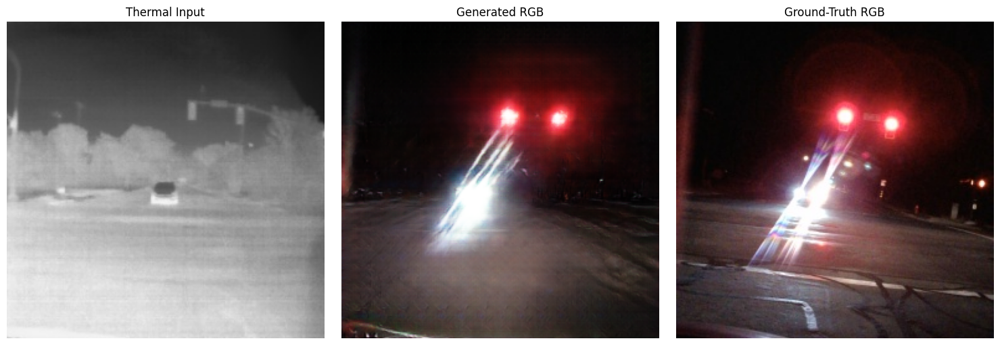

Test filename: 100001.jpg


In [ ]:

import matplotlib.pyplot as plt
import torch
import numpy as np
from PIL import Image

# Find the paired ground-truth RGB image.
thermal_dir = Path("/content/TRI2I_split/test/A")
rgb_dir = Path("/content/TRI2I_split/test/B")

thermal_path = image_path
rgb_path = rgb_dir / thermal_path.name

assert rgb_path.exists(), f"Paired RGB image missing: {rgb_path}"

thermal_image = Image.open(thermal_path).convert("RGB").resize((256, 256))
rgb_target = Image.open(rgb_path).convert("RGB").resize((256, 256))

# Use the already-loaded generator to generate RGB.
input_array = np.asarray(thermal_image, dtype=np.float32) / 127.5 - 1.0
input_tensor = (
    torch.from_numpy(input_array)
    .permute(2, 0, 1)
    .unsqueeze(0)
    .to(device)
)

with torch.inference_mode():
    generated = netG(input_tensor)[0].detach().cpu()

generated_rgb = (
    (generated.clamp(-1, 1).permute(1, 2, 0).numpy() + 1.0) * 127.5
).round().astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(thermal_image)
axes[0].set_title("Thermal Input")

axes[1].imshow(generated_rgb)
axes[1].set_title("Generated RGB")

axes[2].imshow(rgb_target)
axes[2].set_title("Ground-Truth RGB")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Test filename:", thermal_path.name)


In [ ]:

try:
    import skimage
    from skimage.metrics import structural_similarity

    print("scikit-image version:", skimage.__version__)
    print("SSIM function: available")
except ImportError:
    print("scikit-image is not installed.")


scikit-image version: 0.25.2
SSIM function: available


In [ ]:

import csv
import time
from pathlib import Path

import numpy as np
import torch
from PIL import Image
from skimage.metrics import structural_similarity

# ---------- Paths and settings ----------
thermal_dir = Path("/content/TRI2I_split/test/A")
rgb_dir = Path("/content/TRI2I_split/test/B")

results_dir = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/evaluation"
)
results_dir.mkdir(parents=True, exist_ok=True)

csv_path = results_dir / "TRI2I_Thermal_RGB_test_metrics.csv"
summary_path = results_dir / "TRI2I_Thermal_RGB_test_summary.txt"

assert thermal_dir.is_dir() and rgb_dir.is_dir()
assert "netG" in globals(), "Generator netG is not loaded."

thermal_files = sorted(thermal_dir.glob("*.jpg"))
rgb_names = {p.name for p in rgb_dir.glob("*.jpg")}

assert len(thermal_files) == 14884, (
    f"Expected 14884 thermal images, found {len(thermal_files)}"
)
assert {p.name for p in thermal_files} == rgb_names, (
    "Thermal and RGB filenames do not match."
)

device = next(netG.parameters()).device
netG.eval()

batch_size = 16
all_mae = []
all_psnr = []
all_ssim = []
start_time = time.time()

# Input/target tensors use the Pix2Pix [-1, 1] normalization.
def load_pair_batch(paths):
    inputs, targets = [], []

    for thermal_path in paths:
        rgb_path = rgb_dir / thermal_path.name

        thermal = Image.open(thermal_path).convert("RGB").resize(
            (256, 256), Image.Resampling.BICUBIC
        )
        rgb = Image.open(rgb_path).convert("RGB").resize(
            (256, 256), Image.Resampling.BICUBIC
        )

        x = np.asarray(thermal, dtype=np.float32) / 127.5 - 1.0
        y = np.asarray(rgb, dtype=np.float32) / 127.5 - 1.0

        inputs.append(torch.from_numpy(x).permute(2, 0, 1))
        targets.append(torch.from_numpy(y).permute(2, 0, 1))

    return torch.stack(inputs), torch.stack(targets)

with open(csv_path, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow(["filename", "MAE", "PSNR_dB", "SSIM"])

    for start in range(0, len(thermal_files), batch_size):
        paths = thermal_files[start:start + batch_size]
        inputs, targets = load_pair_batch(paths)

        inputs = inputs.to(device)
        targets = targets.to(device)

        with torch.inference_mode():
            predictions = netG(inputs)

        # Convert both prediction and target to [0, 1].
        predictions = (
            predictions.float().clamp(-1, 1) + 1
        ) / 2
        targets = (targets.float() + 1) / 2

        # MAE and PSNR per image, averaged across RGB channels and pixels.
        errors = (predictions - targets).abs()
        batch_mae = errors.flatten(1).mean(1).cpu().numpy()

        mse = ((predictions - targets) ** 2).flatten(1).mean(1)
        batch_psnr = (
            10 * torch.log10(1.0 / mse.clamp_min(1e-12))
        ).cpu().numpy()

        pred_np = predictions.permute(0, 2, 3, 1).cpu().numpy()
        target_np = targets.permute(0, 2, 3, 1).cpu().numpy()

        for i, path in enumerate(paths):
            ssim_value = structural_similarity(
                target_np[i],
                pred_np[i],
                data_range=1.0,
                channel_axis=-1
            )

            mae_value = float(batch_mae[i])
            psnr_value = float(batch_psnr[i])
            ssim_value = float(ssim_value)

            all_mae.append(mae_value)
            all_psnr.append(psnr_value)
            all_ssim.append(ssim_value)

            writer.writerow([
                path.name,
                f"{mae_value:.8f}",
                f"{psnr_value:.6f}",
                f"{ssim_value:.8f}"
            ])

        f.flush()

        completed = start + len(paths)
        if completed % 512 == 0 or completed == len(thermal_files):
            elapsed = time.time() - start_time
            print(
                f"Evaluated {completed}/{len(thermal_files)} images "
                f"| elapsed: {elapsed / 60:.1f} min"
            )

# Equal-weight average across test images.
summary = (
    f"Test images: {len(all_mae)}\n"
    f"Mean MAE [0,1]: {np.mean(all_mae):.6f}\n"
    f"Mean PSNR (dB): {np.mean(all_psnr):.4f}\n"
    f"Mean SSIM: {np.mean(all_ssim):.6f}\n"
    f"Elapsed minutes: {(time.time() - start_time) / 60:.2f}\n"
    f"Per-image metrics CSV: {csv_path}\n"
)

summary_path.write_text(summary)
print("\n========== TEST RESULTS ==========")
print(summary)


Evaluated 512/14884 images | elapsed: 0.3 min
Evaluated 1024/14884 images | elapsed: 0.5 min
Evaluated 1536/14884 images | elapsed: 0.7 min
Evaluated 2048/14884 images | elapsed: 0.9 min
Evaluated 2560/14884 images | elapsed: 1.1 min
Evaluated 3072/14884 images | elapsed: 1.3 min
Evaluated 3584/14884 images | elapsed: 1.5 min
Evaluated 4096/14884 images | elapsed: 1.7 min
Evaluated 4608/14884 images | elapsed: 1.9 min
Evaluated 5120/14884 images | elapsed: 2.1 min
Evaluated 5632/14884 images | elapsed: 2.3 min
Evaluated 6144/14884 images | elapsed: 2.5 min
Evaluated 6656/14884 images | elapsed: 2.8 min
Evaluated 7168/14884 images | elapsed: 3.0 min
Evaluated 7680/14884 images | elapsed: 3.2 min
Evaluated 8192/14884 images | elapsed: 3.4 min
Evaluated 8704/14884 images | elapsed: 3.6 min
Evaluated 9216/14884 images | elapsed: 3.8 min
Evaluated 9728/14884 images | elapsed: 4.0 min
Evaluated 10240/14884 images | elapsed: 4.2 min
Evaluated 10752/14884 images | elapsed: 4.4 min
Evaluated 11

In [ ]:

from pathlib import Path

log_path = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/"
    "TRI2I_Thermal_RGB_resume_v1/loss_log.txt"
)

assert log_path.exists(), f"Training log not found: {log_path}"

lines = log_path.read_text(errors="replace").splitlines()

print("Total lines:", len(lines))

print("\n========== FIRST 12 LOG LINES ==========")
print("\n".join(lines[:12]))

print("\n========== LAST 20 LOG LINES ==========")
print("\n".join(lines[-20:]))

print("\n========== EPOCHS FOUND ==========")
epochs = sorted({
    int(line.split("epoch:")[1].split(",")[0].strip())
    for line in lines
    if "epoch:" in line and "iters:" in line
})
print(epochs)

print("\n========== ITERATION RANGE ==========")
iterations = [
    int(line.split("iters:")[1].split(",")[0].strip())
    for line in lines
    if "epoch:" in line and "iters:" in line
]
if iterations:
    print("First logged iteration:", iterations[0])
    print("Last logged iteration:", iterations[-1])


In [ ]:

from pathlib import Path
from google.colab import drive

# Mount Google Drive if needed
drive.mount('/content/drive', force_remount=False)

base = Path('/content/drive/MyDrive/MP1_Thermal_RGB')

files_to_check = [
    base / 'evaluation/TRI2I_Thermal_RGB_test_metrics.csv',
    base / 'evaluation/TRI2I_Thermal_RGB_test_summary.txt',
    base / 'checkpoints/TRI2I_Thermal_RGB_resume_v1/latest_net_G.pth',
    base / 'checkpoints/TRI2I_Thermal_RGB_resume_v1/latest_net_D.pth',
    base / 'checkpoints/TRI2I_Thermal_RGB_resume_v1/loss_log.txt',
    base / 'checkpoints/TRI2I_Thermal_RGB_resume_v1/train_opt.txt',
]

for path in files_to_check:
    if path.exists():
        print(f'FOUND   | {path.name} | {path.stat().st_size / (1024**2):.2f} MB')
    else:
        print(f'MISSING | {path.name}')

summary = base / 'evaluation/TRI2I_Thermal_RGB_test_summary.txt'
if summary.exists():
    print('\n--- TEST EVALUATION SUMMARY ---')
    print(summary.read_text()[:5000])

log = base / 'checkpoints/TRI2I_Thermal_RGB_resume_v1/loss_log.txt'
if log.exists():
    lines = log.read_text(errors='replace').splitlines()
    print('\n--- LAST 10 TRAINING LOG LINES ---')
    print('\n'.join(lines[-10:]))


Mounted at /content/drive
FOUND   | TRI2I_Thermal_RGB_test_metrics.csv | 0.61 MB
FOUND   | TRI2I_Thermal_RGB_test_summary.txt | 0.00 MB
FOUND   | latest_net_G.pth | 207.64 MB
FOUND   | latest_net_D.pth | 10.58 MB
FOUND   | loss_log.txt | 0.02 MB
FOUND   | train_opt.txt | 0.00 MB

--- TEST EVALUATION SUMMARY ---
Test images: 14884
Mean MAE [0,1]: 0.085790
Mean PSNR (dB): 16.9817
Mean SSIM: 0.498237
Elapsed minutes: 5.95
Per-image metrics CSV: /content/drive/MyDrive/MP1_Thermal_RGB/evaluation/TRI2I_Thermal_RGB_test_metrics.csv


--- LAST 10 TRAINING LOG LINES ---
[Rank 0] (epoch: 3, iters: 72000, time: 0.094, data: 0.007) , G_GAN: 3.251, G_L1: 17.961, D_real: 0.090, D_fake: 0.259

[Rank 0] (epoch: 3, iters: 72500, time: 0.073, data: 0.003) , G_GAN: 3.429, G_L1: 15.734, D_real: 0.130, D_fake: 0.129

[Rank 0] (epoch: 3, iters: 73000, time: 0.103, data: 0.003) , G_GAN: 3.764, G_L1: 19.714, D_real: 0.614, D_fake: 0.103

[Rank 0] (epoch: 3, iters: 73500, time: 0.072, data: 0.005) , G_GAN: 4.2

In [ ]:

from pathlib import Path

folder = Path(
    '/content/drive/MyDrive/MP1_Thermal_RGB/'
    'checkpoints/TRI2I_Thermal_RGB_resume_v1'
)

config_file = folder / 'train_opt.txt'

print('--- SAVED TRAINING CONFIGURATION ---')
print(config_file.read_text())

print('\n--- CHECKPOINT FILES ---')
for name in ['latest_net_G.pth', 'latest_net_D.pth']:
    path = folder / name
    print(f'{name}: {path.stat().st_size:,} bytes')


--- SAVED TRAINING CONFIGURATION ---
----------------- Options ---------------
               batch_size: 4                             	[default: 1]
                    beta1: 0.5                           
          checkpoints_dir: /content/drive/MyDrive/MP1_Thermal_RGB/checkpoints	[default: ./checkpoints]
           continue_train: True                          	[default: False]
                crop_size: 256                           
                 dataroot: /content/TRI2I_pix2pix        	[default: None]
             dataset_mode: aligned                       
                direction: AtoB                          
             display_freq: 1000                          	[default: 400]
          display_winsize: 256                           
                    epoch: latest                        
              epoch_count: 3                             	[default: 1]
                 gan_mode: vanilla                       
                init_gain: 0.02                 

In [ ]:

import torch
from pathlib import Path

folder = Path(
    '/content/drive/MyDrive/MP1_Thermal_RGB/'
    'checkpoints/TRI2I_Thermal_RGB_resume_v1'
)

for name in ['latest_net_G.pth', 'latest_net_D.pth']:
    path = folder / name
    print(f'\nChecking {name}...')

    state = torch.load(
        path,
        map_location='cpu',
        weights_only=True
    )

    print('State type:', type(state).__name__)
    print('Parameter tensors:', len(state))

    bad_tensors = []
    for key, value in state.items():
        if isinstance(value, torch.Tensor):
            if not torch.isfinite(value).all().item():
                bad_tensors.append(key)

    print('Non-finite tensors:', len(bad_tensors))
    if bad_tensors:
        print('Affected tensors:', bad_tensors[:10])
    else:
        print('Checkpoint tensor values are finite.')

    del state

print('\nCheckpoint integrity check finished.')



Checking latest_net_G.pth...
State type: OrderedDict
Parameter tensors: 82
Non-finite tensors: 0
Checkpoint tensor values are finite.

Checking latest_net_D.pth...
State type: OrderedDict
Parameter tensors: 22
Non-finite tensors: 0
Checkpoint tensor values are finite.

Checkpoint integrity check finished.


In [ ]:

import pandas as pd
from pathlib import Path

csv_path = Path(
    '/content/drive/MyDrive/MP1_Thermal_RGB/'
    'evaluation/TRI2I_Thermal_RGB_test_metrics.csv'
)

df = pd.read_csv(csv_path)

print('Columns:', df.columns.tolist())
print('Number of rows:', len(df))
print('\nFirst 5 rows:')
print(df.head().to_string(index=False))

print('\nData types:')
print(df.dtypes.to_string())


Columns: ['filename', 'MAE', 'PSNR_dB', 'SSIM']
Number of rows: 14884

First 5 rows:
  filename      MAE   PSNR_dB     SSIM
100001.jpg 0.045669 21.717012 0.648325
100008.jpg 0.045986 21.594334 0.647317
 10002.jpg 0.069676 17.747967 0.535161
100021.jpg 0.069149 17.140181 0.598909
 10004.jpg 0.069517 17.750992 0.524854

Data types:
filename     object
MAE         float64
PSNR_dB     float64
SSIM        float64


In [ ]:

import pandas as pd
from pathlib import Path

csv_path = Path(
    '/content/drive/MyDrive/MP1_Thermal_RGB/'
    'evaluation/TRI2I_Thermal_RGB_test_metrics.csv'
)

df = pd.read_csv(csv_path)

metrics = ['MAE', 'PSNR_dB', 'SSIM']

print('--- OVERALL STATISTICS ---')
print(df[metrics].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90]
).round(4).to_string())

print('\n--- 10 BEST IMAGES BY SSIM ---')
print(
    df.nlargest(10, 'SSIM')[
        ['filename', 'MAE', 'PSNR_dB', 'SSIM']
    ].round(4).to_string(index=False)
)

print('\n--- 10 MOST DIFFICULT IMAGES BY SSIM ---')
print(
    df.nsmallest(10, 'SSIM')[
        ['filename', 'MAE', 'PSNR_dB', 'SSIM']
    ].round(4).to_string(index=False)
)

print('\n--- DATA QUALITY CHECK ---')
print('Duplicate filenames:', df['filename'].duplicated().sum())
print('Missing metric values:', int(df[metrics].isna().sum().sum()))
print('Non-finite metric values:',
      int((~df[metrics].apply(
          lambda col: col.map(lambda x: pd.notna(x) and abs(x) != float('inf'))
      )).sum().sum()))


--- OVERALL STATISTICS ---
              MAE     PSNR_dB        SSIM
count  14884.0000  14884.0000  14884.0000
mean       0.0858     16.9817      0.4982
std        0.0275      2.1000      0.1149
min        0.0204      6.2344      0.0913
10%        0.0524     14.4939      0.3495
25%        0.0678     15.5004      0.4238
50%        0.0834     16.9010      0.5020
75%        0.1017     18.2476      0.5759
90%        0.1203     19.5887      0.6417
max        0.4174     27.0061      0.8104

--- 10 BEST IMAGES BY SSIM ---
  filename    MAE  PSNR_dB   SSIM
 93206.jpg 0.0258  24.6215 0.8104
 93198.jpg 0.0231  24.7763 0.8061
102972.jpg 0.0204  23.6093 0.8044
 72352.jpg 0.0324  20.1404 0.8032
 75370.jpg 0.0316  22.2634 0.7994
 93301.jpg 0.0263  24.9792 0.7973
 93222.jpg 0.0372  23.0094 0.7971
 92940.jpg 0.0270  25.0828 0.7958
 92764.jpg 0.0233  25.9936 0.7956
 92444.jpg 0.0236  27.0061 0.7948

--- 10 MOST DIFFICULT IMAGES BY SSIM ---
 filename    MAE  PSNR_dB   SSIM
51427.jpg 0.1854  12.2330 0.09

In [ ]:

from pathlib import Path
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

root = Path('/content/TRI2I_split/test')
thermal_dir = root / 'A'
rgb_dir = root / 'B'

if not thermal_dir.exists() or not rgb_dir.exists():
    print('Test image folders are not available in this runtime.')
    print('Thermal folder:', thermal_dir, thermal_dir.exists())
    print('RGB folder:', rgb_dir, rgb_dir.exists())
else:
    csv_path = Path(
        '/content/drive/MyDrive/MP1_Thermal_RGB/'
        'evaluation/TRI2I_Thermal_RGB_test_metrics.csv'
    )
    df = pd.read_csv(csv_path)

    worst = df.nsmallest(3, 'SSIM')
    best = df.nlargest(3, 'SSIM')
    selected = [
        ('LOW SSIM', row) for _, row in worst.iterrows()
    ] + [
        ('HIGH SSIM', row) for _, row in best.iterrows()
    ]

    fig, axes = plt.subplots(len(selected), 2, figsize=(10, 4 * len(selected)))

    for i, (group, row) in enumerate(selected):
        filename = row['filename']
        thermal_path = thermal_dir / filename
        rgb_path = rgb_dir / filename

        if not thermal_path.exists() or not rgb_path.exists():
            axes[i, 0].text(0.5, 0.5, 'Thermal image missing',
                            ha='center', va='center')
            axes[i, 1].text(0.5, 0.5, 'RGB image missing',
                            ha='center', va='center')
            continue

        with Image.open(thermal_path) as im:
            thermal = im.convert('RGB').copy()
        with Image.open(rgb_path) as im:
            rgb = im.convert('RGB').copy()

        axes[i, 0].imshow(thermal)
        axes[i, 0].set_title(f'{filename} — Thermal input')
        axes[i, 1].imshow(rgb)
        axes[i, 1].set_title(
            f'{group} — RGB target | SSIM {row["SSIM"]:.3f}'
        )

        axes[i, 0].axis('off')
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()


Test image folders are not available in this runtime.
Thermal folder: /content/TRI2I_split/test/A False
RGB folder: /content/TRI2I_split/test/B False


In [ ]:

from pathlib import Path

paths = {
    "Original dataset ZIP": Path(
        "/content/drive/MyDrive/dataset_1-6-2024.zip"
    ),
    "Extracted dataset": Path(
        "/content/TRI2I_dataset/dataset_1-6-2024"
    ),
    "Test split": Path(
        "/content/TRI2I_split/test"
    ),
    "Evaluation CSV": Path(
        "/content/drive/MyDrive/MP1_Thermal_RGB/"
        "evaluation/TRI2I_Thermal_RGB_test_metrics.csv"
    ),
}

for label, path in paths.items():
    print(f"{label}: {'AVAILABLE' if path.exists() else 'NOT FOUND'}")
    if path.exists():
        print(f"  Path: {path}")


Original dataset ZIP: AVAILABLE
  Path: /content/drive/MyDrive/dataset_1-6-2024.zip
Extracted dataset: NOT FOUND
Test split: NOT FOUND
Evaluation CSV: AVAILABLE
  Path: /content/drive/MyDrive/MP1_Thermal_RGB/evaluation/TRI2I_Thermal_RGB_test_metrics.csv


In [ ]:

from pathlib import Path
import zipfile
import pandas as pd

zip_path = Path('/content/drive/MyDrive/dataset_1-6-2024.zip')
csv_path = Path(
    '/content/drive/MyDrive/MP1_Thermal_RGB/'
    'evaluation/TRI2I_Thermal_RGB_test_metrics.csv'
)

output_dir = Path('/content/TRI2I_visual_review')
output_dir.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(csv_path)
selected = pd.concat([
    df.nsmallest(3, 'SSIM'),
    df.nlargest(3, 'SSIM')
]).drop_duplicates('filename')

print('Selected images:')
print(selected[['filename', 'SSIM']].to_string(index=False))

with zipfile.ZipFile(zip_path, 'r') as z:
    members = z.namelist()
    for filename in selected['filename']:
        matches = [
            m for m in members
            if Path(m).name == filename
            and '/class1/' in m.replace('\\', '/')
        ]
        matches_t = [
            m for m in members
            if Path(m).name == filename
            and '/class2/' in m.replace('\\', '/')
        ]

        if len(matches) != 1 or len(matches_t) != 1:
            print(f'Could not uniquely locate both images: {filename}')
            print('RGB matches:', matches[:3])
            print('Thermal matches:', matches_t[:3])
            continue

        for member, subfolder in [
            (matches[0], 'RGB'),
            (matches_t[0], 'Thermal')
        ]:
            destination = output_dir / subfolder / filename
            destination.parent.mkdir(parents=True, exist_ok=True)
            destination.write_bytes(z.read(member))
            print('Extracted:', subfolder, filename)

print('\nOutput folder:', output_dir)


Selected images:
  filename     SSIM
 51427.jpg 0.091342
 33940.jpg 0.093143
 39368.jpg 0.093384
 93206.jpg 0.810389
 93198.jpg 0.806071
102972.jpg 0.804408
Extracted: RGB 51427.jpg
Extracted: Thermal 51427.jpg
Extracted: RGB 33940.jpg
Extracted: Thermal 33940.jpg
Extracted: RGB 39368.jpg
Extracted: Thermal 39368.jpg
Extracted: RGB 93206.jpg
Extracted: Thermal 93206.jpg
Extracted: RGB 93198.jpg
Extracted: Thermal 93198.jpg
Extracted: RGB 102972.jpg
Extracted: Thermal 102972.jpg

Output folder: /content/TRI2I_visual_review


In [ ]:

from pathlib import Path
from google.colab import drive

# Mount Google Drive if necessary
drive.mount('/content/drive', force_remount=False)

# Check the expected CSV location
csv_path = Path(
    '/content/drive/MyDrive/MP1_Thermal_RGB/'
    'evaluation/TRI2I_Thermal_RGB_test_metrics.csv'
)

if csv_path.exists():
    print('SUCCESS: Evaluation CSV found.')
    print('Path:', csv_path)
else:
    print('CSV not found at the expected path.')
    print('\nSearching the project folder...')

    search_root = Path('/content/drive/MyDrive/MP1_Thermal_RGB')
    matches = list(search_root.rglob('TRI2I_Thermal_RGB_test_metrics.csv'))

    if matches:
        for match in matches:
            print('FOUND:', match)
        csv_path = matches[0]
    else:
        print('CSV not found in the project folder.')
        print('Check that the correct Google Drive account is mounted.')


Mounted at /content/drive
SUCCESS: Evaluation CSV found.
Path: /content/drive/MyDrive/MP1_Thermal_RGB/evaluation/TRI2I_Thermal_RGB_test_metrics.csv


Missing image pair: 51427.jpg
Missing image pair: 33940.jpg
Missing image pair: 39368.jpg
Missing image pair: 93206.jpg
Missing image pair: 93198.jpg
Missing image pair: 102972.jpg


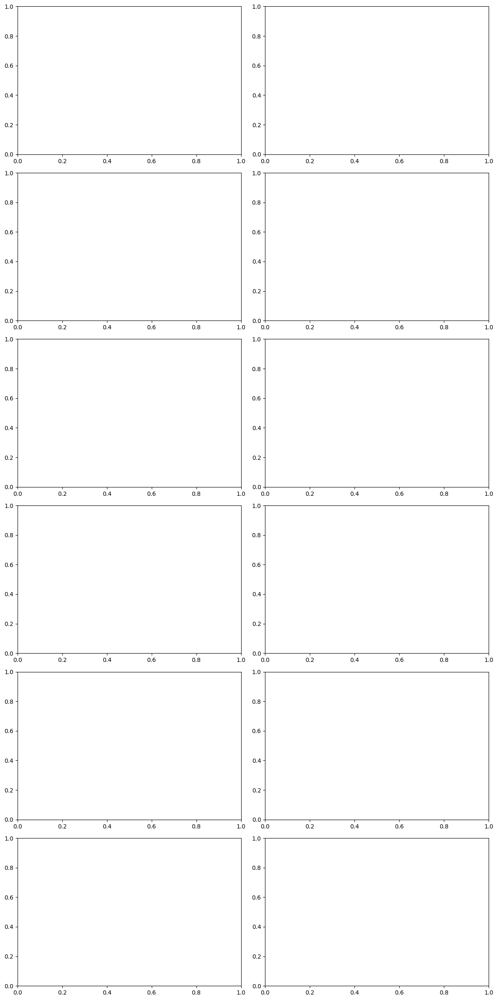

In [ ]:

from pathlib import Path
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

folder = Path('/content/TRI2I_visual_review')
csv_path = Path(
    '/content/drive/MyDrive/MP1_Thermal_RGB/'
    'evaluation/TRI2I_Thermal_RGB_test_metrics.csv'
)

df = pd.read_csv(csv_path)

selected = pd.concat([
    df.nsmallest(3, 'SSIM'),
    df.nlargest(3, 'SSIM')
]).drop_duplicates('filename').reset_index(drop=True)

fig, axes = plt.subplots(6, 2, figsize=(12, 24))

for i, row in selected.iterrows():
    filename = row['filename']
    thermal_path = folder / 'Thermal' / filename
    rgb_path = folder / 'RGB' / filename

    if not thermal_path.exists() or not rgb_path.exists():
        print('Missing image pair:', filename)
        continue

    with Image.open(thermal_path) as im:
        thermal = im.convert('RGB').copy()

    with Image.open(rgb_path) as im:
        rgb = im.convert('RGB').copy()

    axes[i, 0].imshow(thermal)
    axes[i, 0].set_title(f'{filename} — Thermal input')

    axes[i, 1].imshow(rgb)
    axes[i, 1].set_title(
        f'RGB target | SSIM={row["SSIM"]:.3f} '
        f'| MAE={row["MAE"]:.3f}'
    )

    axes[i, 0].axis('off')
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()


In [ ]:

from pathlib import Path
import pandas as pd

folder = Path('/content/TRI2I_visual_review')
csv_path = Path(
    '/content/drive/MyDrive/MP1_Thermal_RGB/'
    'evaluation/TRI2I_Thermal_RGB_test_metrics.csv'
)

df = pd.read_csv(csv_path)
selected = pd.concat([
    df.nsmallest(3, 'SSIM'),
    df.nlargest(3, 'SSIM')
]).drop_duplicates('filename')

print('--- EXTRACTED IMAGE FILES ---')
for subfolder in ['Thermal', 'RGB']:
    path = folder / subfolder
    print(f'\n{subfolder} folder exists: {path.exists()}')
    if path.exists():
        print('Files:', sorted(p.name for p in path.iterdir()))

print('\n--- CHECKING REQUIRED IMAGE PAIRS ---')
for filename in selected['filename']:
    thermal = folder / 'Thermal' / filename
    rgb = folder / 'RGB' / filename
    print(
        f'{filename}: '
        f'Thermal={"OK" if thermal.is_file() else "MISSING"}, '
        f'RGB={"OK" if rgb.is_file() else "MISSING"}'
    )


--- EXTRACTED IMAGE FILES ---

Thermal folder exists: False

RGB folder exists: False

--- CHECKING REQUIRED IMAGE PAIRS ---
51427.jpg: Thermal=MISSING, RGB=MISSING
33940.jpg: Thermal=MISSING, RGB=MISSING
39368.jpg: Thermal=MISSING, RGB=MISSING
93206.jpg: Thermal=MISSING, RGB=MISSING
93198.jpg: Thermal=MISSING, RGB=MISSING
102972.jpg: Thermal=MISSING, RGB=MISSING


In [ ]:

from pathlib import Path
from google.colab import drive
import zipfile
import pandas as pd

drive.mount('/content/drive', force_remount=False)

zip_path = Path('/content/drive/MyDrive/dataset_1-6-2024.zip')
csv_path = Path(
    '/content/drive/MyDrive/MP1_Thermal_RGB/'
    'evaluation/TRI2I_Thermal_RGB_test_metrics.csv'
)
output_dir = Path('/content/TRI2I_visual_review')

if not zip_path.is_file():
    raise FileNotFoundError(f'Dataset ZIP not found: {zip_path}')
if not csv_path.is_file():
    raise FileNotFoundError(f'Evaluation CSV not found: {csv_path}')

df = pd.read_csv(csv_path)
selected = pd.concat([
    df.nsmallest(3, 'SSIM'),
    df.nlargest(3, 'SSIM')
]).drop_duplicates('filename')

# Identify each selected file under class1 (RGB) and class2 (Thermal).
with zipfile.ZipFile(zip_path, 'r') as z:
    members = z.namelist()
    normalized = [(m, m.replace('\\', '/')) for m in members]

    for filename in selected['filename']:
        for class_name, destination_name in [
            ('class1', 'RGB'),
            ('class2', 'Thermal')
        ]:
            matches = [
                original for original, member in normalized
                if Path(member).name == filename
                and f'/{class_name}/' in f'/{member.strip("/")}'
            ]

            if len(matches) != 1:
                raise RuntimeError(
                    f'Expected one {class_name} match for {filename}; '
                    f'found {len(matches)}'
                )

            destination = output_dir / destination_name / filename
            destination.parent.mkdir(parents=True, exist_ok=True)
            destination.write_bytes(z.read(matches[0]))
            print(f'SAVED: {destination_name}/{filename}')

# Verify all 12 files exist.
print('\n--- FINAL VERIFICATION ---')
for filename in selected['filename']:
    for subfolder in ['Thermal', 'RGB']:
        path = output_dir / subfolder / filename
        print(f'{subfolder}/{filename}: {"OK" if path.is_file() else "MISSING"}')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
SAVED: RGB/51427.jpg
SAVED: Thermal/51427.jpg
SAVED: RGB/33940.jpg
SAVED: Thermal/33940.jpg
SAVED: RGB/39368.jpg
SAVED: Thermal/39368.jpg
SAVED: RGB/93206.jpg
SAVED: Thermal/93206.jpg
SAVED: RGB/93198.jpg
SAVED: Thermal/93198.jpg
SAVED: RGB/102972.jpg
SAVED: Thermal/102972.jpg

--- FINAL VERIFICATION ---
Thermal/51427.jpg: OK
RGB/51427.jpg: OK
Thermal/33940.jpg: OK
RGB/33940.jpg: OK
Thermal/39368.jpg: OK
RGB/39368.jpg: OK
Thermal/93206.jpg: OK
RGB/93206.jpg: OK
Thermal/93198.jpg: OK
RGB/93198.jpg: OK
Thermal/102972.jpg: OK
RGB/102972.jpg: OK


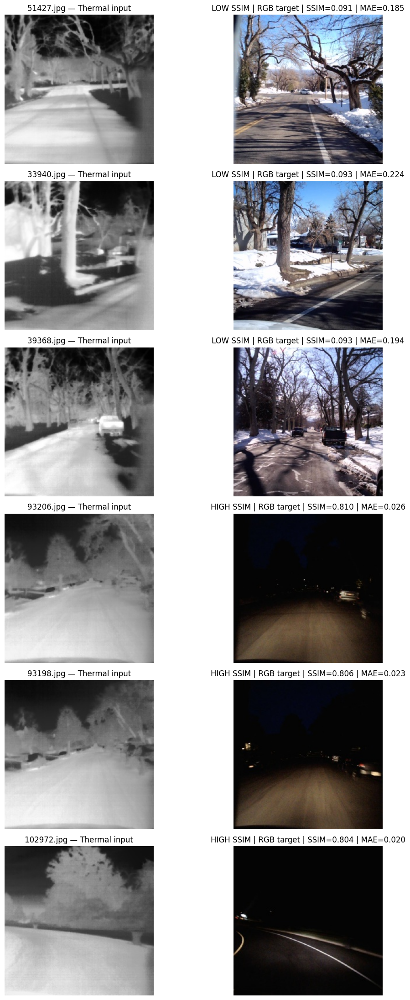

In [ ]:

from pathlib import Path
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

folder = Path('/content/TRI2I_visual_review')
csv_path = Path(
    '/content/drive/MyDrive/MP1_Thermal_RGB/'
    'evaluation/TRI2I_Thermal_RGB_test_metrics.csv'
)

df = pd.read_csv(csv_path)

selected = pd.concat([
    df.nsmallest(3, 'SSIM'),
    df.nlargest(3, 'SSIM')
]).drop_duplicates('filename').reset_index(drop=True)

# Verify all pairs before creating the figure.
missing = []
for filename in selected['filename']:
    for subfolder in ['Thermal', 'RGB']:
        path = folder / subfolder / filename
        if not path.is_file():
            missing.append(str(path))

if missing:
    print('Missing files:')
    print('\n'.join(missing))
else:
    fig, axes = plt.subplots(6, 2, figsize=(12, 22))

    for i, row in selected.iterrows():
        filename = row['filename']

        with Image.open(folder / 'Thermal' / filename) as im:
            thermal = im.convert('RGB').copy()

        with Image.open(folder / 'RGB' / filename) as im:
            rgb = im.convert('RGB').copy()

        group = 'LOW SSIM' if i < 3 else 'HIGH SSIM'

        axes[i, 0].imshow(thermal)
        axes[i, 0].set_title(f'{filename} — Thermal input')
        axes[i, 1].imshow(rgb)
        axes[i, 1].set_title(
            f'{group} | RGB target | '
            f'SSIM={row["SSIM"]:.3f} | MAE={row["MAE"]:.3f}'
        )

        axes[i, 0].axis('off')
        axes[i, 1].axis('off')

    plt.tight_layout()
    plt.show()


Dataset

In [ ]:

from google.colab import drive

drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:

from pathlib import Path

paths = {
    "Evaluation CSV": Path(
        "/content/drive/MyDrive/MP1_Thermal_RGB/"
        "evaluation/TRI2I_Thermal_RGB_test_metrics.csv"
    ),
    "Generator checkpoint": Path(
        "/content/drive/MyDrive/MP1_Thermal_RGB/"
        "checkpoints/TRI2I_Thermal_RGB_resume_v1/latest_net_G.pth"
    ),
    "Discriminator checkpoint": Path(
        "/content/drive/MyDrive/MP1_Thermal_RGB/"
        "checkpoints/TRI2I_Thermal_RGB_resume_v1/latest_net_D.pth"
    ),
    "Original dataset ZIP": Path(
        "/content/drive/MyDrive/dataset_1-6-2024.zip"
    ),
    "Temporary visual-review folder": Path(
        "/content/TRI2I_visual_review"
    ),
}

for name, path in paths.items():
    if path.is_file():
        print(f"FOUND  | {name} | {path.stat().st_size / (1024**2):.2f} MB")
    elif path.is_dir():
        print(f"FOUND  | {name} | directory")
    else:
        print(f"MISSING | {name}")


FOUND  | Evaluation CSV | 0.61 MB
FOUND  | Generator checkpoint | 207.64 MB
FOUND  | Discriminator checkpoint | 10.58 MB
FOUND  | Original dataset ZIP | 5570.17 MB
MISSING | Temporary visual-review folder


In [ ]:

from pathlib import Path
import zipfile
import pandas as pd

zip_path = Path('/content/drive/MyDrive/dataset_1-6-2024.zip')
csv_path = Path(
    '/content/drive/MyDrive/MP1_Thermal_RGB/'
    'evaluation/TRI2I_Thermal_RGB_test_metrics.csv'
)
output_dir = Path('/content/TRI2I_visual_review')

df = pd.read_csv(csv_path)

selected = pd.concat([
    df.nsmallest(3, 'SSIM'),
    df.nlargest(3, 'SSIM')
]).drop_duplicates('filename')

output_dir.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as z:
    members = [(m, m.replace('\\', '/')) for m in z.namelist()]

    for filename in selected['filename']:
        for class_name, folder_name in [
            ('class1', 'RGB'),
            ('class2', 'Thermal')
        ]:
            matches = [
                original for original, normalized in members
                if Path(normalized).name == filename
                and f'/{class_name}/' in f'/{normalized.strip("/")}'
            ]

            if len(matches) != 1:
                raise RuntimeError(
                    f'{filename}: expected one {class_name} match, '
                    f'found {len(matches)}'
                )

            destination = output_dir / folder_name / filename
            destination.parent.mkdir(parents=True, exist_ok=True)
            destination.write_bytes(z.read(matches[0]))
            print(f'SAVED: {folder_name}/{filename}')

print('\nAll six image pairs restored.')


SAVED: RGB/51427.jpg
SAVED: Thermal/51427.jpg
SAVED: RGB/33940.jpg
SAVED: Thermal/33940.jpg
SAVED: RGB/39368.jpg
SAVED: Thermal/39368.jpg
SAVED: RGB/93206.jpg
SAVED: Thermal/93206.jpg
SAVED: RGB/93198.jpg
SAVED: Thermal/93198.jpg
SAVED: RGB/102972.jpg
SAVED: Thermal/102972.jpg

All six image pairs restored.


Inference device: cuda
Generator checkpoint loaded successfully.
Generated: 51427.jpg
Generated: 33940.jpg
Generated: 39368.jpg
Generated: 93206.jpg
Generated: 93198.jpg
Generated: 102972.jpg


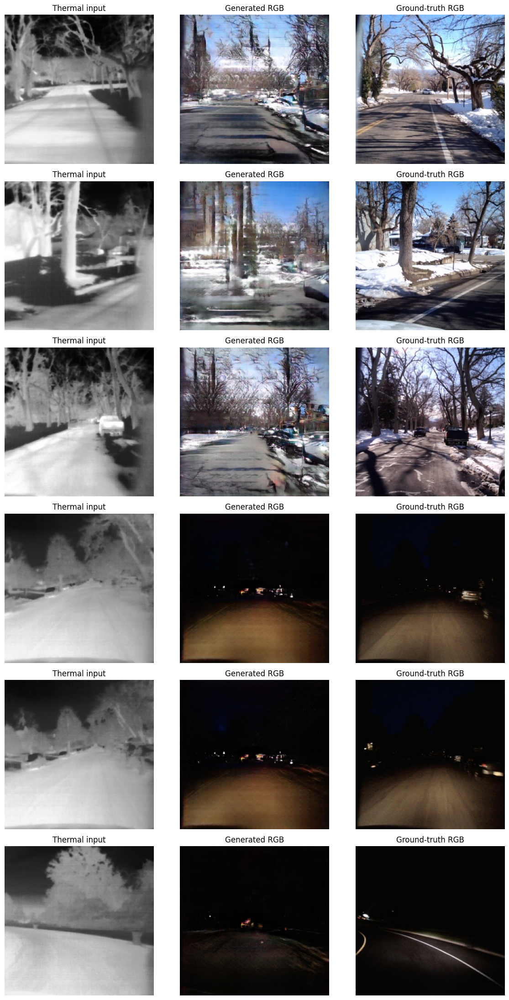


Predictions saved to: /content/drive/MyDrive/MP1_Thermal_RGB/evaluation/visual_predictions
Inference completed. No training was performed.


In [ ]:

from pathlib import Path
import subprocess
import sys
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

# Paths
base = Path("/content/drive/MyDrive/MP1_Thermal_RGB")
checkpoint = base / "checkpoints/TRI2I_Thermal_RGB_resume_v1/latest_net_G.pth"
review_dir = Path("/content/TRI2I_visual_review")
output_dir = base / "evaluation/visual_predictions"
output_dir.mkdir(parents=True, exist_ok=True)

assert checkpoint.exists(), f"Checkpoint not found: {checkpoint}"

# Load the official Pix2Pix architecture
repo = Path("/content/pytorch-CycleGAN-and-pix2pix")
if not repo.exists():
    result = subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix.git",
         str(repo)],
        capture_output=True, text=True
    )
    if result.returncode != 0:
        raise RuntimeError("Could not obtain Pix2Pix code:\n" + result.stderr[-2000:])

sys.path.insert(0, str(repo))
from models import networks

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Inference device:", device)

# Match the saved Pix2Pix generator configuration
netG = networks.define_G(
    input_nc=3,
    output_nc=3,
    ngf=64,
    netG="unet_256",
    norm="batch",
    use_dropout=True,
    init_type="normal",
    init_gain=0.02,
)

state = torch.load(checkpoint, map_location="cpu", weights_only=True)
netG.load_state_dict(state, strict=True)
netG.to(device)
netG.eval()
print("Generator checkpoint loaded successfully.")

filenames = [
    "51427.jpg", "33940.jpg", "39368.jpg",
    "93206.jpg", "93198.jpg", "102972.jpg"
]

def load_input(path):
    image = Image.open(path).convert("RGB").resize((256, 256))
    arr = np.asarray(image, dtype=np.float32) / 127.5 - 1.0
    return torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0)

def tensor_to_image(tensor):
    arr = tensor.squeeze(0).detach().cpu().permute(1, 2, 0).numpy()
    arr = ((arr + 1.0) * 127.5).clip(0, 255).astype(np.uint8)
    return Image.fromarray(arr)

# Generate and save predictions
predictions = {}
with torch.inference_mode():
    for name in filenames:
        thermal_path = review_dir / "Thermal" / name
        rgb_path = review_dir / "RGB" / name
        assert thermal_path.exists(), f"Missing thermal image: {thermal_path}"
        assert rgb_path.exists(), f"Missing RGB image: {rgb_path}"

        thermal_tensor = load_input(thermal_path).to(device)
        prediction = netG(thermal_tensor)
        pred_image = tensor_to_image(prediction)

        predictions[name] = pred_image
        pred_image.save(output_dir / name)
        print("Generated:", name)

# Display: thermal input | generated RGB | ground-truth RGB
fig, axes = plt.subplots(6, 3, figsize=(12, 22))
for row, name in enumerate(filenames):
    thermal = Image.open(review_dir / "Thermal" / name).convert("RGB")
    ground_truth = Image.open(review_dir / "RGB" / name).convert("RGB")

    axes[row, 0].imshow(thermal)
    axes[row, 1].imshow(predictions[name])
    axes[row, 2].imshow(ground_truth)

    axes[row, 0].set_ylabel(name, fontsize=10)
    axes[row, 0].set_title("Thermal input")
    axes[row, 1].set_title("Generated RGB")
    axes[row, 2].set_title("Ground-truth RGB")

    for col in range(3):
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

print("\nPredictions saved to:", output_dir)
print("Inference completed. No training was performed.")


In [ ]:

from pathlib import Path
from datetime import datetime

base = Path("/content/drive/MyDrive/MP1_Thermal_RGB")
report_dir = base / "evaluation"
report_dir.mkdir(parents=True, exist_ok=True)

report_path = report_dir / "THERMAL_RGB_BASELINE_REPORT.txt"

report = """
THERMAL TO RGB — BASELINE EXPERIMENT REPORT
===========================================

Dataset:
- TRI2I paired thermal and RGB dataset
- Original paired images: 148,829
- Train split: 119,063
- Validation split: 14,882
- Test split: 14,884
- Split seed: 42
- Input: thermal image
- Target: paired RGB image

Model:
- Pix2Pix conditional GAN
- Generator: U-Net 256
- Discriminator: PatchGAN
- L1 reconstruction loss plus adversarial loss
- Input and output resolution: 256 x 256

TEST SET METRICS:
- Mean MAE: 0.085790
- Mean PSNR: 16.9817 dB
- Mean SSIM: 0.498237
- Number of test images evaluated: 14,884

VISUAL REVIEW:
- The generator produces recognizable outdoor scenes and plausible colors.
- Road, trees, sky, and snow are recognizable in the reviewed examples.
- Blur, streaking, and texture artifacts are visible.
- Some scene details and colors differ from ground-truth RGB.
- Generated RGB is an estimate, not guaranteed recovery of true colors.

CHECKPOINT:
- Resume experiment:
  checkpoints/TRI2I_Thermal_RGB_resume_v1/latest_net_G.pth
- Discriminator:
  checkpoints/TRI2I_Thermal_RGB_resume_v1/latest_net_D.pth

TRAINING STATUS:
- The recorded resume log reached iteration 74,000.
- The log does not establish that epoch 3 completed.
- The saved checkpoint does not include optimizer state, so exact
  restoration of Adam momentum is not possible from this checkpoint alone.
- Do not claim the planned training schedule completed without further
  verification.

EVALUATION FILES:
- TRI2I_Thermal_RGB_test_metrics.csv
- TRI2I_Thermal_RGB_test_summary.txt

VISUAL PREDICTIONS:
- evaluation/visual_predictions/

NEXT ACTION:
- Preserve this baseline.
- Decide on the next controlled experiment only after reviewing
  the training history and baseline outputs.
- Evaluate any improved model on the same held-out test split.
"""

report_path.write_text(report.strip() + "\n", encoding="utf-8")

print("Baseline report saved successfully:")
print(report_path)
print("\nReport size:", report_path.stat().st_size, "bytes")


Baseline report saved successfully:
/content/drive/MyDrive/MP1_Thermal_RGB/evaluation/THERMAL_RGB_BASELINE_REPORT.txt

Report size: 1840 bytes


In [ ]:

from pathlib import Path

log_path = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/"
    "TRI2I_Thermal_RGB_resume_v1/loss_log.txt"
)

if not log_path.exists():
    raise FileNotFoundError(f"Training log not found: {log_path}")

lines = log_path.read_text(errors="replace").splitlines()

print("Total log lines:", len(lines))
print("\n===== LAST 30 TRAINING LOG LINES =====\n")

for line in lines[-30:]:
    print(line)

print("\n===== TRAINING LOG CHECK =====")
print("Log exists:", log_path.exists())
print("File size:", log_path.stat().st_size, "bytes")


Total log lines: 297

===== LAST 30 TRAINING LOG LINES =====

[Rank 0] (epoch: 3, iters: 67000, time: 0.098, data: 0.005) , G_GAN: 3.509, G_L1: 21.181, D_real: 0.022, D_fake: 0.115

[Rank 0] (epoch: 3, iters: 67500, time: 0.072, data: 0.003) , G_GAN: 3.990, G_L1: 20.360, D_real: 0.198, D_fake: 0.049

[Rank 0] (epoch: 3, iters: 68000, time: 0.094, data: 0.003) , G_GAN: 3.528, G_L1: 17.757, D_real: 0.076, D_fake: 0.051

[Rank 0] (epoch: 3, iters: 68500, time: 0.072, data: 0.003) , G_GAN: 3.700, G_L1: 18.770, D_real: 0.049, D_fake: 0.183

[Rank 0] (epoch: 3, iters: 69000, time: 0.103, data: 0.003) , G_GAN: 3.891, G_L1: 15.293, D_real: 0.011, D_fake: 0.354

[Rank 0] (epoch: 3, iters: 69500, time: 0.073, data: 0.005) , G_GAN: 4.024, G_L1: 12.693, D_real: 0.002, D_fake: 0.587

[Rank 0] (epoch: 3, iters: 70000, time: 0.096, data: 0.003) , G_GAN: 5.609, G_L1: 19.391, D_real: 0.083, D_fake: 0.029

[Rank 0] (epoch: 3, iters: 70500, time: 0.067, data: 0.004) , G_GAN: 3.254, G_L1: 14.803, D_real: 

In [ ]:

from pathlib import Path

checkpoint_dir = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints"
)

folders = [
    "TRI2I_Thermal_RGB_baseline",
    "TRI2I_Thermal_RGB_resume_v1",
    "TRI2I_T4_smoke",
]

for folder in folders:
    path = checkpoint_dir / folder
    print(f"\n===== {folder} =====")

    if not path.exists():
        print("Folder not found")
        continue

    files = sorted(path.glob("*.pth"))
    if not files:
        print("No .pth checkpoint files found")

    for file in files:
        print(f"{file.name} — {file.stat().st_size / (1024**2):.2f} MB")



===== TRI2I_Thermal_RGB_baseline =====
1_net_D.pth — 10.58 MB
1_net_G.pth — 207.64 MB
2_net_D.pth — 10.58 MB
2_net_G.pth — 207.64 MB
latest_net_D.pth — 10.58 MB
latest_net_G.pth — 207.64 MB

===== TRI2I_Thermal_RGB_resume_v1 =====
latest_net_D.pth — 10.58 MB
latest_net_G.pth — 207.64 MB

===== TRI2I_T4_smoke =====
1_net_D.pth — 10.58 MB
1_net_G.pth — 207.64 MB
latest_net_D.pth — 10.58 MB
latest_net_G.pth — 207.64 MB


Device: cuda
Evaluating: Baseline epoch 1
Evaluating: Baseline epoch 2
Evaluating: Baseline latest
Evaluating: Resume latest


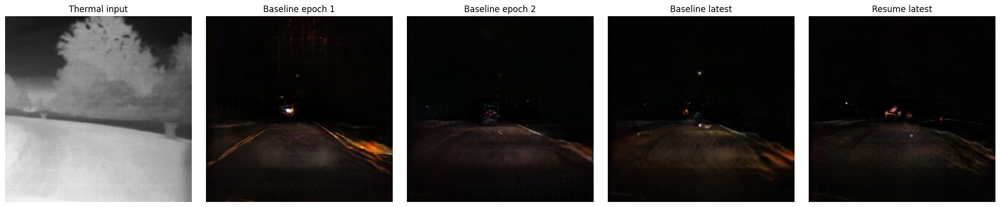


Checkpoint comparison completed.
No training was performed.


In [ ]:

from pathlib import Path
import sys
import subprocess
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

base = Path("/content/drive/MyDrive/MP1_Thermal_RGB")
repo = Path("/content/pytorch-CycleGAN-and-pix2pix")

if not repo.exists():
    result = subprocess.run(
        ["git", "clone", "--depth", "1",
         "https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix.git",
         str(repo)],
        capture_output=True, text=True
    )
    if result.returncode != 0:
        raise RuntimeError(result.stderr[-2000:])

sys.path.insert(0, str(repo))
from models import networks

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

checkpoint_paths = {
    "Baseline epoch 1": base / "checkpoints/TRI2I_Thermal_RGB_baseline/1_net_G.pth",
    "Baseline epoch 2": base / "checkpoints/TRI2I_Thermal_RGB_baseline/2_net_G.pth",
    "Baseline latest": base / "checkpoints/TRI2I_Thermal_RGB_baseline/latest_net_G.pth",
    "Resume latest": base / "checkpoints/TRI2I_Thermal_RGB_resume_v1/latest_net_G.pth",
}

review_dir = Path("/content/TRI2I_visual_review")
filenames = [
    "51427.jpg", "33940.jpg", "39368.jpg",
    "93206.jpg", "93198.jpg", "102972.jpg"
]

def to_tensor(path):
    image = Image.open(path).convert("RGB").resize((256, 256))
    arr = np.asarray(image, dtype=np.float32) / 127.5 - 1
    return torch.from_numpy(arr).permute(2, 0, 1).unsqueeze(0)

def to_image(tensor):
    arr = tensor.squeeze(0).detach().cpu().permute(1, 2, 0).numpy()
    arr = ((arr + 1) * 127.5).clip(0, 255).astype(np.uint8)
    return Image.fromarray(arr)

# Load each checkpoint in turn to avoid keeping four large models in memory.
results = {}
for label, path in checkpoint_paths.items():
    print("Evaluating:", label)
    if not path.exists():
        print("  MISSING:", path)
        continue

    netG = networks.define_G(
        input_nc=3, output_nc=3, ngf=64,
        netG="unet_256", norm="batch",
        use_dropout=True, init_type="normal", init_gain=0.02
    )
    state = torch.load(path, map_location="cpu", weights_only=True)
    netG.load_state_dict(state, strict=True)
    netG.to(device).eval()

    results[label] = {}
    with torch.inference_mode():
        for name in filenames:
            x = to_tensor(review_dir / "Thermal" / name).to(device)
            results[label][name] = to_image(netG(x))

    del netG, state
    if device.type == "cuda":
        torch.cuda.empty_cache()

# Show all checkpoint outputs for the first image as a quick visual comparison.
name = "102972.jpg"
fig, axes = plt.subplots(1, 1 + len(results), figsize=(4 * (1 + len(results)), 4))
axes[0].imshow(Image.open(review_dir / "Thermal" / name).convert("RGB"))
axes[0].set_title("Thermal input")
axes[0].axis("off")

for ax, (label, outputs) in zip(axes[1:], results.items()):
    ax.imshow(outputs[name])
    ax.set_title(label)
    ax.axis("off")

plt.tight_layout()
plt.show()

print("\nCheckpoint comparison completed.")
print("No training was performed.")


In [ ]:

from pathlib import Path

base = Path("/content/drive/MyDrive/MP1_Thermal_RGB")

paths = {
    "Test thermal images": Path("/content/TRI2I_split/test/A"),
    "Test RGB images": Path("/content/TRI2I_split/test/B"),
    "Existing test metrics": base / "evaluation/TRI2I_Thermal_RGB_test_metrics.csv",
}

for label, path in paths.items():
    print(f"\n{label}: {path}")
    print("Exists:", path.exists())

    if path.is_dir():
        print("Image count:", len(list(path.glob("*.jpg"))))
    elif path.is_file():
        print("Size:", round(path.stat().st_size / (1024 * 1024), 2), "MB")



Test thermal images: /content/TRI2I_split/test/A
Exists: False

Test RGB images: /content/TRI2I_split/test/B
Exists: False

Existing test metrics: /content/drive/MyDrive/MP1_Thermal_RGB/evaluation/TRI2I_Thermal_RGB_test_metrics.csv
Exists: True
Size: 0.61 MB


In [ ]:

from pathlib import Path
import json

manifest = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/tri2i_split_seed42.json"
)
dataset_zip = Path("/content/drive/MyDrive/dataset_1-6-2024.zip")

print("Split manifest exists:", manifest.exists())
print("Dataset ZIP exists:", dataset_zip.exists())

if manifest.exists():
    print("Manifest size:", round(manifest.stat().st_size / 1024, 2), "KB")
    data = json.loads(manifest.read_text())
    print("Manifest type:", type(data).__name__)

    if isinstance(data, dict):
        print("Top-level keys:", list(data.keys())[:20])
        print("Manifest preview:")
        print(str(data)[:1200])
    elif isinstance(data, list):
        print("Number of entries:", len(data))
        print("First entry:", data[0] if data else "Empty")


Split manifest exists: True
Dataset ZIP exists: True
Manifest size: 2512.69 KB
Manifest type: dict
Top-level keys: ['seed', 'train', 'val', 'test']
Manifest preview:
{'seed': 42, 'train': ['43962.jpg', '76448.jpg', '16379.jpg', '73788.jpg', '99587.jpg', '127738.jpg', '2805.jpg', '64414.jpg', '5970.jpg', '102060.jpg', '66118.jpg', '61359.jpg', '8956.jpg', '70698.jpg', '48135.jpg', '103839.jpg', '107975.jpg', '19040.jpg', '102032.jpg', '123142.jpg', '24797.jpg', '48494.jpg', '34976.jpg', '8260.jpg', '22692.jpg', '30562.jpg', '29193.jpg', '131502.jpg', '111250.jpg', '10077.jpg', '117954.jpg', '144213.jpg', '101055.jpg', '49790.jpg', '113415.jpg', '65222.jpg', '119797.jpg', '147187.jpg', '13475.jpg', '10227.jpg', '13517.jpg', '40689.jpg', '122609.jpg', '96575.jpg', '71235.jpg', '23127.jpg', '112326.jpg', '48131.jpg', '45048.jpg', '64175.jpg', '45524.jpg', '26059.jpg', '138471.jpg', '142747.jpg', '102141.jpg', '6029.jpg', '15515.jpg', '34184.jpg', '10293.jpg', '115310.jpg', '102661.jpg', '1

In [ ]:

from pathlib import Path
import json
import zipfile

manifest_path = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/tri2i_split_seed42.json"
)
zip_path = Path("/content/drive/MyDrive/dataset_1-6-2024.zip")
test_root = Path("/content/TRI2I_split/test")

manifest = json.loads(manifest_path.read_text())
test_names = manifest["test"]

assert len(test_names) == 14884, (
    f"Expected 14884 test images, found {len(test_names)}"
)
assert zip_path.exists(), "Original dataset ZIP not found"

# Build an exact lookup for files in the ZIP.
with zipfile.ZipFile(zip_path, "r") as z:
    members = z.namelist()
    lookup = {}

    for member in members:
        normalized = member.replace("\\", "/")
        parts = normalized.strip("/").split("/")
        if len(parts) < 2:
            continue

        class_name = parts[-2]
        filename = parts[-1]

        if class_name in ("class1", "class2") and filename.endswith(".jpg"):
            key = (class_name, filename)
            if key in lookup:
                raise RuntimeError(f"Duplicate ZIP entry for {key}")
            lookup[key] = member

    missing = [
        (class_name, name)
        for name in test_names
        for class_name in ("class1", "class2")
        if (class_name, name) not in lookup
    ]
    if missing:
        raise RuntimeError(
            f"{len(missing)} required ZIP entries are missing. "
            f"Examples: {missing[:10]}"
        )

    # Extract thermal to A and RGB to B, matching Pix2Pix AtoB setup.
    for folder in ("A", "B"):
        (test_root / folder).mkdir(parents=True, exist_ok=True)

    for i, name in enumerate(test_names, start=1):
        thermal_dest = test_root / "A" / name
        rgb_dest = test_root / "B" / name

        if not thermal_dest.exists():
            thermal_dest.write_bytes(z.read(lookup[("class2", name)]))
        if not rgb_dest.exists():
            rgb_dest.write_bytes(z.read(lookup[("class1", name)]))

        if i % 2000 == 0:
            print(f"Restored {i}/{len(test_names)} pairs")

# Verify the restored split.
thermal_files = {p.name for p in (test_root / "A").glob("*.jpg")}
rgb_files = {p.name for p in (test_root / "B").glob("*.jpg")}

assert len(thermal_files) == len(test_names), (
    f"Thermal count mismatch: {len(thermal_files)}"
)
assert len(rgb_files) == len(test_names), (
    f"RGB count mismatch: {len(rgb_files)}"
)
assert thermal_files == set(test_names)
assert rgb_files == set(test_names)

print("\nSUCCESS: Original test split restored.")
print("Thermal images:", len(thermal_files))
print("RGB images:", len(rgb_files))
print("Matching filenames: all verified")
print("Test folder:", test_root)


Restored 2000/14884 pairs
Restored 4000/14884 pairs
Restored 6000/14884 pairs
Restored 8000/14884 pairs
Restored 10000/14884 pairs
Restored 12000/14884 pairs
Restored 14000/14884 pairs

SUCCESS: Original test split restored.
Thermal images: 14884
RGB images: 14884
Matching filenames: all verified
Test folder: /content/TRI2I_split/test


In [ ]:

from pathlib import Path
import json
import zipfile

manifest_path = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/tri2i_split_seed42.json"
)
zip_path = Path("/content/drive/MyDrive/dataset_1-6-2024.zip")
val_root = Path("/content/TRI2I_split/val")

manifest = json.loads(manifest_path.read_text())
val_names = manifest["val"]

assert len(val_names) == 14882, f"Unexpected validation count: {len(val_names)}"

with zipfile.ZipFile(zip_path, "r") as z:
    lookup = {}

    for member in z.namelist():
        normalized = member.replace("\\", "/")
        parts = normalized.strip("/").split("/")
        if len(parts) >= 2 and parts[-2] in ("class1", "class2"):
            key = (parts[-2], parts[-1])
            if key in lookup:
                raise RuntimeError(f"Duplicate archive entry: {key}")
            lookup[key] = member

    missing = [
        (cls, name)
        for name in val_names
        for cls in ("class1", "class2")
        if (cls, name) not in lookup
    ]
    if missing:
        raise RuntimeError(f"Missing entries: {missing[:10]}")

    for folder in ("A", "B"):
        (val_root / folder).mkdir(parents=True, exist_ok=True)

    for i, name in enumerate(val_names, start=1):
        # Pix2Pix AtoB: A = thermal, B = RGB
        for cls, folder in (("class2", "A"), ("class1", "B")):
            dest = val_root / folder / name
            if not dest.exists():
                dest.write_bytes(z.read(lookup[(cls, name)]))

        if i % 2000 == 0:
            print(f"Restored {i}/{len(val_names)} validation pairs")

thermal = {p.name for p in (val_root / "A").glob("*.jpg")}
rgb = {p.name for p in (val_root / "B").glob("*.jpg")}

assert thermal == set(val_names)
assert rgb == set(val_names)

print("\nSUCCESS: Validation split restored.")
print("Thermal:", len(thermal))
print("RGB:", len(rgb))
print("Matching filenames: all verified")


Restored 2000/14882 validation pairs
Restored 4000/14882 validation pairs
Restored 6000/14882 validation pairs
Restored 8000/14882 validation pairs
Restored 10000/14882 validation pairs
Restored 12000/14882 validation pairs
Restored 14000/14882 validation pairs

SUCCESS: Validation split restored.
Thermal: 14882
RGB: 14882
Matching filenames: all verified


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:

from pathlib import Path

paths = [
    Path("/content/TRI2I_split/val"),
    Path("/content/TRI2I_split/val/A"),
    Path("/content/TRI2I_split/val/B"),
    Path("/content/drive/MyDrive/MP1_Thermal_RGB/tri2i_split_seed42.json"),
    Path("/content/drive/MyDrive/dataset_1-6-2024.zip"),
]

for path in paths:
    print(f"\n{path}")
    print("Exists:", path.exists())

    if path.is_dir():
        files = list(path.glob("*.jpg"))
        print("JPG files directly inside:", len(files))
        print("First few:", [p.name for p in files[:5]])
    elif path.is_file():
        print("Size:", round(path.stat().st_size / (1024 * 1024), 2), "MB")



/content/TRI2I_split/val
Exists: False

/content/TRI2I_split/val/A
Exists: False

/content/TRI2I_split/val/B
Exists: False

/content/drive/MyDrive/MP1_Thermal_RGB/tri2i_split_seed42.json
Exists: True
Size: 2.45 MB

/content/drive/MyDrive/dataset_1-6-2024.zip
Exists: True
Size: 5570.17 MB


In [ ]:

from pathlib import Path
import json
import zipfile

manifest_path = Path(
    "/content/drive/MyDrive/MP1_Thermal_RGB/tri2i_split_seed42.json"
)
zip_path = Path("/content/drive/MyDrive/dataset_1-6-2024.zip")
val_root = Path("/content/TRI2I_split/val")

manifest = json.loads(manifest_path.read_text())
val_names = manifest["val"]

assert len(val_names) == 14882, f"Unexpected validation size: {len(val_names)}"

# Index the archive by class and filename.
with zipfile.ZipFile(zip_path, "r") as z:
    lookup = {}
    for member in z.namelist():
        normalized = member.replace("\\", "/")
        parts = normalized.strip("/").split("/")
        if len(parts) >= 2 and parts[-2] in ("class1", "class2"):
            key = (parts[-2], parts[-1])
            if key in lookup:
                raise RuntimeError(f"Duplicate archive entry: {key}")
            lookup[key] = member

    missing = [
        (cls, name)
        for name in val_names
        for cls in ("class1", "class2")
        if (cls, name) not in lookup
    ]
    assert not missing, f"Missing archive entries: {missing[:10]}"

    (val_root / "A").mkdir(parents=True, exist_ok=True)
    (val_root / "B").mkdir(parents=True, exist_ok=True)

    for i, name in enumerate(val_names, start=1):
        # A = thermal (class2); B = RGB (class1)
        for cls, folder in [("class2", "A"), ("class1", "B")]:
            dest = val_root / folder / name
            if not dest.exists():
                dest.write_bytes(z.read(lookup[(cls, name)]))

        if i % 2000 == 0:
            print(f"Restored {i}/{len(val_names)} pairs")

# Verify counts and filenames immediately.
thermal = {p.name for p in (val_root / "A").glob("*.jpg")}
rgb = {p.name for p in (val_root / "B").glob("*.jpg")}

print("\nValidation thermal count:", len(thermal))
print("Validation RGB count:", len(rgb))
print("Filename sets match:", thermal == rgb == set(val_names))
print("Validation directory exists:", val_root.exists())

assert len(thermal) == 14882
assert len(rgb) == 14882
assert thermal == rgb == set(val_names)

print("\nSUCCESS: Validation split restored and verified.")


Restored 2000/14882 pairs
Restored 4000/14882 pairs
Restored 6000/14882 pairs
Restored 8000/14882 pairs
Restored 10000/14882 pairs
Restored 12000/14882 pairs
Restored 14000/14882 pairs

Validation thermal count: 14882
Validation RGB count: 14882
Filename sets match: True
Validation directory exists: True

SUCCESS: Validation split restored and verified.


In [ ]:

from pathlib import Path
import sys
import subprocess
import gc
import numpy as np
import pandas as pd
import torch
from PIL import Image
from skimage.metrics import structural_similarity

# --------------------------------------------------
# 1. Paths and validation data checks
# --------------------------------------------------
base = Path("/content/drive/MyDrive/MP1_Thermal_RGB")
val_root = Path("/content/TRI2I_split/val")
output_dir = base / "evaluation"
output_dir.mkdir(parents=True, exist_ok=True)

a_dir = val_root / "A"  # Thermal
b_dir = val_root / "B"  # Ground-truth RGB

thermal_names = {p.name for p in a_dir.glob("*.jpg")}
rgb_names = {p.name for p in b_dir.glob("*.jpg")}

assert len(thermal_names) == 14882, (
    f"Expected 14882 thermal images, found {len(thermal_names)}"
)
assert len(rgb_names) == 14882, (
    f"Expected 14882 RGB images, found {len(rgb_names)}"
)
assert thermal_names == rgb_names, "Thermal/RGB filenames do not match"

print("Validation pairs verified:", len(thermal_names))

# --------------------------------------------------
# 2. Prepare official Pix2Pix architecture
# --------------------------------------------------
repo = Path("/content/pytorch-CycleGAN-and-pix2pix")

if not repo.exists():
    result = subprocess.run(
        [
            "git", "clone", "--depth", "1",
            "https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix.git",
            str(repo)
        ],
        capture_output=True,
        text=True
    )
    if result.returncode != 0:
        raise RuntimeError(
            "Could not obtain Pix2Pix code:\n" + result.stderr[-2000:]
        )

if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))

from models import networks

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

if device.type != "cuda":
    raise RuntimeError(
        "GPU is not available in this runtime. Stop here; do not run "
        "the full evaluation on CPU."
    )

# --------------------------------------------------
# 3. Define the four saved generator checkpoints
# --------------------------------------------------
checkpoints = {
    "baseline_epoch1":
        base / "checkpoints/TRI2I_Thermal_RGB_baseline/1_net_G.pth",

    "baseline_epoch2":
        base / "checkpoints/TRI2I_Thermal_RGB_baseline/2_net_G.pth",

    "baseline_latest":
        base / "checkpoints/TRI2I_Thermal_RGB_baseline/latest_net_G.pth",

    "resume_latest":
        base / "checkpoints/TRI2I_Thermal_RGB_resume_v1/latest_net_G.pth",
}

for label, path in checkpoints.items():
    assert path.exists(), f"Checkpoint missing: {path}"
    print(f"Found {label}: {path.name}")

names = sorted(thermal_names)

# --------------------------------------------------
# 4. Image conversion and metrics
# --------------------------------------------------
def load_image(path):
    with Image.open(path) as im:
        im = im.convert("RGB").resize((256, 256))
        return np.asarray(im, dtype=np.float32) / 255.0

def image_to_tensor(arr):
    # Convert [0,1] to [-1,1], then HWC to NCHW.
    return (
        torch.from_numpy(arr * 2.0 - 1.0)
        .permute(2, 0, 1)
        .unsqueeze(0)
    )

def tensor_to_array(tensor):
    arr = tensor.squeeze(0).detach().cpu().permute(1, 2, 0).numpy()
    return ((arr + 1.0) / 2.0).clip(0.0, 1.0)

def calculate_metrics(pred, target):
    mae = float(np.mean(np.abs(pred - target)))
    mse = float(np.mean((pred - target) ** 2))

    psnr = (
        float("inf") if mse == 0
        else float(10.0 * np.log10(1.0 / mse))
    )

    ssim = float(
        structural_similarity(
            target, pred, channel_axis=2, data_range=1.0
        )
    )

    return mae, psnr, ssim

# --------------------------------------------------
# 5. Evaluate each checkpoint
# --------------------------------------------------
summary_rows = []

for label, checkpoint in checkpoints.items():
    print(f"\n===== Evaluating {label} =====")

    netG = networks.define_G(
        input_nc=3,
        output_nc=3,
        ngf=64,
        netG="unet_256",
        norm="batch",
        use_dropout=True,
        init_type="normal",
        init_gain=0.02
    )

    state = torch.load(
        checkpoint,
        map_location="cpu",
        weights_only=True
    )
    netG.load_state_dict(state, strict=True)
    del state

    netG.to(device)
    netG.eval()

    rows = []

    with torch.inference_mode():
        for i, name in enumerate(names, start=1):
            thermal = image_to_tensor(
                load_image(a_dir / name)
            ).to(device)

            target = load_image(b_dir / name)
            prediction = tensor_to_array(netG(thermal))

            mae, psnr, ssim = calculate_metrics(prediction, target)

            rows.append({
                "filename": name,
                "MAE": mae,
                "PSNR_dB": psnr,
                "SSIM": ssim
            })

            if i % 1000 == 0:
                print(f"Processed {i}/{len(names)} images")

    # Save individual per-image results.
    detail_path = output_dir / f"validation_{label}_metrics.csv"
    pd.DataFrame(rows).to_csv(detail_path, index=False)

    summary_rows.append({
        "checkpoint": label,
        "MAE_mean": float(np.mean([r["MAE"] for r in rows])),
        "PSNR_mean_dB": float(np.mean([r["PSNR_dB"] for r in rows])),
        "SSIM_mean": float(np.mean([r["SSIM"] for r in rows])),
        "images_evaluated": len(rows),
        "metrics_file": str(detail_path)
    })

    print("Saved per-image metrics:", detail_path)

    del netG, rows
    gc.collect()
    torch.cuda.empty_cache()

# --------------------------------------------------
# 6. Save and display comparison table
# --------------------------------------------------
summary = pd.DataFrame(summary_rows)

summary_path = (
    output_dir / "TRI2I_checkpoint_validation_comparison.csv"
)
summary.to_csv(summary_path, index=False)

print("\n" + "=" * 60)
print("VALIDATION COMPARISON")
print("=" * 60)
print(
    summary[
        [
            "checkpoint",
            "MAE_mean",
            "PSNR_mean_dB",
            "SSIM_mean",
            "images_evaluated"
        ]
    ].to_string(index=False, float_format=lambda x: f"{x:.6f}")
)

print("\nComparison saved to:")
print(summary_path)
print("\nAll four checkpoints evaluated. No training was performed.")


Validation pairs verified: 14882
Device: cuda
Found baseline_epoch1: 1_net_G.pth
Found baseline_epoch2: 2_net_G.pth
Found baseline_latest: latest_net_G.pth
Found resume_latest: latest_net_G.pth

===== Evaluating baseline_epoch1 =====
Processed 1000/14882 images
Processed 2000/14882 images
Processed 3000/14882 images
Processed 4000/14882 images
Processed 5000/14882 images
Processed 6000/14882 images
Processed 7000/14882 images
Processed 8000/14882 images
Processed 9000/14882 images
Processed 10000/14882 images
Processed 11000/14882 images
Processed 12000/14882 images
Processed 13000/14882 images
Processed 14000/14882 images
Saved per-image metrics: /content/drive/MyDrive/MP1_Thermal_RGB/evaluation/validation_baseline_epoch1_metrics.csv

===== Evaluating baseline_epoch2 =====
Processed 1000/14882 images
Processed 2000/14882 images
Processed 3000/14882 images
Processed 4000/14882 images
Processed 5000/14882 images
Processed 6000/14882 images
Processed 7000/14882 images
Processed 8000/1488

Selected validation images:
39350.jpg: SSIM=0.1002
39417.jpg: SSIM=0.1065
39357.jpg: SSIM=0.1095
93085.jpg: SSIM=0.8056
102968.jpg: SSIM=0.8060
102970.jpg: SSIM=0.8098


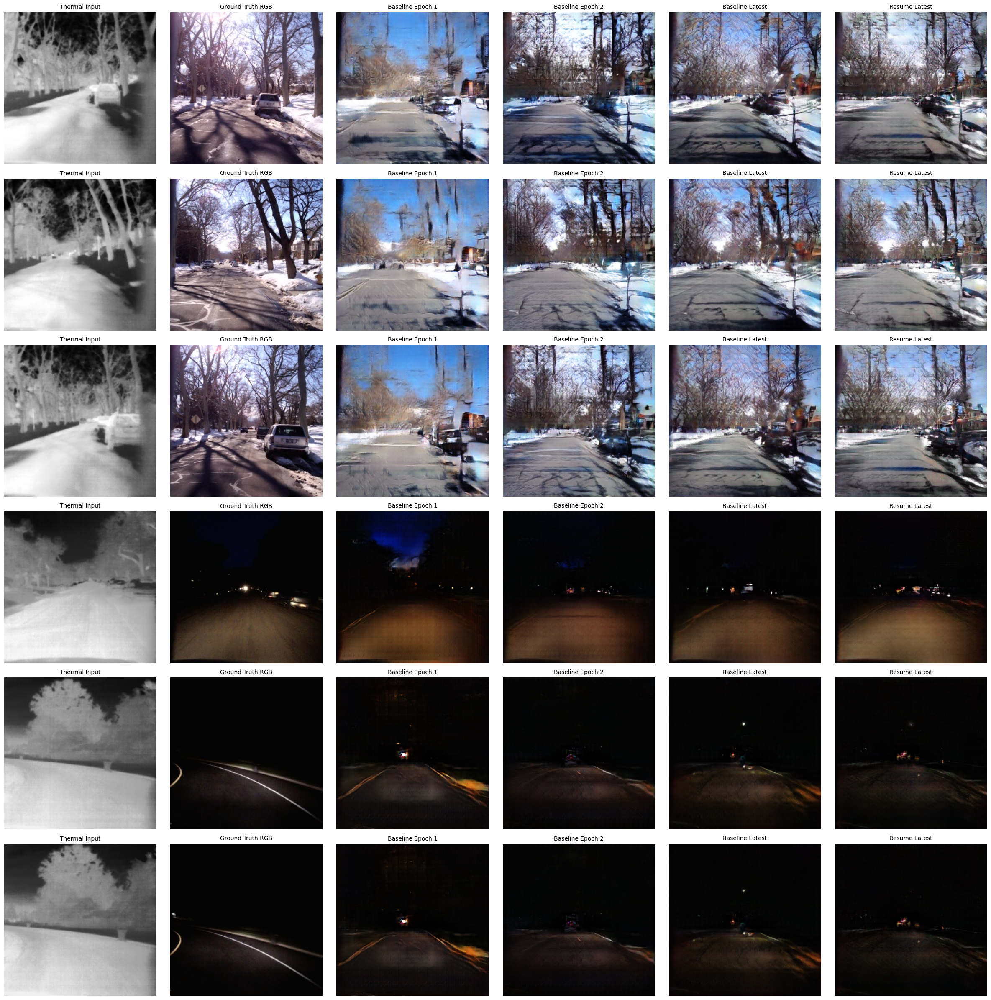

Visual comparison completed. No training was performed.


In [ ]:

import os
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image

# Use the existing validation folders
thermal_dir = "/content/TRI2I_split/val/A"
rgb_dir = "/content/TRI2I_split/val/B"

# Use the validation metrics generated earlier
metrics_path = (
    "/content/drive/MyDrive/MP1_Thermal_RGB/evaluation/"
    "validation_resume_latest_metrics.csv"
)

assert os.path.isfile(metrics_path), (
    f"Metrics CSV not found: {metrics_path}"
)
assert os.path.isdir(thermal_dir), f"Missing folder: {thermal_dir}"
assert os.path.isdir(rgb_dir), f"Missing folder: {rgb_dir}"

df = pd.read_csv(metrics_path)

# Check the required columns
required = {"filename", "SSIM"}
assert required.issubset(df.columns), (
    f"Expected columns {required}; found {list(df.columns)}"
)

# Keep only images that exist in BOTH validation folders
available = (
    set(os.listdir(thermal_dir))
    & set(os.listdir(rgb_dir))
    & set(df["filename"].astype(str))
)

df = df[df["filename"].astype(str).isin(available)].copy()
assert len(df) >= 6, f"Only {len(df)} matching images found."

# Select three lower-SSIM and three higher-SSIM validation examples
df = df.sort_values("SSIM")
low_names = df.head(3)["filename"].astype(str).tolist()
high_names = df.tail(3)["filename"].astype(str).tolist()
IMAGE_NAMES = low_names + high_names

print("Selected validation images:")
for filename in IMAGE_NAMES:
    score = df.loc[df["filename"].astype(str) == filename, "SSIM"].iloc[0]
    print(f"{filename}: SSIM={score:.4f}")

# Confirm the previously loaded generators are available
assert "models_loaded" in globals(), (
    "Generators are not loaded. Tell me before rerunning the loading cell."
)

column_names = [
    "Thermal Input",
    "Ground Truth RGB",
    "Baseline Epoch 1",
    "Baseline Epoch 2",
    "Baseline Latest",
    "Resume Latest",
]

fig, axes = plt.subplots(
    len(IMAGE_NAMES), len(column_names),
    figsize=(24, 4 * len(IMAGE_NAMES))
)

with torch.inference_mode():
    for row, filename in enumerate(IMAGE_NAMES):
        thermal = Image.open(
            os.path.join(thermal_dir, filename)
        ).convert("RGB").resize((256, 256))

        ground_truth = Image.open(
            os.path.join(rgb_dir, filename)
        ).convert("RGB").resize((256, 256))

        arr = np.asarray(thermal, dtype=np.float32) / 127.5 - 1.0
        tensor = torch.from_numpy(
            arr.transpose(2, 0, 1).copy()
        ).unsqueeze(0).to(device)

        axes[row, 0].imshow(thermal)
        axes[row, 1].imshow(ground_truth)

        for col, (model_name, netG) in enumerate(
            models_loaded.items(), start=2
        ):
            pred = netG(tensor)[0].detach().cpu().float()
            pred = (
                pred.clamp(-1, 1)
                .add(1).div(2)
                .permute(1, 2, 0).numpy()
            )
            axes[row, col].imshow(pred)

        for col, title in enumerate(column_names):
            axes[row, col].set_title(title, fontsize=10)
            axes[row, col].axis("off")

        axes[row, 0].set_ylabel(filename, fontsize=9)

plt.tight_layout()
plt.show()

print("Visual comparison completed. No training was performed.")


In [ ]:

import os
import json
import zipfile

ZIP_PATH = "/content/drive/MyDrive/dataset_1-6-2024.zip"
MANIFEST_PATH = (
    "/content/drive/MyDrive/MP1_Thermal_RGB/tri2i_split_seed42.json"
)

print("ZIP exists:", os.path.isfile(ZIP_PATH))
print("Manifest exists:", os.path.isfile(MANIFEST_PATH))

assert os.path.isfile(ZIP_PATH), (
    "Original dataset ZIP not found. Check that Google Drive is mounted."
)
assert os.path.isfile(MANIFEST_PATH), (
    "Seed-42 manifest not found. Do not create a new random split."
)

# Inspect manifest without modifying it
with open(MANIFEST_PATH, "r") as f:
    manifest = json.load(f)

print("\nManifest type:", type(manifest).__name__)

if isinstance(manifest, dict):
    print("Manifest keys:", list(manifest.keys()))
    for key, value in manifest.items():
        if isinstance(value, list):
            print(f"{key}: {len(value)} items; sample:", value[:3])
        elif isinstance(value, dict):
            print(f"{key}: dictionary keys:", list(value.keys())[:10])
        else:
            print(f"{key}:", repr(value)[:200])
elif isinstance(manifest, list):
    print("Manifest length:", len(manifest))
    print("First entries:", manifest[:3])

# Inspect ZIP paths only; do not extract the entire dataset
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    names = z.namelist()
    print("\nZIP entries:", len(names))
    image_names = [
        n for n in names
        if n.lower().endswith((".jpg", ".jpeg", ".png"))
    ]
    print("Image entries:", len(image_names))
    print("Example image paths:")
    for name in image_names[:10]:
        print(name)

print("\nDiagnostic completed. No files were changed.")


ZIP exists: True
Manifest exists: True

Manifest type: dict
Manifest keys: ['seed', 'train', 'val', 'test']
seed: 42
train: 119063 items; sample: ['43962.jpg', '76448.jpg', '16379.jpg']
val: 14882 items; sample: ['140787.jpg', '139475.jpg', '49647.jpg']
test: 14884 items; sample: ['86122.jpg', '105881.jpg', '114271.jpg']

ZIP entries: 297660
Image entries: 297658
Example image paths:
dataset_1-6-2024/class1/10000.jpg
dataset_1-6-2024/class1/100000.jpg
dataset_1-6-2024/class1/100001.jpg
dataset_1-6-2024/class1/100002.jpg
dataset_1-6-2024/class1/100003.jpg
dataset_1-6-2024/class1/100004.jpg
dataset_1-6-2024/class1/100005.jpg
dataset_1-6-2024/class1/100006.jpg
dataset_1-6-2024/class1/100007.jpg
dataset_1-6-2024/class1/100008.jpg

Diagnostic completed. No files were changed.


In [ ]:

import os
import json
import zipfile
from PIL import Image
from io import BytesIO

ZIP_PATH = "/content/drive/MyDrive/dataset_1-6-2024.zip"
MANIFEST_PATH = (
    "/content/drive/MyDrive/MP1_Thermal_RGB/tri2i_split_seed42.json"
)

TEST_ROOT = "/content/TRI2I_split/test"
THERMAL_DIR = os.path.join(TEST_ROOT, "A")
RGB_DIR = os.path.join(TEST_ROOT, "B")

os.makedirs(THERMAL_DIR, exist_ok=True)
os.makedirs(RGB_DIR, exist_ok=True)

with open(MANIFEST_PATH, "r") as f:
    manifest = json.load(f)

test_names = manifest["test"]
assert len(test_names) == 14884, (
    f"Unexpected test count: {len(test_names)}"
)

# Extract only the filenames assigned to the original test split.
wanted = set(test_names)
found = {"class1": set(), "class2": set()}

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    for member in z.namelist():
        if not member.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        parts = member.split("/")
        if len(parts) < 3:
            continue

        category = parts[-2]
        filename = parts[-1]

        if category not in ("class1", "class2") or filename not in wanted:
            continue

        if filename in found[category]:
            raise RuntimeError(
                f"Duplicate filename in {category}: {filename}"
            )

        # Dataset convention verified previously:
        # class1 = RGB, class2 = Thermal.
        destination = (
            os.path.join(RGB_DIR, filename)
            if category == "class1"
            else os.path.join(THERMAL_DIR, filename)
        )

        with z.open(member) as source:
            image = Image.open(BytesIO(source.read())).convert("RGB")
            image.save(destination, format="JPEG", quality=95)

        found[category].add(filename)

    missing_rgb = wanted - found["class1"]
    missing_thermal = wanted - found["class2"]

    assert not missing_rgb, (
        f"Missing RGB images: {len(missing_rgb)}; "
        f"examples: {list(missing_rgb)[:5]}"
    )
    assert not missing_thermal, (
        f"Missing thermal images: {len(missing_thermal)}; "
        f"examples: {list(missing_thermal)[:5]}"
    )

# Verify restored folders and matching filenames.
rgb_files = set(os.listdir(RGB_DIR))
thermal_files = set(os.listdir(THERMAL_DIR))

assert rgb_files == wanted, (
    f"RGB folder count/set mismatch: {len(rgb_files)}"
)
assert thermal_files == wanted, (
    f"Thermal folder count/set mismatch: {len(thermal_files)}"
)
assert rgb_files == thermal_files

print("SUCCESS: Original test split restored.")
print("Seed:", manifest["seed"])
print("Thermal images:", len(thermal_files))
print("RGB images:", len(rgb_files))
print("Matching filenames:", len(rgb_files & thermal_files))
print("Thermal folder:", THERMAL_DIR)
print("RGB folder:", RGB_DIR)


SUCCESS: Original test split restored.
Seed: 42
Thermal images: 14884
RGB images: 14884
Matching filenames: 14884
Thermal folder: /content/TRI2I_split/test/A
RGB folder: /content/TRI2I_split/test/B


In [ ]:

# FINAL TEST EVALUATION — BASELINE LATEST
# Evaluation only; no training.

import os
import sys
import numpy as np
import pandas as pd
import torch
from PIL import Image
from skimage.metrics import structural_similarity, peak_signal_noise_ratio
from torch.utils.data import Dataset, DataLoader

DRIVE = "/content/drive/MyDrive/MP1_Thermal_RGB"
TEST = "/content/TRI2I_split/test"
REPO = "/content/pytorch-CycleGAN-and-pix2pix"

CHECKPOINT = os.path.join(
    DRIVE, "checkpoints/TRI2I_Thermal_RGB_baseline/latest_net_G.pth"
)
OUT = os.path.join(DRIVE, "evaluation")

assert torch.cuda.is_available(), "GPU unavailable. Stop and report this."
assert os.path.isfile(CHECKPOINT), f"Checkpoint missing: {CHECKPOINT}"
assert os.path.isdir(REPO), f"Pix2Pix repository missing: {REPO}"

A = os.path.join(TEST, "A")  # Thermal
B = os.path.join(TEST, "B")  # Ground-truth RGB

assert os.path.isdir(A) and os.path.isdir(B), "Test folders missing."

thermal_names = {
    f for f in os.listdir(A)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
}
rgb_names = {
    f for f in os.listdir(B)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
}

assert thermal_names == rgb_names, "Test filenames do not match."
filenames = sorted(thermal_names)
assert len(filenames) == 14884, (
    f"Expected 14884 test pairs, found {len(filenames)}"
)

if REPO not in sys.path:
    sys.path.insert(0, REPO)
from models import networks

print("Test pairs:", len(filenames))
print("GPU:", torch.cuda.get_device_name(0))

class TestDataset(Dataset):
    def __len__(self):
        return len(filenames)

    def __getitem__(self, index):
        name = filenames[index]
        thermal = Image.open(os.path.join(A, name)).convert("RGB")
        rgb = Image.open(os.path.join(B, name)).convert("RGB")

        thermal = thermal.resize((256, 256))
        rgb = rgb.resize((256, 256))

        x = np.asarray(thermal, dtype=np.float32) / 127.5 - 1.0
        y = np.asarray(rgb, dtype=np.float32) / 255.0

        return (
            torch.from_numpy(x.transpose(2, 0, 1).copy()),
            torch.from_numpy(y.transpose(2, 0, 1).copy()),
            name
        )

loader = DataLoader(
    TestDataset(), batch_size=16, shuffle=False, num_workers=2
)
device = torch.device("cuda")

netG = networks.define_G(
    input_nc=3,
    output_nc=3,
    ngf=64,
    netG="unet_256",
    norm="batch",
    use_dropout=True,
    init_type="normal",
    init_gain=0.02
).to(device)

state = torch.load(CHECKPOINT, map_location="cpu", weights_only=True)
netG.load_state_dict(state, strict=True)
netG.eval()

results = []

with torch.inference_mode():
    for batch_idx, (x, y, names) in enumerate(loader):
        pred = (
            netG(x.to(device))
            .clamp(-1, 1).add(1).div(2)
            .cpu().numpy()
        )
        target = y.numpy()

        for i, name in enumerate(names):
            p = np.clip(pred[i].transpose(1, 2, 0), 0, 1)
            t = target[i].transpose(1, 2, 0)

            results.append({
                "filename": name,
                "MAE": float(np.mean(np.abs(p - t))),
                "PSNR_dB": float(
                    peak_signal_noise_ratio(t, p, data_range=1.0)
                ),
                "SSIM": float(
                    structural_similarity(
                        t, p, channel_axis=2, data_range=1.0
                    )
                )
            })

        processed = min((batch_idx + 1) * 16, len(filenames))
        if processed % 1000 < 16 or processed == len(filenames):
            print(f"Processed {processed}/{len(filenames)}")

df = pd.DataFrame(results)

assert len(df) == 14884
assert np.isfinite(df[["MAE", "PSNR_dB", "SSIM"]].to_numpy()).all()

os.makedirs(OUT, exist_ok=True)

csv_path = os.path.join(
    OUT, "TRI2I_Baseline_Latest_FINAL_test_metrics.csv"
)
summary_path = os.path.join(
    OUT, "TRI2I_Baseline_Latest_FINAL_test_summary.txt"
)

df.to_csv(csv_path, index=False)

summary = (
    "Checkpoint: Baseline Latest\n"
    f"Test images: {len(df)}\n"
    f"Mean MAE: {df['MAE'].mean():.6f}\n"
    f"Mean PSNR: {df['PSNR_dB'].mean():.6f} dB\n"
    f"Mean SSIM: {df['SSIM'].mean():.6f}\n"
)

with open(summary_path, "w") as f:
    f.write(summary)

print("\n===== FINAL TEST RESULTS =====")
print(summary)
print("Metrics CSV:", csv_path)
print("Summary:", summary_path)
print("SUCCESS: Evaluation completed. No training was performed.")


AssertionError: GPU unavailable. Stop and report this.

In [ ]:

from google.colab import drive
drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [ ]:

from google.colab import drive
drive.mount("/content/drive")

import os
import torch

print("\n--- Project File Check ---")

paths = {
    "Dataset ZIP": "/content/drive/MyDrive/dataset_1-6-2024.zip",
    "Split manifest": "/content/drive/MyDrive/MP1_Thermal_RGB/tri2i_split_seed42.json",
    "Baseline Latest checkpoint": (
        "/content/drive/MyDrive/MP1_Thermal_RGB/checkpoints/"
        "TRI2I_Thermal_RGB_baseline/latest_net_G.pth"
    ),
}

for name, path in paths.items():
    print(f"{name}: {'FOUND' if os.path.isfile(path) else 'MISSING'}")

print("\n--- Runtime Check ---")
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\nTest thermal folder exists:",
      os.path.isdir("/content/TRI2I_split/test/A"))
print("Test RGB folder exists:",
      os.path.isdir("/content/TRI2I_split/test/B"))


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

--- Project File Check ---
Dataset ZIP: FOUND
Split manifest: FOUND
Baseline Latest checkpoint: FOUND

--- Runtime Check ---
CUDA available: True
GPU: Tesla T4

Test thermal folder exists: False
Test RGB folder exists: False
